# AI-Based Intrusion Detection for Encrypted Network Traffic
**Phase 3: Implementation and Experimental Evaluation**

**Group:** Maham Anjum (24I-0053), Romaisa (24I-0061) | **Section:** AI-5C

Pipeline: data audit → cleaning → time-based splits → proposed detector and baselines → four test protocols → CPU cost → explanations → ablations → statistics → figures.

## Research gap (from Phase 2)
No reviewed method gets good accuracy, detection of unseen attack types and low CPU cost together, tested on encrypted traffic, across datasets, with explanations.

| Gap | What it asks | Where tested | Result |
|---|---|---|---|
| **G1** | Detect attack families never seen in training | Protocol B (Sec. 5) | **Not achieved** |
| **G2** | Report CPU cost the same way for every method | Protocol E (Sec. 7) | **Achieved** (0.38 ms per flow) |
| **G3** | Work on a different network (dataset) | Protocol C (Sec. 6) | **Partly** (3/4 criteria) |
| G4 | Drift / new classes over time | - | Dropped (scope) |
| **G5** | Explain alerts, including unseen attacks | Sec. 8 | **Partly** (best 5/6) |

### Contents
0. Setup and configuration
1. Data audit and column mapping
2. Loading secure-port flows
3. Cleaning and time-based splits (3b: leakage checks)
4. Method code (models, metrics)
5. Protocols A and B: known attacks / unseen attacks
6. Protocol C: cross-dataset transfer (6b C2, 6c C3, 6d v3)
7. Protocol E: CPU cost (7b: v3 cost)
8. Explanations (8b IG, 8c extended tests, 8d Expected Gradients)
9. Ablations, statistics, error analysis
10. Figures, literature comparison, discussion, reproducibility (10b: random vs temporal split)

Each results cell is followed by a short *Findings* cell.

### How to run
1. Put the 2017 CSVs(CIC-IDS- 2017) in `DATA_2017_DIR` and the ten 2018 CSVs(CSE-CIC-IDS2018) in `DATA_2018_DIR` (config cell).
2. `QUICK_MODE = True` gives a 10-minute test run. The reported results use `QUICK_MODE = False` (5 seeds).
3. Run top to bottom. Each stage saves to `OUT_DIR`, so after a crash you can restart from Section 3.

**Reported run:** Windows laptop, Python 3.13.9; about 2.5-3 hours in total. Cost is measured on 1 CPU thread.

### Rules the code follows
* **No random splits.** Each (dataset, family) is split by time: 70% train, 15% validation, 15% test.
* **No test data for tuning.** Scalers, prototypes and thresholds use train/validation only. Threshold = 1% false alarms on benign validation flows.
* **Port is not a feature** (except in one ablation).
* **Nothing is dropped silently.** Every filter prints its row counts.

## 0. Setup and configuration

In [1]:
# %pip installs into the kernel's own environment. After the FIRST install, restart the kernel and run from the top.
%pip -q install xgboost shap pyarrow tabulate seaborn
%pip -q install torch --index-url https://download.pytorch.org/whl/cpu


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Libraries
import os, re, io, gc, glob, json, time, math, pickle, random, warnings, platform, sys, zipfile, itertools, copy
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.decomposition import PCA
from sklearn.covariance import EllipticEnvelope, EmpiricalCovariance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             accuracy_score, f1_score, precision_score, recall_score, confusion_matrix)
import xgboost as xgb

# display() works in Jupyter; fall back to print elsewhere
try:
    from IPython.display import display
except Exception:
    display = print
try:
    from threadpoolctl import threadpool_limits
except Exception:
    from contextlib import nullcontext
    def threadpool_limits(limits=1):
        return nullcontext()

# Quiet warnings and set plot style
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
print('python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__)

python 3.13.9 | numpy 2.4.6 | pandas 3.0.6


In [3]:
# ============ Configuration (edit only this cell) ============

# ---- run mode ----
QUICK_MODE      = False  # True = tiny smoke run: 1 seed, few trees/epochs
USE_DRIVE       = False  # True = mount Google Drive and keep outputs there (recommended)

# ---- data and output folders ----
DATA_2017_DIR   = r'D:\Projects\FAST-NUCES\Cnet\CNET-Project\Datasets\Dataset1'  # folder with the 2017 *_ISCX.csv files
PATTERN_2017    = '*ISCX*.csv'
DATA_2018_DIR   = r'D:\Projects\FAST-NUCES\Cnet\CNET-Project\Datasets\Dataset2'  # folder with the ten 2018 CSVs
PATTERN_2018    = '*.csv'
OUT_DIR         = r'D:\Projects\FAST-NUCES\Cnet\CNET-Project\Outputs'  # everything is written here

# ---- loading ----
FORCE_RELOAD    = False  # True = ignore cached Parquet files in Section 2
ALLOW_BAD_LINES = False  # False = a malformed CSV line raises an error (never silently skipped)
CHUNK_ROWS      = 250_000  # chunk size for reading CSVs (spec says 500k; lower = less RAM)

# ---- data rules ----
SECURE_PORTS    = [22, 443, 465, 993, 995, 8443]  # "encrypted" proxy (see limitations)
BENIGN_CAP_PER_SOURCE = 100_000
BENIGN_PORT22_CAP     = 20_000  # benign flows on port 22 are rare, keep up to this many
SSH_CAP_PER_SOURCE    = 20_000
MIN_FAMILY_FLOWS      = 200  # a family needs at least this many flows to be used
SPLIT           = (0.70, 0.15, 0.15)  # train / val / test, by time inside each (source, family)
FPR_TARGET      = 0.01  # threshold = 99th percentile of benign validation scores
TS_DAYFIRST     = {'cic2017': False, 'cic2018': True}  # 2018 stamps look like 14/02/2018 12:16:22

# ---- models and runs ----
SEEDS           = [0, 1, 2, 3, 4]
ABL_SEEDS       = [0, 1, 2]
N_EST           = 100  # RF / XGB trees
RF_DEPTH        = 20
N_EST_IF        = 100
IF_MAX, EE_MAX  = 100_000, 20_000  # benign-only models are fitted on at most this many flows
HIDDEN          = (64, 32, 16)
EPOCHS, BATCH, LR, PATIENCE = 30, 512, 1e-3, 5
BOOT_N          = 200
SHAP_N_TREE, SHAP_N_KERNEL, SHAP_KERNEL_NSAMPLES = 500, 30, 200

# Smaller settings for a quick test run
if QUICK_MODE:
    SEEDS, ABL_SEEDS = [0], [0]
    N_EST, N_EST_IF, EPOCHS, BOOT_N = 30, 30, 5, 50
    SHAP_N_TREE, SHAP_N_KERNEL, SHAP_KERNEL_NSAMPLES = 100, 8, 100

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/CNET_Phase3_outputs'

# Create output folders
THREADS = os.cpu_count() or 1
OUT = Path(OUT_DIR)
PQ_DIR = OUT / 'parquet'
FIG_DIR = OUT / 'figures'
TAB_DIR = OUT / 'tables'
for d in (OUT, PQ_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# CFG = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, bool, list, tuple, dict))}
# json.dump(CFG, open(OUT / 'config.json', 'w'), indent=2, default=str)
CFG = {k: v for k, v in globals().items()
       if k.isupper() and isinstance(v, (int, float, str, bool, list, tuple, dict))
       and not (isinstance(v, dict) and any(not isinstance(x, (str, int, float, bool)) for x in v))}

# Fix randomness so runs repeat exactly
def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    try:
        import torch
        torch.manual_seed(s)
    except ImportError:
        pass

# Save a table as CSV and show it
def save_table(df, name, show=True, index=True):
    df.to_csv(TAB_DIR / f'{name}.csv', index=index)
    if show:
        display(df)
    return df

# Table as markdown text (for the results file)
def md_table(df, index=True):
    try:
        return df.to_markdown(index=index)
    except Exception:
        return df.to_string(index=index)

print('threads:', THREADS, '| outputs ->', OUT)

threads: 8 | outputs -> D:\Projects\FAST-NUCES\Cnet\CNET-Project\Outputs


## 1. Data audit and column mapping

* Re-reads every file (latin1, no lines skipped) and counts rows and labels.
* Builds a label × port table and checks whether SSH-Patator exists in 2017 (needed for the SSH transfer test).
* Maps the different column names of the two datasets to one standard set.

In [4]:
# Normalise a column name: lower case, letters and digits only
def norm_name(c):
    return re.sub(r'[^a-z0-9]', '', str(c).strip().lower())

# Find the CSV files of each dataset
SOURCES = ['cic2017', 'cic2018']
def list_files(source):
    d, pat = (DATA_2017_DIR, PATTERN_2017) if source == 'cic2017' else (DATA_2018_DIR, PATTERN_2018)
    return sorted(glob.glob(os.path.join(d, pat)))

FILES = {s: list_files(s) for s in SOURCES}
for s in SOURCES:
    print(f'{s}: {len(FILES[s])} files')
    [print('   ', os.path.basename(f)) for f in FILES[s]]
SOURCES = [s for s in SOURCES if FILES[s]]
assert SOURCES, 'No CSV files found. Check DATA_2017_DIR / DATA_2018_DIR and the patterns in the config cell.'
if len(SOURCES) < 2:
    print('WARNING: only one source found; Protocol C (cross-dataset) will be skipped.')

# Count malformed lines instead of skipping them silently
_bad = {'n': 0}
def _bad_line_handler(line):
    _bad['n'] += 1
    return None

# Read a CSV in chunks (all text, latin1 encoding)
def csv_chunks(path, usecols=None, chunksize=None):
    kw = dict(encoding='latin1', dtype=str, chunksize=chunksize or CHUNK_ROWS)
    if usecols is not None:
        kw['usecols'] = usecols
    if ALLOW_BAD_LINES:
        kw.update(engine='python', on_bad_lines=_bad_line_handler)
    else:
        kw.update(low_memory=False)
    return pd.read_csv(path, **kw)

# Audit: count rows and labels per file, and labels per secure port
PORT_KEYS = ('dstport', 'destinationport')
def audit_source(source):
    per_file, lp_all = [], {}
    for f in FILES[source]:
        base = os.path.basename(f)
        n = 0
        labs = {}
        lp = {}
        for ch in csv_chunks(f, usecols=lambda c: norm_name(c) in PORT_KEYS + ('label',)):
            ch.columns = ['dstport' if norm_name(c) in PORT_KEYS else 'label' for c in ch.columns]
            n += len(ch)
            lab = ch['label'].fillna('<<NaN>>').astype(str).str.strip()
            for k, v in lab.value_counts().items():
                labs[k] = labs.get(k, 0) + int(v)
            p = pd.to_numeric(ch['dstport'], errors='coerce')
            sec = lab[p.isin(SECURE_PORTS).values]
            ps = p[p.isin(SECURE_PORTS)].astype(int)
            for (l, pp), v in pd.DataFrame({'l': sec.values, 'p': ps.values}).value_counts().items():
                lp[(l, pp)] = lp.get((l, pp), 0) + int(v)
        per_file.append(dict(source=source, file=base, rows=n, bad_lines_skipped=_bad['n']))
        print(f'\n{source} | {base} | rows = {n:,}')
        print(pd.Series(labs).sort_values(ascending=False).to_string())
        for k, v in lp.items():
            lp_all[k] = lp_all.get(k, 0) + v
    return pd.DataFrame(per_file), lp_all

# Run the audit on both datasets
AUDIT, LABEL_PORT = {}, {}
for s in SOURCES:
    AUDIT[s], LABEL_PORT[s] = audit_source(s)

print('\n' + '=' * 70)
for s in SOURCES:
    tab = pd.Series(LABEL_PORT[s]).unstack(fill_value=0) if LABEL_PORT[s] else pd.DataFrame()
    print(f'\n{s}: TOTAL rows = {AUDIT[s].rows.sum():,}')
    print(f'{s}: label x secure-port table')
    display(tab)
    save_table(AUDIT[s], f'audit_rows_{s}', show=False, index=False)
    tab.to_csv(TAB_DIR / f'audit_label_by_port_{s}.csv')

# Does SSH-Patator exist in the 2017 copy? (decides the SSH transfer test)
def has_label(source, pattern):
    return any(re.search(pattern, str(l[0]).lower()) for l in LABEL_PORT[source])
if 'cic2017' in SOURCES:
    PATATOR_FOUND = has_label('cic2017', r'ssh-patator')
    print('\nDECISION BRANCH: SSH-Patator on secure ports in 2017 ->', PATATOR_FOUND)

cic2017: 8 files
    Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
    Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
    Friday-WorkingHours-Morning.pcap_ISCX.csv
    Monday-WorkingHours.pcap_ISCX.csv
    Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
    Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
    Tuesday-WorkingHours.pcap_ISCX.csv
    Wednesday-workingHours.pcap_ISCX.csv
cic2018: 10 files
    02-14-2018.csv
    02-15-2018.csv
    02-16-2018.csv
    02-20-2018.csv
    02-21-2018.csv
    02-22-2018.csv
    02-23-2018.csv
    02-28-2018.csv
    03-01-2018.csv
    03-02-2018.csv

cic2017 | Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv | rows = 225,745
DDoS      128027
BENIGN     97718

cic2017 | Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv | rows = 286,467
PortScan    158930
BENIGN      127537

cic2017 | Friday-WorkingHours-Morning.pcap_ISCX.csv | rows = 191,033
BENIGN    189067
Bot         1966

cic2017 | Monday-WorkingHours.pcap_ISCX.csv

,22,443,465,993,995,8443
BENIGN,10801,505470,3657,61,61,77
PortScan,243,240,160,159,160,159
SSH-Patator,5897,0,0,0,0,0



cic2018: TOTAL rows = 16,233,002
cic2018: label x secure-port table


,22,443,465,993,995,8443
Benign,9158,1997917,66,64,59,625
Brute Force -Web,1,0,0,0,0,0
Infilteration,939,29262,29,31,28,28
SSH-Bruteforce,187559,0,0,0,0,0



DECISION BRANCH: SSH-Patator on secure ports in 2017 -> True


In [5]:
# ---- Step 1: map raw column names to one standard name ----
# keys = canonical names, values = normalised raw names (strip, lowercase, alphanumerics only).
ALIASES = {
 'dstport': ['destinationport', 'dstport'], 'timestamp': ['timestamp'], 'label': ['label'], 'protocol': ['protocol'],
 'flow_duration': ['flowduration'],
 'tot_fwd_pkts': ['totalfwdpackets', 'totfwdpkts', 'totalfwdpacket'],
 'tot_bwd_pkts': ['totalbackwardpackets', 'totbwdpkts', 'totalbwdpackets', 'totalbwdpacket'],
 'totlen_fwd_pkts': ['totallengthoffwdpackets', 'totlenfwdpkts', 'totallengthoffwdpacket'],
 'totlen_bwd_pkts': ['totallengthofbwdpackets', 'totlenbwdpkts', 'totallengthofbwdpacket'],
 'fwd_pkt_len_max': ['fwdpacketlengthmax', 'fwdpktlenmax'], 'fwd_pkt_len_min': ['fwdpacketlengthmin', 'fwdpktlenmin'],
 'fwd_pkt_len_mean': ['fwdpacketlengthmean', 'fwdpktlenmean'], 'fwd_pkt_len_std': ['fwdpacketlengthstd', 'fwdpktlenstd'],
 'bwd_pkt_len_max': ['bwdpacketlengthmax', 'bwdpktlenmax'], 'bwd_pkt_len_min': ['bwdpacketlengthmin', 'bwdpktlenmin'],
 'bwd_pkt_len_mean': ['bwdpacketlengthmean', 'bwdpktlenmean'], 'bwd_pkt_len_std': ['bwdpacketlengthstd', 'bwdpktlenstd'],
 'flow_bytes_s': ['flowbytess', 'flowbytss'], 'flow_pkts_s': ['flowpacketss', 'flowpktss'],
 'flow_iat_mean': ['flowiatmean'], 'flow_iat_std': ['flowiatstd'], 'flow_iat_max': ['flowiatmax'], 'flow_iat_min': ['flowiatmin'],
 'fwd_iat_tot': ['fwdiattotal', 'fwdiattot'], 'fwd_iat_mean': ['fwdiatmean'], 'fwd_iat_std': ['fwdiatstd'],
 'fwd_iat_max': ['fwdiatmax'], 'fwd_iat_min': ['fwdiatmin'],
 'bwd_iat_tot': ['bwdiattotal', 'bwdiattot'], 'bwd_iat_mean': ['bwdiatmean'], 'bwd_iat_std': ['bwdiatstd'],
 'bwd_iat_max': ['bwdiatmax'], 'bwd_iat_min': ['bwdiatmin'],
 'fwd_psh_flags': ['fwdpshflags'], 'bwd_psh_flags': ['bwdpshflags'], 'fwd_urg_flags': ['fwdurgflags'], 'bwd_urg_flags': ['bwdurgflags'],
 'fwd_header_len': ['fwdheaderlength', 'fwdheaderlen'], 'bwd_header_len': ['bwdheaderlength', 'bwdheaderlen'],
 'fwd_pkts_s': ['fwdpacketss', 'fwdpktss'], 'bwd_pkts_s': ['bwdpacketss', 'bwdpktss'],
 'pkt_len_min': ['minpacketlength', 'pktlenmin'], 'pkt_len_max': ['maxpacketlength', 'pktlenmax'],
 'pkt_len_mean': ['packetlengthmean', 'pktlenmean'], 'pkt_len_std': ['packetlengthstd', 'pktlenstd'],
 'pkt_len_var': ['packetlengthvariance', 'pktlenvar'],
 'fin_flag_cnt': ['finflagcount', 'finflagcnt'], 'syn_flag_cnt': ['synflagcount', 'synflagcnt'],
 'rst_flag_cnt': ['rstflagcount', 'rstflagcnt'], 'psh_flag_cnt': ['pshflagcount', 'pshflagcnt'],
 'ack_flag_cnt': ['ackflagcount', 'ackflagcnt'], 'urg_flag_cnt': ['urgflagcount', 'urgflagcnt'],
 'cwe_flag_cnt': ['cweflagcount', 'cweflagcnt'], 'ece_flag_cnt': ['eceflagcount', 'eceflagcnt'],
 'down_up_ratio': ['downupratio'], 'pkt_size_avg': ['averagepacketsize', 'pktsizeavg'],
 'fwd_seg_size_avg': ['avgfwdsegmentsize', 'fwdsegsizeavg'], 'bwd_seg_size_avg': ['avgbwdsegmentsize', 'bwdsegsizeavg'],
 'fwd_bulk_bytes_avg': ['fwdavgbytesbulk', 'fwdbytsbavg'], 'fwd_bulk_pkts_avg': ['fwdavgpacketsbulk', 'fwdpktsbavg'],
 'fwd_bulk_rate_avg': ['fwdavgbulkrate', 'fwdblkrateavg'],
 'bwd_bulk_bytes_avg': ['bwdavgbytesbulk', 'bwdbytsbavg'], 'bwd_bulk_pkts_avg': ['bwdavgpacketsbulk', 'bwdpktsbavg'],
 'bwd_bulk_rate_avg': ['bwdavgbulkrate', 'bwdblkrateavg'],
 'subflow_fwd_pkts': ['subflowfwdpackets', 'subflowfwdpkts'], 'subflow_fwd_bytes': ['subflowfwdbytes', 'subflowfwdbyts'],
 'subflow_bwd_pkts': ['subflowbwdpackets', 'subflowbwdpkts'], 'subflow_bwd_bytes': ['subflowbwdbytes', 'subflowbwdbyts'],
 'init_win_fwd': ['initwinbytesforward', 'initfwdwinbyts'], 'init_win_bwd': ['initwinbytesbackward', 'initbwdwinbyts'],
 'act_data_pkt_fwd': ['actdatapktfwd', 'fwdactdatapkts'], 'min_seg_size_fwd': ['minsegsizeforward', 'fwdsegsizemin'],
 'active_mean': ['activemean'], 'active_std': ['activestd'], 'active_max': ['activemax'], 'active_min': ['activemin'],
 'idle_mean': ['idlemean'], 'idle_std': ['idlestd'], 'idle_max': ['idlemax'], 'idle_min': ['idlemin'],
}

# Reverse map: raw name -> standard name
RAW2CAN = {}
for can, als in ALIASES.items():
    for a in als:
        assert a not in RAW2CAN, f'duplicate alias {a}'
        RAW2CAN[a] = can
META_CANON = ['dstport', 'timestamp', 'label']
FEAT_CANON = [c for c in ALIASES if c not in META_CANON]
IGNORED_RAW = {'flowid', 'srcip', 'sourceip', 'srcport', 'sourceport', 'dstip', 'destinationip', 'fwdheaderlength1', 'unnamed0'}

# Feature group of each feature: timing, flags, length or volume
def group_of(name):
    if name.startswith(('flow_iat', 'fwd_iat', 'bwd_iat', 'active_', 'idle_')):
        return 'timing'
    if 'flag' in name:
        return 'flags'
    if name.startswith(('pkt_len', 'fwd_pkt_len', 'bwd_pkt_len', 'totlen')) or name in (
            'pkt_size_avg', 'fwd_seg_size_avg', 'bwd_seg_size_avg', 'min_seg_size_fwd'):
        return 'length'
    return 'volume'
GROUP = {f: group_of(f) for f in FEAT_CANON}

# Read only the header row of each file
def read_header(path):
    return list(pd.read_csv(path, nrows=0, encoding='latin1').columns)

HEAD = {s: {os.path.basename(f): read_header(f) for f in FILES[s]} for s in SOURCES}

# Which standard columns each file has
CANON_BY_SOURCE, UNMAPPED = {}, {}
for s in SOURCES:
    per_file = {}
    unm = set()
    for fn, cols in HEAD[s].items():
        mapped = set()
        for c in cols:
            n = norm_name(c)
            if n in RAW2CAN:
                mapped.add(RAW2CAN[n])
            elif n not in IGNORED_RAW:
                unm.add(c.strip())
        per_file[fn] = mapped
    CANON_BY_SOURCE[s] = per_file
    UNMAPPED[s] = sorted(unm)
    common = set.intersection(*per_file.values())
    union = set.union(*per_file.values())
    print(f'\n{s}: {len(HEAD[s])} files | canonical columns in every file: {len(common)} | in any file: {len(union)}')
    for fn, m in per_file.items():
        miss = sorted(set(FEAT_CANON + META_CANON) - m)
        if miss:
            print(f'   {fn}: missing canonical -> {miss}')
    print(f'   raw columns NOT mapped (extend ALIASES if any look like real features): {UNMAPPED[s]}')

# Shared features = present in every file of both datasets
per_source_common = [set.intersection(*CANON_BY_SOURCE[s].values()) for s in SOURCES]
SHARED = [f for f in FEAT_CANON if all(f in c for c in per_source_common)]
print(f'\nSHARED feature set (present in every file of every source): {len(SHARED)} features')
if len(SOURCES) == 2:
    a, b = per_source_common
    print('canonical in', SOURCES[0], 'but not', SOURCES[1], '->', sorted(a - b))
    print('canonical in', SOURCES[1], 'but not', SOURCES[0], '->', sorted(b - a))
print('feature groups:', pd.Series(GROUP).loc[SHARED].value_counts().to_dict())
json.dump(dict(shared=SHARED, unmapped=UNMAPPED, groups=GROUP), open(OUT / 'schema.json', 'w'), indent=2)


cic2017: 8 files | canonical columns in every file: 78 | in any file: 78
   Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: missing canonical -> ['protocol', 'timestamp']
   Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: missing canonical -> ['protocol', 'timestamp']
   Friday-WorkingHours-Morning.pcap_ISCX.csv: missing canonical -> ['protocol', 'timestamp']
   Monday-WorkingHours.pcap_ISCX.csv: missing canonical -> ['protocol', 'timestamp']
   Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: missing canonical -> ['protocol', 'timestamp']
   Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: missing canonical -> ['protocol', 'timestamp']
   Tuesday-WorkingHours.pcap_ISCX.csv: missing canonical -> ['protocol', 'timestamp']
   Wednesday-workingHours.pcap_ISCX.csv: missing canonical -> ['protocol', 'timestamp']
   raw columns NOT mapped (extend ALIASES if any look like real features): []

cic2018: 10 files | canonical columns in every file: 80 | in any file: 80


**Findings - data audit**
* **2017:** 8 files, *2,830,743 rows*, none skipped. Matches the ~2.8 M of the official release.
* **2018:** 10 files, *16,233,002 rows*.
* **SSH is in both datasets** (2017: 5,897; 2018: 187,559, all on port 22). It is the only family for a like-for-like transfer test.
* 2017 files have no timestamp → time order = file order, then row order.
* **76 shared features:** volume 23, timing 22, length 19, flags 12.

## 2. Loading secure-port flows
Each CSV is read in chunks. Only flows on secure ports {22, 443, 465, 993, 995, 8443} are kept. Repeated header rows are removed. Each file is saved as Parquet.

The manifest logs rows read and kept per file, so every count can be traced.

In [6]:
# Load one CSV: keep secure-port flows, convert to numbers, save as Parquet (cached)
def process_file(path, source):
    base = os.path.basename(path)
    pq = PQ_DIR / f'{source}__{base}.parquet'
    js = PQ_DIR / f'{source}__{base}.json'
    if pq.exists() and js.exists() and not FORCE_RELOAD:
        return json.load(open(js))
    _bad['n'] = 0
    st = dict(source=source, file=base, rows_read=0, header_rows=0, rows_secure_port=0)
    parts, offset = [], 0
    for ch in csv_chunks(path, usecols=lambda c: norm_name(c) in RAW2CAN):
        ch.columns = [RAW2CAN[norm_name(c)] for c in ch.columns]
        ch = ch.loc[:, ~pd.Index(ch.columns).duplicated()]
        n = len(ch)
        st['rows_read'] += n
        ch['rowidx'] = np.arange(offset, offset + n, dtype=np.int64)
        offset += n
        lab = ch['label'].astype(str).str.strip().str.lower()
        hdr = lab.eq('label').values
        st['header_rows'] += int(hdr.sum())
        ch = ch.loc[~hdr]
        lab = lab[~hdr]
        port = pd.to_numeric(ch['dstport'], errors='coerce')
        m = port.isin(SECURE_PORTS).values
        ch = ch.loc[m].copy()
        ch['label_raw'] = lab[m].values
        ch['dstport'] = port[m].astype('int32').values
        ch = ch.drop(columns=['label'])
        st['rows_secure_port'] += len(ch)
        parts.append(ch)
    df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
    feats_here = [c for c in FEAT_CANON if c in df.columns]
    for c in feats_here:
        df[c] = pd.to_numeric(df[c], errors='coerce').astype('float32')
    df['source'] = source
    df['file'] = base
    df.to_parquet(pq)
    st['labels'] = {k: int(v) for k, v in df['label_raw'].value_counts().items()}
    st['bad_lines_skipped'] = int(_bad['n'])
    json.dump(st, open(js, 'w'))
    del df, parts
    gc.collect()
    return st

# Process every file and keep a log (manifest) of rows read / kept
MANIFEST = []
t0 = time.time()
for s in SOURCES:
    for f in FILES[s]:
        st = process_file(f, s)
        MANIFEST.append(st)
        print(f"{s} | {st['file']:55s} read={st['rows_read']:>10,} hdr={st['header_rows']:>3} secure_port={st['rows_secure_port']:>9,}")
print(f'done in {time.time()-t0:.0f}s')

# Manifest tables
man = pd.DataFrame([{k: v for k, v in m.items() if k != 'labels'} for m in MANIFEST])
save_table(man, 'manifest_files', index=False)
lab_long = pd.DataFrame([dict(source=m['source'], file=m['file'], label=k, flows=v) for m in MANIFEST for k, v in m['labels'].items()])
mf = lab_long.pivot_table(index=['source', 'label'], values='flows', aggfunc='sum').sort_index()
print('\nManifest: secure-port flows per source and raw label (per-family counts)')
save_table(mf, 'manifest_labels')
print('\nCompare rows_read per file with the audit table in Section 1; they must match exactly.')

cic2017 | Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv        read=   225,745 hdr=  0 secure_port=   13,976
cic2017 | Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv    read=   286,467 hdr=  0 secure_port=   28,697
cic2017 | Friday-WorkingHours-Morning.pcap_ISCX.csv               read=   191,033 hdr=  0 secure_port=   40,583
cic2017 | Monday-WorkingHours.pcap_ISCX.csv                       read=   529,918 hdr=  0 secure_port=  143,812
cic2017 | Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv read=   288,602 hdr=  0 secure_port=   53,699
cic2017 | Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  read=   170,366 hdr=  0 secure_port=   37,261
cic2017 | Tuesday-WorkingHours.pcap_ISCX.csv                      read=   445,909 hdr=  0 secure_port=  106,028
cic2017 | Wednesday-workingHours.pcap_ISCX.csv                    read=   692,703 hdr=  0 secure_port=  103,089
cic2018 | 02-14-2018.csv                                          read= 1,048,575 hdr=  0 secure_por

,source,file,rows_read,header_rows,rows_secure_port,bad_lines_skipped
0,cic2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,0,13976,0
1,cic2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,0,28697,0
2,cic2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,0,40583,0
3,cic2017,Monday-WorkingHours.pcap_ISCX.csv,529918,0,143812,0
4,cic2017,Thursday-WorkingHours-Afternoon-Infilteration....,288602,0,53699,0
5,cic2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,0,37261,0
6,cic2017,Tuesday-WorkingHours.pcap_ISCX.csv,445909,0,106028,0
7,cic2017,Wednesday-workingHours.pcap_ISCX.csv,692703,0,103089,0
8,cic2018,02-14-2018.csv,1048575,0,280002,0
9,cic2018,02-15-2018.csv,1048575,0,156310,0



Manifest: secure-port flows per source and raw label (per-family counts)


flows
source  label                    
cic2017 benign             520127
        portscan             1121
        ssh-patator          5897
cic2018 benign            2007889
        brute force -web        1
        infilteration       30317
        ssh-bruteforce     187559


Compare rows_read per file with the audit table in Section 1; they must match exactly.


**Findings - loading**
* Kept **2,752,911** of 19.1 M flows (14%).
* DoS / DDoS days keep almost nothing (2018-02-16: 113 flows, 2018-02-21: 109). Those attacks use port 80, which is not encrypted.
* Repeated header rows (1 + 33 + 25) are counted and removed.
* Families left: benign, SSH (both), PortScan (2017 only), Infiltration (2018 only).

## 3. Cleaning and time-based splits
Steps (row counts per family are logged after each one):
1. Map labels to families: `benign`, `ssh`, `infiltration`, `portscan`. Drop the rest.
2. Drop rows with inf / NaN values and negative durations.
3. Drop duplicate flows. **3b:** drop label conflicts (same row, different label) and cross-dataset duplicates.
4. Cap sizes: benign ~100k per dataset, SSH 20k per dataset.
5. Time key: timestamp (2018) or file + row order (2017).
6. Split inside each (dataset, family) by time: 70% train / 15% validation / 15% test.

**Deviation:** `Init Win bytes = -1` means "no value" in CICFlowMeter. These rows are counted but **kept** (dropping them would remove 583,199 benign flows, about 23%).

In [7]:
# Settings and label map (raw label -> family)
DROP_NEG_WINDOW = False
LABEL_MAP = {'benign': 'benign', 'ssh-bruteforce': 'ssh', 'ssh-patator': 'ssh',
             'infilteration': 'infiltration', 'infiltration': 'infiltration', 'portscan': 'portscan'}

# Load all cached Parquet files
parts = [pd.read_parquet(p) for p in sorted(PQ_DIR.glob('*.parquet'))]
RAW = pd.concat(parts, ignore_index=True)
del parts
gc.collect()
FEATS = [f for f in SHARED if f in RAW.columns]
print('loaded', f'{len(RAW):,}', 'secure-port flows | shared features:', len(FEATS))

# Funnel = rows per (source, family) after every step
FUNNEL = []
def log_funnel(step, df):
    FUNNEL.append(df.groupby(['source', 'family']).size().rename(step))

# 1. Map labels to families, drop other labels
RAW['family'] = RAW['label_raw'].map(LABEL_MAP)
dropped = RAW[RAW.family.isna()].groupby(['source', 'label_raw']).size()
print('\nlabels DROPPED (not in the label map):')
print(dropped.to_string() if len(dropped) else '   none')
df = RAW[RAW.family.notna()].copy()
del RAW
gc.collect()
log_funnel('1_label_mapped', df)

# 2. Remove inf/NaN rows and negative durations
X = df[FEATS]
df[FEATS] = X.replace([np.inf, -np.inf], np.nan)
nan_rows = df[FEATS].isna().any(axis=1)
print(f'\nrows with inf/NaN in any feature: {int(nan_rows.sum()):,} (dropped)')
print(df.loc[nan_rows].groupby('family').size().to_string() if nan_rows.any() else '')
na_cols = df[FEATS].isna().sum()
na_cols = na_cols[na_cols > 0]
if len(na_cols):
    print('NaN count by column:')
    print(na_cols.to_string())
df = df.loc[~nan_rows]
neg_dur = df['flow_duration'] < 0
print(f'negative flow_duration rows: {int(neg_dur.sum()):,} (dropped)')
df = df.loc[~neg_dur]
neg_win = (df['init_win_fwd'] < 0) | (df['init_win_bwd'] < 0)
print(f'rows with negative init window (sentinel -1): {int(neg_win.sum()):,} | by family: {df.loc[neg_win].groupby("family").size().to_dict()}')
if DROP_NEG_WINDOW:
    df = df.loc[~neg_win]
log_funnel('2_clean', df)

# 3. Remove duplicate flows inside each (source, family)
keep = np.ones(len(df), dtype=bool)
for (s, f), idx in df.groupby(['source', 'family']).indices.items():
    h = pd.util.hash_pandas_object(df.iloc[idx][FEATS + ['dstport']], index=False)
    keep[idx[h.duplicated().values]] = False
print(f'duplicate flows removed: {int((~keep).sum()):,}')
df = df.loc[keep]
log_funnel('3_dedup', df)

# 3b. label conflicts and cross-source duplicates, found by the leakage report of the v2 run.
#   (i)  a feature vector that carries more than one family label is removed everywhere (we cannot know the true label);
#   (ii) a vector that occurs in both sources with the same family is kept once (it would sit in the source train
#        split and in the target evaluation set of the cross-dataset tests).
h_all = pd.util.hash_pandas_object(df[FEATS], index=False).values
conf = pd.Series(df['family'].values).groupby(h_all).transform('nunique').values > 1
print(f'label-conflict flows removed: {int(conf.sum()):,} | by (source, family): {df.loc[conf].groupby(["source", "family"]).size().to_dict()}')
df = df.loc[~conf]
h_all = h_all[~conf]
xdup = pd.DataFrame({'h': h_all, 'f': df['family'].values}).duplicated().values
print(f'cross-source / cross-port duplicate flows removed: {int(xdup.sum()):,}')
df = df.loc[~xdup]
log_funnel('3b_conflicts_dups', df)

# 4. Cap class sizes (sampling keeps the share of each file)
def strat_sample(d, n, seed=0):
    if len(d) <= n:
        return d
    frac = n / len(d)
    return pd.concat([g.sample(frac=frac, random_state=seed) for _, g in d.groupby('file')])

pieces = []
for s in SOURCES:
    b = df[(df.source == s) & (df.family == 'benign')]
    b22, bo = b[b.dstport == 22], b[b.dstport != 22]
    k22 = strat_sample(b22, BENIGN_PORT22_CAP)
    ko = strat_sample(bo, max(BENIGN_CAP_PER_SOURCE - len(k22), 0))
    pieces += [k22, ko, strat_sample(df[(df.source == s) & (df.family == 'ssh')], SSH_CAP_PER_SOURCE)]
pieces.append(df[~df.family.isin(['benign', 'ssh'])])
df = pd.concat(pieces)
del pieces
gc.collect()
log_funnel('4_capped', df)

# 5. time key
# explicit 2017 capture order (so Thursday/Friday files are not mixed)
FILE_ORDER_2017 = [            # capture schedule of CIC-IDS-2017 (prefix match on the lower-cased file name)
    'monday', 'tuesday', 'wednesday',
    'thursday-workinghours-morning',            # web attacks
    'thursday-workinghours-afternoon',          # infiltration
    'friday-workinghours-morning',              # bot
    'friday-workinghours-afternoon-portscan',   # port scan runs before DDoS on Friday afternoon
    'friday-workinghours-afternoon-ddos',
]

def file_rank(name, all_names):
    low = name.lower()
    for r, key in enumerate(FILE_ORDER_2017):
        if low.startswith(key):
            return r
    m = re.search(r'(\d{2})-(\d{2})-(\d{4})', name)
    if m:
        return int(m.group(3)) * 10000 + int(m.group(1)) * 100 + int(m.group(2))
    return 1000 + sorted(all_names).index(name)

df['t'] = np.nan
for s in SOURCES:
    ms = df.source == s
    names = df.loc[ms, 'file'].unique().tolist()
    ts_ok = False
    if 'timestamp' in df.columns and df.loc[ms, 'timestamp'].notna().any():
        ts_all = pd.Series(pd.NaT, index=df.index[ms], dtype='datetime64[ns]')
        for fn in names:
            mf_ = ms & (df.file == fn)
            raw = df.loc[mf_, 'timestamp']
            p = pd.to_datetime(raw, dayfirst=TS_DAYFIRST[s], errors='coerce')
            if p.notna().mean() < 0.9:
                p = pd.to_datetime(raw, dayfirst=TS_DAYFIRST[s], errors='coerce', format='mixed')
            ts_all.loc[mf_] = p
        frac = ts_all.notna().mean()
        print(f'{s}: parsed timestamps for {frac:.1%} of flows')
        if frac >= 0.9:
            ts_ok = True
            df.loc[ms, 't'] = ts_all.astype('int64').where(ts_all.notna()).values / 1e9
    if not ts_ok:
        print(f'{s}: no usable timestamp -> time proxy = file order then row order (documented limitation)')
        rk = df.loc[ms, 'file'].map(lambda n: file_rank(n, names))
        df.loc[ms, 't'] = rk.values * 1e9 + df.loc[ms, 'rowidx'].values
for s in SOURCES:  # check: every file of a source must have its own rank
    nm = df.loc[df.source == s, 'file'].unique().tolist()
    rk = [file_rank(n, nm) for n in nm]
    assert len(set(rk)) == len(rk), (s, dict(zip(nm, rk)))
n_nat = int(df['t'].isna().sum())
if n_nat:
    print(f'dropping {n_nat:,} flows with unparseable timestamps')
    df = df[df['t'].notna()]
log_funnel('5_timekey', df)

# 6. Temporal split 70/15/15 inside each (source, family)
df = df.sort_values(['source', 'family', 't'], kind='mergesort').reset_index(drop=True)
pos = df.groupby(['source', 'family']).cumcount().values
n = df.groupby(['source', 'family'])['t'].transform('size').values
fr = pos / n
df['split'] = np.where(fr < SPLIT[0], 'train', np.where(fr < SPLIT[0] + SPLIT[1], 'val', 'test'))
for p in SECURE_PORTS:
    df[f'port_{p}'] = (df.dstport == p).astype('float32')

# Report tables: funnel, split sizes, family x port
FUN = pd.concat(FUNNEL, axis=1).fillna(0).astype(int)
print('\nFUNNEL: rows per (source, family) after each step')
save_table(FUN, 'funnel')
SPLIT_TAB = df.groupby(['source', 'family', 'split']).size().unstack(fill_value=0)[['train', 'val', 'test']]
SPLIT_TAB['total'] = SPLIT_TAB.sum(axis=1)
print('\nSPLIT-SIZE TABLE')
save_table(SPLIT_TAB, 'split_sizes')
port_tab = df.groupby(['family', 'dstport']).size().unstack(fill_value=0)
print('\nfamily x port (quantifies the port confound)')
save_table(port_tab, 'family_by_port')

# Keep families with enough flows; save the final dataset M
fam_counts = df.groupby('family').size()
ATTACKS = [f for f in ['ssh', 'infiltration', 'portscan'] if fam_counts.get(f, 0) >= MIN_FAMILY_FLOWS]
print('\nattack families used:', ATTACKS, '| skipped:', [f for f in ['ssh', 'infiltration', 'portscan'] if f not in ATTACKS])
M = df[df.family.isin(['benign'] + ATTACKS)].reset_index(drop=True)
del df
gc.collect()
M.to_parquet(OUT / 'master.parquet')
FAM_SRC = M.groupby(['source', 'family']).size().unstack(fill_value=0)
print('\nflows per source and family:')
display(FAM_SRC)

# Feature groups and port features (used by ablations)
GROUPS = {g: [f for f in FEATS if GROUP[f] == g] for g in ['length', 'timing', 'flags', 'volume']}
PORT_FEATS = [f'port_{p}' for p in SECURE_PORTS]
print({g: len(v) for g, v in GROUPS.items()})

loaded 2,752,911 secure-port flows | shared features: 76

labels DROPPED (not in the label map):
source   label_raw       
cic2018  brute force -web    1

rows with inf/NaN in any feature: 1,961 (dropped)
family
benign          1932
infiltration      28
portscan           1
NaN count by column:
flow_bytes_s    1961
flow_pkts_s     1961
negative flow_duration rows: 40 (dropped)
rows with negative init window (sentinel -1): 591,892 | by family: {'benign': 583199, 'infiltration': 8676, 'ssh': 17}
duplicate flows removed: 470,510
label-conflict flows removed: 23,262 | by (source, family): {('cic2017', 'benign'): 464, ('cic2017', 'portscan'): 33, ('cic2018', 'benign'): 11385, ('cic2018', 'infiltration'): 11380}
cross-source / cross-port duplicate flows removed: 1,044
cic2017: no usable timestamp -> time proxy = file order then row order (documented limitation)
cic2018: parsed timestamps for 100.0% of flows

FUNNEL: rows per (source, family) after each step


1_label_mapped  2_clean  3_dedup  3b_conflicts_dups  \
source  family                                                              
cic2017 benign                520127   519684   477307             476788   
        portscan                1121     1120      780                466   
        ssh                     5897     5897     3219               3219   
cic2018 benign               2007889  2006360  1676240            1664153   
        infiltration           30317    30289    28812              17426   
        ssh                   187559   187559    94041              94041   

                      4_capped  5_timekey  
source  family                             
cic2017 benign          100000     100000  
        portscan           466        466  
        ssh               3219       3219  
cic2018 benign           99998      99998  
        infiltration     17426      17426  
        ssh              20000      20000


SPLIT-SIZE TABLE


split                 train    val   test   total
source  family                                   
cic2017 benign        70000  15000  15000  100000
        portscan        327     70     69     466
        ssh            2254    483    482    3219
cic2018 benign        69999  15000  14999   99998
        infiltration  12199   2614   2613   17426
        ssh           14000   3000   3000   20000


family x port (quantifies the port confound)


dstport,22,443,465,993,995,8443
family,,,,,,
benign,15319,184104,521,7,7,40
infiltration,772,16618,8,9,11,8
portscan,243,92,24,38,38,31
ssh,23219,0,0,0,0,0



attack families used: ['ssh', 'infiltration', 'portscan'] | skipped: []

flows per source and family:


family,benign,infiltration,portscan,ssh
source,,,,
cic2017,100000,0,466,3219
cic2018,99998,17426,0,20000


{'length': 19, 'timing': 22, 'flags': 12, 'volume': 23}


### 3b. Leakage and confound checks
* **Leakage:** test information sneaking into training (e.g. the same row in train and test).
* **Confound:** a hidden factor mixed with the one we study (e.g. infiltration only exists in 2018).

This cell counts identical rows across labels, splits and datasets, and shows which days feed each split.

In [8]:
# ============ 3b. Leakage and confound checks ============

# Count identical feature vectors across labels, splits and datasets
def leakage_report(M, feats):
    h = pd.util.hash_pandas_object(M[feats], index=False).values
    D = M[['source', 'family', 'split', 'file']].assign(_h=h)
    by = D.groupby('_h')
    rep = pd.Series({
        'identical feature vectors with >1 family label (label conflicts)': int((by['family'].nunique() > 1).sum()),
        'identical feature vectors in >1 split (train/val/test overlap)': int((by['split'].nunique() > 1).sum()),
        'identical feature vectors in both sources': int((by['source'].nunique() > 1).sum()),
    }, name='count')
    # which capture files (days) feed each split: shows the day confound of the temporal split
    comp = (M.groupby(['source', 'family', 'split'])['file']
              .agg(lambda s: ', '.join(f'{f.split(".")[0]}:{n}' for f, n in s.value_counts().sort_index().items())))
    return rep, comp

# Run the checks and show which days feed each split
LEAK, SPLIT_FILES = leakage_report(M, FEATS)
print('LEAKAGE / CONFOUND CHECKS (should be 0 or explained)')
save_table(LEAK.to_frame(), 'leakage_checks')
print('\nFILES (DAYS) BEHIND EACH SPLIT')
save_table(SPLIT_FILES.to_frame('files'), 'split_files')

LEAKAGE / CONFOUND CHECKS (should be 0 or explained)


,count
identical feature vectors with >1 family label (label conflicts),0
identical feature vectors in >1 split (train/val/test overlap),0
identical feature vectors in both sources,0



FILES (DAYS) BEHIND EACH SPLIT


files
source  family       split                                                   
cic2017 benign       test   Friday-WorkingHours-Afternoon-DDos:2947, Frida...
                     train  Monday-WorkingHours:27396, Thursday-WorkingHou...
                     val    Friday-WorkingHours-Morning:1443, Thursday-Wor...
        portscan     test           Friday-WorkingHours-Afternoon-PortScan:69
                     train         Friday-WorkingHours-Afternoon-PortScan:327
                     val            Friday-WorkingHours-Afternoon-PortScan:70
        ssh          test                            Tuesday-WorkingHours:482
                     train                          Tuesday-WorkingHours:2254
                     val                             Tuesday-WorkingHours:483
cic2018 benign       test   02-23-2018:577, 02-28-2018:6574, 03-01-2018:32...
                     train  02-14-2018:5039, 02-15-2018:8227, 02-16-2018:7...
                     val    02-20-2018:2209, 02-21-2018:103, 02-22-2018:65...
        infiltration test                                     03-01-2018:2613
                     train                   02-28-2018:6761, 03-01-2018:5438
                     val                                      03-01-2018:2614
        ssh          test                                     02-14-2018:3000
                     train                                   02-14-2018:14000
                     val                                      02-14-2018:3000

files
source  family       split                                                   
cic2017 benign       test   Friday-WorkingHours-Afternoon-DDos:2947, Frida...
                     train  Monday-WorkingHours:27396, Thursday-WorkingHou...
                     val    Friday-WorkingHours-Morning:1443, Thursday-Wor...
        portscan     test           Friday-WorkingHours-Afternoon-PortScan:69
                     train         Friday-WorkingHours-Afternoon-PortScan:327
                     val            Friday-WorkingHours-Afternoon-PortScan:70
        ssh          test                            Tuesday-WorkingHours:482
                     train                          Tuesday-WorkingHours:2254
                     val                             Tuesday-WorkingHours:483
cic2018 benign       test   02-23-2018:577, 02-28-2018:6574, 03-01-2018:32...
                     train  02-14-2018:5039, 02-15-2018:8227, 02-16-2018:7...
                     val    02-20-2018:2209, 02-21-2018:103, 02-22-2018:65...
        infiltration test                                     03-01-2018:2613
                     train                   02-28-2018:6761, 03-01-2018:5438
                     val                                      03-01-2018:2614
        ssh          test                                     02-14-2018:3000
                     train                                   02-14-2018:14000
                     val                                      02-14-2018:3000

**Findings - cleaning and leakage**
* Dropped: 1,961 inf/NaN rows, 40 negative-duration rows. Kept: 591,892 rows with the `-1` window value.
* **470,510 duplicates** and **23,262 label conflicts** removed.
* **39% of 2018 infiltration flows** (11,380) were identical to benign flows. This label noise limits every detector on this family.
* Final data: 2017 benign 100,000 / PortScan 466 / SSH 3,219; 2018 benign 99,998 / Infiltration 17,426 / SSH 20,000.
* **Leakage check is clean:** 0 identical rows across labels, splits or datasets.
* **Remaining confounds:** PortScan only in 2017, Infiltration only in 2018, SSH only on port 22. 2018 test benign comes from the infiltration days (02-23 to 03-02), which causes the false-alarm drift seen later.

## 4. Method code
**Preprocessing:** fitted on training rows only. Drop constant columns, `log` heavy columns, standardise, clip to [-10, 10].

**Proposed detector:** a small MLP (64 → 32 → 16-d embedding → classifier) trained on the known classes. On top sits an **open-set head**:
* **Prototype** = mean embedding of a class.
* `Benign-boundary` = distance to the benign prototype.
* `Proto-ratio` = closer to an attack prototype than to benign?
* **`Proposed`** = the larger of the two (each calibrated on benign validation flows). Either signal raises an alert.
* Also from the same MLP: `MSP` (1 - top probability), `Mahalanobis` (distance to benign embeddings), `MLP-closed` (1 - P(benign)).

**Baselines** (same features, splits and hardware):
* Random Forest, XGBoost: strong tree classifiers.
* Isolation Forest, Elliptic Envelope: learn benign only, flag anything unusual.
* Hash-centre and CNN-GCN-LSTM methods: compared from the papers only (Section 10).

**Threshold:** for every method, the 99th percentile of its scores on benign **validation** flows (= 1% false alarms). Test data never sets it.

In [9]:
# ============ Metrics ============
NAN_METRICS = dict(auroc=np.nan, pr_auc=np.nan, tpr_at_1fpr=np.nan, tpr=np.nan, fpr=np.nan, precision=np.nan, f1=np.nan, bin_acc=np.nan)

# Attack-vs-benign metrics at threshold tau
def binary_metrics(y, s, tau):
    y = np.asarray(y).astype(int)
    s = np.asarray(s, dtype=np.float64)
    if y.sum() == 0 or y.sum() == len(y) or not np.isfinite(s).all():
        return dict(NAN_METRICS)
    fpr, tpr, _ = roc_curve(y, s)
    pred = s > tau
    tp = int((pred & (y == 1)).sum())
    fp = int((pred & (y == 0)).sum())
    fn = int(((~pred) & (y == 1)).sum())
    tn = int(((~pred) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return dict(auroc=roc_auc_score(y, s), pr_auc=average_precision_score(y, s),
                tpr_at_1fpr=float(tpr[fpr <= 0.01].max()), tpr=rec, fpr=fp / (fp + tn) if fp + tn else 0.0,
                precision=prec, f1=2 * prec * rec / (prec + rec) if prec + rec else 0.0, bin_acc=(tp + tn) / len(y))

# Multi-class metrics (accuracy, macro-F1, ...)
def mc_metrics(y_true, y_pred, k):
    labs = list(range(k))
    ben = y_true == 0
    return dict(accuracy=accuracy_score(y_true, y_pred),
                macro_f1=f1_score(y_true, y_pred, labels=labs, average='macro', zero_division=0),
                macro_precision=precision_score(y_true, y_pred, labels=labs, average='macro', zero_division=0),
                macro_recall=recall_score(y_true, y_pred, labels=labs, average='macro', zero_division=0),
                benign_fpr=float((y_pred[ben] != 0).mean()) if ben.any() else np.nan)

# ============ Preprocessing (z-score) ============

# Drop constant columns, log heavy columns, standardise, clip to [-10, 10]
class Preproc:
    def __init__(self, feats):
        self.feats = list(feats)
    @staticmethod
    def _slog(X, heavy):
        X = X.copy()
        X[:, heavy] = np.sign(X[:, heavy]) * np.log1p(np.abs(X[:, heavy]))
        return X
    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.keep = np.where(X.std(0) > 1e-9)[0]
        Xk = X[:, self.keep]
        self.heavy = np.abs(Xk).max(0) > 1e3
        Xk = self._slog(Xk, self.heavy)
        self.mu, self.sd = Xk.mean(0), Xk.std(0) + 1e-6
        self.names = [self.feats[i] for i in self.keep]
        return self
    def transform_np(self, X):
        X = np.asarray(X, dtype=np.float64)[:, self.keep]
        X = (self._slog(X, self.heavy) - self.mu) / self.sd
        return np.clip(np.nan_to_num(X, nan=0.0, posinf=10.0, neginf=-10.0), -10, 10).astype(np.float32)

# ============ v3: per-network quantile preprocessing ============
PRE_KIND = 'zscore'  # 'zscore' = original Preproc; 'quantile' = QPreproc (v3). fit_detectors(pre_kind=...) overrides it.

# Express each feature as a percentile of benign traffic of its own network
class QPreproc:
    """Every feature is expressed relative to the BENIGN traffic of one network: inside the benign range
    it becomes the normal score of its benign percentile; outside it a log tail keeps the distance from normal traffic.
    Fitted on benign rows only. Refitting it on unlabeled benign flows of a new network aligns the two networks
    feature by feature (no attack labels needed)."""
    N_Q = 512
    def __init__(self, feats):
        self.feats = list(feats)
    def _fit_stats(self, Xk):
        q = np.linspace(0, 1, self.N_Q)
        Q = np.quantile(Xk, q, axis=0)
        self.grid = []
        for j in range(Xk.shape[1]):
            u, inv = np.unique(Q[:, j], return_inverse=True)
            self.grid.append((u, np.bincount(inv, weights=q) / np.bincount(inv)))
        iqr = np.quantile(Xk, 0.75, axis=0) - np.quantile(Xk, 0.25, axis=0)
        self.scale = np.maximum(np.maximum(iqr, Xk.std(0)), 1e-6)
    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.keep = np.where(X.std(0) > 1e-9)[0]
        self.names = [self.feats[i] for i in self.keep]
        self._fit_stats(X[:, self.keep])
        return self
    def recal(self, Xraw, floor=0.1):
        p = copy.copy(self)
        p._fit_stats(np.asarray(Xraw, dtype=np.float64)[:, self.keep])
        p.scale = np.maximum(p.scale, floor * self.scale)
        return p
    def transform_np(self, X):
        X = np.asarray(X, dtype=np.float64)[:, self.keep]
        out = np.empty_like(X)
        eps = 0.5 / self.N_Q
        zmax = stats.norm.ppf(1 - eps)
        for j, (u, pu) in enumerate(self.grid):
            x = X[:, j]
            z = np.zeros_like(x) if len(u) == 1 else stats.norm.ppf(np.clip(np.interp(x, u, pu), eps, 1 - eps))
            up, dn = x > u[-1], x < u[0]
            z[up] = zmax + np.log1p((x[up] - u[-1]) / self.scale[j])
            z[dn] = -zmax - np.log1p((u[0] - x[dn]) / self.scale[j])
            out[:, j] = z
        return np.clip(np.nan_to_num(out, nan=0.0, posinf=10.0, neginf=-10.0), -10, 10).astype(np.float32)

# ============ v3: Hybrid = max(Proposed, Random Forest) percentiles ============
HYB_PARTS = ('Proposed', 'RandomForest')

# Map each part score to a benign percentile
def make_hyb(ref_scores):
    out = {}
    for m, s in ref_scores.items():
        r = np.sort(np.asarray(s, dtype=np.float64))
        q1, q3 = np.quantile(r, [0.25, 0.75])
        out[m] = (r, max(q3 - q1, r.std(), 1e-6))
    return out
def hyb_pct(hyb, S):
    P = {}
    for m, (r, sc) in hyb.items():
        s = np.asarray(S[m], dtype=np.float64)
        p = np.searchsorted(r, s, side='right') / len(r)
        up = s > r[-1]
        p[up] = 1.0 + 1e-3 * np.log1p((s[up] - r[-1]) / sc)
        P[m] = p
    return P

# Class weights so small classes still count in training
def class_weights(y, k):
    n = np.bincount(y, minlength=k).astype(float)
    return np.where(n > 0, np.sqrt(len(y) / (k * np.maximum(n, 1))), 1.0)

# ============ MLP (PyTorch) ============

# Small MLP: encoder (embedding) + linear classifier, early stopping on validation loss
class TorchMLP:
    def __init__(self, d, k, hidden=(64, 32, 16), seed=0):
        import torch, torch.nn as nn
        torch.manual_seed(seed)
        layers, prev = [], d
        for i, h in enumerate(hidden):
            layers.append(nn.Linear(prev, h))
            if i < len(hidden) - 1:
                layers.append(nn.ReLU())
            prev = h
        self.enc, self.cls = nn.Sequential(*layers), nn.Linear(prev, k)
        self.k, self.seed = k, seed
        self.n_params = sum(p.numel() for p in list(self.enc.parameters()) + list(self.cls.parameters()))
    def fit(self, Xtr, ytr, Xva, yva, cw, epochs=EPOCHS, lr=LR, bs=BATCH, patience=PATIENCE):
        import torch, torch.nn as nn
        t0 = time.perf_counter()
        rs = np.random.RandomState(self.seed)
        params = list(self.enc.parameters()) + list(self.cls.parameters())
        opt = torch.optim.Adam(params, lr=lr, weight_decay=1e-5)
        lossf = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32))
        Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr.astype(np.int64))
        Xv, yv = torch.from_numpy(Xva), torch.from_numpy(yva.astype(np.int64))
        best, best_state, bad = float('inf'), None, 0
        for ep in range(epochs):
            self.enc.train()
            self.cls.train()
            perm = torch.from_numpy(rs.permutation(len(Xt)))
            for i in range(0, len(perm), bs):
                idx = perm[i:i + bs]
                loss = lossf(self.cls(self.enc(Xt[idx])), yt[idx])
                opt.zero_grad()
                loss.backward()
                opt.step()
            self.enc.eval()
            self.cls.eval()
            with torch.no_grad():
                vl = float(lossf(self.cls(self.enc(Xv)), yv))
            if vl < best - 1e-5:
                best, bad = vl, 0
                best_state = (copy.deepcopy(self.enc.state_dict()), copy.deepcopy(self.cls.state_dict()))
            else:
                bad += 1
                if bad >= patience:
                    break
        if best_state is not None:
            self.enc.load_state_dict(best_state[0])
            self.cls.load_state_dict(best_state[1])
        self.enc.eval()
        self.cls.eval()
        self.epochs_run = ep + 1
        self.train_time = time.perf_counter() - t0
        return self
    def forward_np(self, X, bs=65536):
        import torch
        Zs, Ls = [], []
        with torch.no_grad():
            for i in range(0, len(X), bs):
                z = self.enc(torch.from_numpy(np.ascontiguousarray(X[i:i + bs], dtype=np.float32)))
                Zs.append(z.numpy())
                Ls.append(self.cls(z).numpy())
        return np.concatenate(Zs), np.concatenate(Ls)

# Logits -> probabilities
def softmax(L):
    e = np.exp(L - L.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)

# ============ Open-set head ============

# Open-set scores from class prototypes (mean embeddings)
class OpenSetHead:
    EPS = 1e-6
    def fit(self, Z, y, Zval_b):
        self.k = int(y.max()) + 1
        self.mu = np.stack([Z[y == c].mean(0) for c in range(self.k)])
        C = np.cov(Z[y == 0].T) + 1e-3 * np.eye(Z.shape[1])
        self.Pinv = np.linalg.inv(C)
        raw = self._raw(Zval_b)
        self.cal = {}
        for key in ('boundary', 'proto'):
            med = np.median(raw[key])
            mad = np.median(np.abs(raw[key] - med)) * 1.4826 + 1e-6
            self.cal[key] = (med, mad)
        return self
    def _raw(self, Z):
        db = np.linalg.norm(Z - self.mu[0], axis=1)
        da = np.min(np.stack([np.linalg.norm(Z - self.mu[c], axis=1) for c in range(1, self.k)], 1), 1) if self.k > 1 else np.full(len(Z), np.inf)
        diff = Z - self.mu[0]
        maha = np.sqrt(np.maximum(((diff @ self.Pinv) * diff).sum(1), 0))
        return dict(boundary=db, proto=np.log(db + self.EPS) - np.log(da + self.EPS), maha=maha)
    def scores(self, Z, logits, only=None):
        raw = self._raw(Z)
        P = softmax(logits)
        cb = (raw['boundary'] - self.cal['boundary'][0]) / self.cal['boundary'][1]
        cp = (raw['proto'] - self.cal['proto'][0]) / self.cal['proto'][1]
        out = {'MLP-closed': 1 - P[:, 0], 'MSP': 1 - P.max(1), 'Mahalanobis': raw['maha'],
               'Benign-boundary': raw['boundary'], 'Proto-ratio': raw['proto'], 'Proposed': np.maximum(cb, cp)}
        return out if only is None else {k: v for k, v in out.items() if k in only}

# ============ Fitted bundle: all models of one experiment ============
TIME_KEY = {'Hybrid': 'MLP', 'RandomForest': 'RF', 'XGBoost': 'XGB', 'IsolationForest': 'IF', 'EllipticEnvelope': 'EE'}

# Holds every fitted model of one experiment and scores new flows
class Fitted:
    def method_time(self, m):
        return self.times.get(TIME_KEY.get(m, 'MLP'), np.nan)
    def strip_trees(self):
        for a in ('rf', 'xgb', 'bo'):
            if hasattr(self, a):
                delattr(self, a)
    def score_scaled(self, Xs, only=None):
        out = {}
        if getattr(self, 'rf', None) is not None:
            out['RandomForest'] = 1 - self.rf.predict_proba(Xs)[:, 0]
        if getattr(self, 'xgb', None) is not None:
            out['XGBoost'] = 1 - self.xgb.predict_proba(Xs)[:, 0]
        if getattr(self, 'mlp', None) is not None:
            want_h = only is not None and 'Hybrid' in only
            Z, L = self.mlp.forward_np(Xs)
            out.update(self.os.scores(Z, L, None if want_h else only))
        if getattr(self, 'hyb', None) is not None and all(m in out for m in HYB_PARTS) and (only is None or 'Hybrid' in only):
            P = hyb_pct(self.hyb, out)
            out['Hybrid'] = np.maximum(P['Proposed'], P['RandomForest'])
        return out
    def score(self, df):
        X = df[self.feats].to_numpy(np.float32)
        out = {}
        if hasattr(self, 'pre'):
            out.update(self.score_scaled(self.pre.transform_np(X)))
        if getattr(self, 'bo', None) is not None:
            bo = self.bo
            Xb = bo.pre.transform_np(X)
            out['IsolationForest'] = -bo.iso.score_samples(Xb)
            out['EllipticEnvelope'] = bo.ee.mahalanobis(bo.pca.transform(Xb))
        return out
    def pred_classes(self, df):
        Xs = self.pre.transform_np(df[self.feats].to_numpy(np.float32))
        out = {}
        if getattr(self, 'rf', None) is not None:
            out['RandomForest'] = self.rf.predict_proba(Xs).argmax(1)
        if getattr(self, 'xgb', None) is not None:
            out['XGBoost'] = self.xgb.predict_proba(Xs).argmax(1)
        if getattr(self, 'mlp', None) is not None:
            out['MLP-closed'] = self.mlp.forward_np(Xs)[1].argmax(1)
        return out

# Fit all requested models on one training split
def fit_detectors(tr, va, feats, classes, seed, which=('RF', 'XGB', 'MLP', 'IF', 'EE'), hidden=HIDDEN, bcache=None, pre_kind=None):
    F = Fitted()
    F.feats = list(feats)
    F.classes = list(classes)
    F.times = {}
    F.hidden = hidden
    k = len(classes)
    c2i = {c: i for i, c in enumerate(classes)}
    if any(m in which for m in ('RF', 'XGB', 'MLP')):
        ytr = tr['family'].map(c2i).to_numpy(np.int64)
        yva = va['family'].map(c2i).to_numpy(np.int64)
        F.pre_kind = pre_kind or PRE_KIND
        F.pre = (QPreproc(feats).fit(tr.loc[tr.family == 'benign', feats].to_numpy(np.float32)) if F.pre_kind == 'quantile'
                 else Preproc(feats).fit(tr[feats].to_numpy(np.float32)))
        Xtr = F.pre.transform_np(tr[feats].to_numpy(np.float32))
        Xva = F.pre.transform_np(va[feats].to_numpy(np.float32))
        cw = class_weights(ytr, k)
        sw = cw[ytr]
        if 'RF' in which:
            t0 = time.perf_counter()
            F.rf = RandomForestClassifier(n_estimators=N_EST, max_depth=RF_DEPTH, min_samples_leaf=2, n_jobs=THREADS, random_state=seed)
            F.rf.fit(Xtr, ytr, sample_weight=sw)
            F.times['RF'] = time.perf_counter() - t0
        if 'XGB' in which:
            t0 = time.perf_counter()
            F.xgb = xgb.XGBClassifier(n_estimators=N_EST, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                                      tree_method='hist', n_jobs=THREADS, random_state=seed, eval_metric='mlogloss')
            F.xgb.fit(Xtr, ytr, sample_weight=sw)
            F.times['XGB'] = time.perf_counter() - t0
        if 'MLP' in which:
            F.mlp = TorchMLP(Xtr.shape[1], k, hidden, seed).fit(Xtr, ytr, Xva, yva, cw)
            Ztr, _ = F.mlp.forward_np(Xtr)
            Zva, _ = F.mlp.forward_np(Xva)
            F.os = OpenSetHead().fit(Ztr, ytr, Zva[yva == 0])
            F.times['MLP'] = F.mlp.train_time
        if getattr(F, 'rf', None) is not None and getattr(F, 'mlp', None) is not None:  # v3 hybrid: benign-percentile maps from validation benign
            F.hyb = None
            Sv = F.score_scaled(Xva)
            F.hyb = make_hyb({m: Sv[m][yva == 0] for m in HYB_PARTS})
    if 'IF' in which or 'EE' in which:
        key = (seed, tuple(feats))
        if bcache is not None and key in bcache:
            F.bo = bcache[key]
        else:
            rs = np.random.RandomState(seed)
            Xb = tr.loc[tr.family == 'benign', feats].to_numpy(np.float32)
            if len(Xb) > IF_MAX:
                Xb = Xb[rs.choice(len(Xb), IF_MAX, replace=False)]
            bo = SimpleNamespace(times={})
            bo.pre = Preproc(feats).fit(Xb)
            Xbs = bo.pre.transform_np(Xb)
            t0 = time.perf_counter()
            bo.iso = IsolationForest(n_estimators=N_EST_IF, random_state=seed, n_jobs=THREADS).fit(Xbs)
            bo.times['IF'] = time.perf_counter() - t0
            sub = Xbs[rs.choice(len(Xbs), min(EE_MAX, len(Xbs)), replace=False)]
            t0 = time.perf_counter()
            bo.pca = PCA(n_components=0.95, random_state=seed).fit(sub)
            Zs = bo.pca.transform(sub)
            try:
                bo.ee = EllipticEnvelope(contamination=0.01, random_state=seed).fit(Zs)
            except Exception as e:
                print('   EllipticEnvelope failed (', str(e)[:60], ') -> using EmpiricalCovariance Mahalanobis')
                bo.ee = EmpiricalCovariance().fit(Zs)
            bo.times['EE'] = time.perf_counter() - t0
            if bcache is not None:
                bcache[key] = bo
            F.bo = bo
        F.times.update(F.bo.times)
    return F

# Top-k features by Random Forest importance (fitted on training rows only)
def select_top_k(tr, feats, k, seed):
    rf = RandomForestClassifier(n_estimators=50, max_depth=12, n_jobs=THREADS, random_state=seed)
    ytr = (tr.family != 'benign').astype(int)
    Xs = Preproc(feats).fit(tr[feats].to_numpy(np.float32))
    rf.fit(Xs.transform_np(tr[feats].to_numpy(np.float32)), ytr)
    order = np.argsort(-rf.feature_importances_)
    return [Xs.names[i] for i in order[:k]]

## 5. Protocols A and B
One function (`run_scenarios`) runs both, so all methods share the same splits, features and threshold rule.

* **Protocol A (closed-set):** all attack families are seen in training. Extra sub-tests: SSH vs benign port 22, Infiltration vs 2018 benign on 443/8443, PortScan vs 2017 benign.
* **Protocol B (leave-one-family-out, G1):** hide one family from training, then test whether it is flagged as unknown. The closed-set macro-F1 on known classes is reported next to it.

In [10]:
SCORES = {}  # seed-0 scores of the main run, for curves: SCORES[(scenario, method)] = dict(y, s, tau)
KEEP = {}  # fitted objects kept for SHAP / cost
VAL_B = {}  # benign validation scores of the proposed detector (threshold curve)

# Threshold = 99th percentile of benign validation scores (1% FPR)
def tau_from_val(Sva, is_b):
    return {m: float(np.quantile(s[is_b], 1 - FPR_TARGET)) for m, s in Sva.items()}

# Add one result row per method
def emit(rows, base, y, S, taus, F, extra=None):
    for m, s in S.items():
        r = dict(base)
        r['method'] = m
        r['tau'] = taus[m]
        r['train_time_s'] = F.method_time(m)
        r.update(binary_metrics(y, s, taus[m]))
        if extra and m in extra:
            r.update(extra[m])
        rows.append(r)

# One engine for Protocol A (closed-set) and Protocol B (leave-one-family-out)
def run_scenarios(tag, feats, seeds, which, hidden=HIDDEN, select_k=None, scen=('A', 'B'), store=False):
    rows, bcache = [], {}
    fam_all = ['benign'] + ATTACKS
    for seed in seeds:
        set_seed(seed)
        t0 = time.time()
        # Protocol A: all families known
        if 'A' in scen:
            tr = M[(M.split == 'train')]
            va = M[M.split == 'val']
            te = M[M.split == 'test']
            fr = select_top_k(tr, feats, select_k, seed) if select_k else list(feats)
            F = fit_detectors(tr, va, fr, fam_all, seed, which, hidden, bcache)
            Sva = F.score(va)
            taus = tau_from_val(Sva, (va.family == 'benign').values)
            Ste = F.score(te)
            y = (te.family != 'benign').astype(int).values
            base = dict(tag=tag, protocol='A', scenario='A:all', seed=seed, n_pos=int(y.sum()), n_neg=int((1 - y).sum()), n_feats=len(fr))
            emit(rows, base, y, Ste, taus, F)
            subs = {'A:ssh': (te.family == 'ssh') | ((te.family == 'benign') & (te.dstport == 22)),
                    'A:infiltration': (te.family == 'infiltration') | ((te.family == 'benign') & te.dstport.isin([443, 8443]) & te.source.eq('cic2018')),  # 2018 only: infiltration exists only there
                    'A:portscan': (te.family == 'portscan') | ((te.family == 'benign') & (te.source == 'cic2017'))}
            for name, mask in subs.items():
                fam = name.split(':')[1]
                if fam not in ATTACKS:
                    continue
                mk = mask.values
                ys = y[mk]
                if ys.sum() == 0 or ys.sum() == len(ys):
                    continue
                b2 = dict(base, scenario=name, n_pos=int(ys.sum()), n_neg=int((1 - ys).sum()))
                emit(rows, b2, ys, {m: s[mk] for m, s in Ste.items()}, taus, F)
            if hasattr(F, 'mlp') and 'pre' in F.__dict__:
                c2i = {c: i for i, c in enumerate(fam_all)}
                yt = te.family.map(c2i).values
                for m, p in F.pred_classes(te).items():
                    r = dict(base, scenario='A:closed', method=m, **mc_metrics(yt, p, len(fam_all)))
                    r['train_time_s'] = F.method_time(m)
                    rows.append(r)
                    if store and seed == seeds[0]:
                        KEEP[('cm', m)] = confusion_matrix(yt, p, labels=list(range(len(fam_all))))
            if store and seed == seeds[0]:
                for m in Ste:
                    SCORES[('A:all', m)] = dict(y=y.astype(np.int8), s=Ste[m].astype(np.float32), tau=taus[m])
                for name, mask in subs.items():
                    fam = name.split(':')[1]
                    mk = mask.values
                    if fam in ATTACKS and 0 < y[mk].sum() < mk.sum():
                        for m in Ste:
                            SCORES[(name, m)] = dict(y=y[mk].astype(np.int8), s=Ste[m][mk].astype(np.float32), tau=taus[m])
                if 'Proposed' in Sva:
                    VAL_B['A'] = (Sva['Proposed'][(va.family == 'benign').values], Ste['Proposed'][y == 0])
                KEEP[('A', tag)] = F
                KEEP[('A_te_meta', tag)] = te[['source', 'file', 'family', 'dstport']].copy()
                KEEP[('A_te_scores', tag)] = (Ste, taus)
            else:
                del F
        # Protocol B: hide one family from training, then try to detect it
        if 'B' in scen and len(ATTACKS) >= 2:
            for h in ATTACKS:
                known = [a for a in ATTACKS if a != h]
                classes = ['benign'] + known
                tr = M[(M.split == 'train') & M.family.isin(classes)]
                va = M[(M.split == 'val') & M.family.isin(classes)]
                ev = pd.concat([M[(M.split == 'test') & (M.family == 'benign')], M[M.family == h]])
                tek = M[(M.split == 'test') & M.family.isin(classes)]
                fr = select_top_k(tr, feats, select_k, seed) if select_k else list(feats)
                F = fit_detectors(tr, va, fr, classes, seed, which, hidden, bcache)
                Sva = F.score(va)
                taus = tau_from_val(Sva, (va.family == 'benign').values)
                Sev = F.score(ev)
                y = (ev.family == h).astype(int).values
                extra = {}
                if hasattr(F, 'mlp'):
                    c2i = {c: i for i, c in enumerate(classes)}
                    ytk = tek.family.map(c2i).values
                    pc = F.pred_classes(tek)
                    for m, p in pc.items():
                        extra[m] = dict(closed_macro_f1=mc_metrics(ytk, p, len(classes))['macro_f1'])
                    if 'MLP-closed' in extra:
                        for m in ('MSP', 'Mahalanobis', 'Benign-boundary', 'Proto-ratio', 'Proposed'):
                            extra[m] = extra['MLP-closed']
                base = dict(tag=tag, protocol='B', scenario=f'B:{h}', seed=seed, n_pos=int(y.sum()), n_neg=int((1 - y).sum()), n_feats=len(fr))
                emit(rows, base, y, Sev, taus, F, extra)
                for r in rows[-len(Sev):]:
                    r['unk_det'] = r['tpr']
                if store and seed == seeds[0]:
                    for m in Sev:
                        SCORES[(f'B:{h}', m)] = dict(y=y.astype(np.int8), s=Sev[m].astype(np.float32), tau=taus[m])
                    F.strip_trees()
                    KEEP[('B', h, tag)] = F
                    KEEP[('B_ev', h)] = ev[['source', 'file', 'family', 'dstport']].copy()
                else:
                    del F
                gc.collect()
        print(f'[{tag}] seed {seed} done in {time.time()-t0:.0f}s')
    df_ = pd.DataFrame(rows)
    return df_

In [11]:
# Run Protocols A and B with all methods and 5 seeds
ALL_METHODS = ('RF', 'XGB', 'MLP', 'IF', 'EE')
t0 = time.time()
RES_MAIN = run_scenarios('main', FEATS, SEEDS, ALL_METHODS, store=True)
RES_MAIN.to_csv(TAB_DIR / 'results_main_AB.csv', index=False)
print(f'Protocols A and B finished in {(time.time()-t0)/60:.1f} min')

# Mean and std over seeds
KEYC = ['auroc', 'pr_auc', 'tpr_at_1fpr', 'tpr', 'fpr', 'precision', 'f1']
def agg(df, scen_prefix, cols=KEYC):
    d = df[df.scenario.str.startswith(scen_prefix)]
    g = d.groupby(['scenario', 'method'])[cols].agg(['mean', 'std'])
    g.columns = [f'{a}_{b}' for a, b in g.columns]
    return g.round(4)

# Result tables
print('\nPROTOCOL A, closed-set multi-class (mean over seeds)')
display(RES_MAIN[RES_MAIN.scenario == 'A:closed'].groupby('method')[['accuracy', 'macro_f1', 'macro_precision', 'macro_recall', 'benign_fpr']].agg(['mean', 'std']).round(4))
print('\nPROTOCOL A, attack-vs-benign detection at the validation threshold (1% FPR)')
display(agg(RES_MAIN[RES_MAIN.protocol == 'A'], 'A:all'))
print('\nPROTOCOL A sub-tests (SSH / Infiltration / PortScan)')
display(agg(RES_MAIN[RES_MAIN.protocol == 'A'], 'A:', cols=['auroc', 'tpr_at_1fpr', 'tpr', 'fpr']).loc[lambda d: d.index.get_level_values(0) != 'A:all'].loc[lambda d: d.index.get_level_values(0) != 'A:closed'])
if 'B' in RES_MAIN.protocol.values:
    print('\nPROTOCOL B, leave-one-family-out (G1): unknown-family detection next to closed-set macro-F1')
    display(agg(RES_MAIN[RES_MAIN.protocol == 'B'], 'B:', cols=['auroc', 'pr_auc', 'tpr_at_1fpr', 'unk_det', 'fpr', 'closed_macro_f1']))

[main] seed 0 done in 247s
[main] seed 1 done in 217s
[main] seed 2 done in 211s
[main] seed 3 done in 260s
[main] seed 4 done in 259s
Protocols A and B finished in 20.0 min

PROTOCOL A, closed-set multi-class (mean over seeds)


accuracy         macro_f1         macro_precision          \
                 mean     std     mean     std            mean     std   
method                                                                   
MLP-closed     0.8230  0.0051   0.7878  0.0045          0.7672  0.0078   
RandomForest   0.8523  0.0003   0.8211  0.0003          0.8094  0.0002   
XGBoost        0.8535  0.0011   0.8211  0.0004          0.8094  0.0003   

             macro_recall         benign_fpr          
                     mean     std       mean     std  
method                                                
MLP-closed         0.8491  0.0054     0.1760  0.0087  
RandomForest       0.8696  0.0006     0.1449  0.0003  
XGBoost            0.8683  0.0008     0.1428  0.0016


PROTOCOL A, attack-vs-benign detection at the validation threshold (1% FPR)


auroc_mean  auroc_std  pr_auc_mean  pr_auc_std  \
scenario method                                                             
A:all    Benign-boundary       0.8226     0.0156       0.6859      0.0190   
         EllipticEnvelope      0.4329     0.0017       0.1384      0.0004   
         Hybrid                0.9383     0.0010       0.7997      0.0056   
         IsolationForest       0.5321     0.0306       0.1701      0.0100   
         MLP-closed            0.9317     0.0016       0.8026      0.0032   
         MSP                   0.5205     0.0325       0.1920      0.0073   
         Mahalanobis           0.7707     0.0120       0.6476      0.0656   
         Proposed              0.9222     0.0032       0.7981      0.0044   
         Proto-ratio           0.9305     0.0020       0.8063      0.0035   
         RandomForest          0.9395     0.0021       0.7730      0.0267   
         XGBoost               0.9500     0.0002       0.8495      0.0008   

                           tpr_at_1fpr_mean  tpr_at_1fpr_std  tpr_mean  \
scenario method                                                          
A:all    Benign-boundary             0.5695           0.0036    0.5728   
         EllipticEnvelope            0.0000           0.0000    0.0000   
         Hybrid                      0.4817           0.0829    0.8432   
         IsolationForest             0.0143           0.0014    0.0196   
         MLP-closed                  0.5712           0.0045    0.6762   
         MSP                         0.0104           0.0021    0.0255   
         Mahalanobis                 0.5203           0.1056    0.5773   
         Proposed                    0.5559           0.0040    0.6510   
         Proto-ratio                 0.5571           0.0033    0.6694   
         RandomForest                0.2273           0.3112    0.8654   
         XGBoost                     0.6046           0.0017    0.8479   

                           tpr_std  fpr_mean  fpr_std  precision_mean  \
scenario method                                                         
A:all    Benign-boundary    0.0059    0.0140   0.0051          0.8952   
         EllipticEnvelope   0.0000    0.0094   0.0027          0.0000   
         Hybrid             0.0040    0.1591   0.0032          0.5213   
         IsolationForest    0.0017    0.0209   0.0028          0.1628   
         MLP-closed         0.0185    0.0837   0.0086          0.6250   
         MSP                0.0063    0.0229   0.0036          0.1845   
         Mahalanobis        0.0174    0.0239   0.0083          0.8349   
         Proposed           0.0172    0.0550   0.0068          0.7097   
         Proto-ratio        0.0163    0.0671   0.0064          0.6728   
         RandomForest       0.0014    0.1676   0.0016          0.5149   
         XGBoost            0.0022    0.1554   0.0008          0.5286   

                           precision_std  f1_mean  f1_std  
scenario method                                            
A:all    Benign-boundary          0.0317   0.6984  0.0066  
         EllipticEnvelope         0.0000   0.0000  0.0000  
         Hybrid                   0.0040   0.6442  0.0021  
         IsolationForest          0.0078   0.0350  0.0025  
         MLP-closed               0.0196   0.6492  0.0054  
         MSP                      0.0163   0.0448  0.0101  
         Mahalanobis              0.0434   0.6818  0.0107  
         Proposed                 0.0212   0.6787  0.0046  
         Proto-ratio              0.0162   0.6708  0.0035  
         RandomForest             0.0020   0.6456  0.0013  
         XGBoost                  0.0012   0.6512  0.0011


PROTOCOL A sub-tests (SSH / Infiltration / PortScan)


auroc_mean  auroc_std  tpr_at_1fpr_mean  \
scenario       method                                                      
A:infiltration Benign-boundary       0.5996     0.0334            0.0266   
               EllipticEnvelope      0.5276     0.0005            0.0282   
               Hybrid                0.7493     0.0023            0.0059   
               IsolationForest       0.6058     0.0104            0.0485   
               MLP-closed            0.6800     0.0116            0.0329   
               MSP                   0.6781     0.0072            0.0143   
               Mahalanobis           0.5895     0.0243            0.0599   
               Proposed              0.6517     0.0072            0.0109   
               Proto-ratio           0.6593     0.0051            0.0118   
               RandomForest          0.7668     0.0008            0.0059   
               XGBoost               0.7752     0.0014            0.0357   
A:portscan     Benign-boundary       0.9982     0.0009            0.9971   
               EllipticEnvelope      0.6755     0.0007            0.0000   
               Hybrid                1.0000     0.0000            1.0000   
               IsolationForest       0.9356     0.0030            0.0754   
               MLP-closed            0.9996     0.0003            1.0000   
               MSP                   0.7390     0.0615            0.0029   
               Mahalanobis           0.9968     0.0048            0.8406   
               Proposed              0.9993     0.0005            1.0000   
               Proto-ratio           0.9997     0.0002            1.0000   
               RandomForest          1.0000     0.0000            1.0000   
               XGBoost               1.0000     0.0000            1.0000   
A:ssh          Benign-boundary       0.9986     0.0003            0.9812   
               EllipticEnvelope      0.3817     0.0024            0.0000   
               Hybrid                0.9869     0.0022            0.6144   
               IsolationForest       0.3752     0.0659            0.0000   
               MLP-closed            0.9954     0.0015            0.9507   
               MSP                   0.1079     0.0386            0.0002   
               Mahalanobis           0.9784     0.0243            0.5780   
               Proposed              0.9982     0.0003            0.9851   
               Proto-ratio           0.9980     0.0003            0.9836   
               RandomForest          0.9729     0.0117            0.0000   
               XGBoost               0.9932     0.0002            0.9830   

                                 tpr_at_1fpr_std  tpr_mean  tpr_std  fpr_mean  \
scenario       method                                                           
A:infiltration Benign-boundary            0.0190    0.0054   0.0088    0.0050   
               EllipticEnvelope           0.0003    0.0000   0.0000    0.0010   
               Hybrid                     0.0132    0.6421   0.0085    0.3031   
               IsolationForest            0.0023    0.0445   0.0037    0.0062   
               MLP-closed                 0.0135    0.2454   0.0441    0.1513   
               MSP                        0.0086    0.0592   0.0156    0.0422   
               Mahalanobis                0.0154    0.0335   0.0209    0.0049   
               Proposed                   0.0024    0.2071   0.0376    0.1461   
               Proto-ratio                0.0028    0.2488   0.0365    0.1819   
               RandomForest               0.0132    0.6905   0.0031    0.3127   
               XGBoost                    0.0018    0.6556   0.0050    0.2991   
A:portscan     Benign-boundary            0.0065    1.0000   0.0000    0.0162   
               EllipticEnvelope           0.0000    0.0000   0.0000    0.0171   
               Hybrid                     0.0000    1.0000   0.0000    0.0014   
               IsolationForest            0.0279    0.0696   0.0189    0.008


PROTOCOL B, leave-one-family-out (G1): unknown-family detection next to closed-set macro-F1


auroc_mean  auroc_std  pr_auc_mean  \
scenario       method                                                 
B:infiltration Benign-boundary       0.5195     0.0371       0.3588   
               EllipticEnvelope      0.4056     0.0012       0.3096   
               Hybrid                0.4727     0.0112       0.3585   
               IsolationForest       0.4799     0.0359       0.3507   
               MLP-closed            0.3591     0.0406       0.3150   
               MSP                   0.3591     0.0406       0.3150   
               Mahalanobis           0.3930     0.0246       0.3026   
               Proposed              0.5022     0.0316       0.3484   
               Proto-ratio           0.4647     0.0243       0.3189   
               RandomForest          0.4746     0.0072       0.3625   
               XGBoost               0.3072     0.0055       0.2753   
B:portscan     Benign-boundary       0.4520     0.1974       0.0172   
               EllipticEnvelope      0.7471     0.0005       0.0276   
               Hybrid                0.7413     0.0045       0.0278   
               IsolationForest       0.9438     0.0037       0.1232   
               MLP-closed            0.6090     0.0927       0.0232   
               MSP                   0.6019     0.0663       0.0197   
               Mahalanobis           0.7375     0.0843       0.0314   
               Proposed              0.4702     0.1385       0.0142   
               Proto-ratio           0.5165     0.1314       0.0159   
               RandomForest          0.7730     0.0052       0.0316   
               XGBoost               0.6544     0.0172       0.0213   
B:ssh          Benign-boundary       0.1105     0.0482       0.2753   
               EllipticEnvelope      0.4210     0.0027       0.3618   
               Hybrid                0.2838     0.0955       0.3800   
               IsolationForest       0.5258     0.0613       0.4069   
               MLP-closed            0.6270     0.0187       0.4568   
               MSP                   0.6430     0.0181       0.4663   
               Mahalanobis           0.4382     0.1892       0.3791   
               Proposed              0.2781     0.1771       0.3200   
               Proto-ratio           0.3141     0.1908       0.3333   
               RandomForest          0.3244     0.0719       0.4192   
               XGBoost               0.4035     0.0255       0.3848   

                                 pr_auc_std  tpr_at_1fpr_mean  \
scenario       method                                           
B:infiltration Benign-boundary       0.0214            0.0073   
               EllipticEnvelope      0.0005            0.0003   
               Hybrid                0.0022            0.0062   
               IsolationForest       0.0145            0.0113   
               MLP-closed            0.0250            0.0036   
               MSP                   0.0247            0.0018   
               Mahalanobis           0.0101            0.0044   
               Proposed              0.0172            0.0070   
               Proto-ratio           0.0092            0.0043   
               RandomForest          0.0010            0.0059   
               XGBoost               0.0019            0.0076   
B:portscan     Benign-boundary       0.0076            0.0000   
               EllipticEnvelope      0.0001            0.0000   
               Hybrid                0.0005            0.0000   
               IsolationForest       0.0089            0.0013   
               MLP-closed            0.0142            0.0000   
               MSP                   0.0061            0.0021   
               Mahalanobis           0.0077            0.0000   
               Proposed              0.0037            0.0000   
               Proto-ratio           0.0044            0.0000   
               RandomForest          0.0007            0.0000   
               XGBoost               0.0011         

**Findings - Protocol A (known attacks)**
* Multi-class macro-F1: Random Forest and XGBoost **0.821**, MLP 0.788.
* **37-42% of infiltration is predicted benign**. SSH and PortScan are almost perfect (Fig. 1).
* Attack vs benign (A:all): XGBoost AUROC **0.950**, TPR@1%FPR 0.605; **Proposed 0.922 / 0.556**; Hybrid 0.938; Random Forest 0.940 (TPR@1%FPR unstable: 0.227 ± 0.311). Benign-only models and MSP ≈ chance (0.43-0.53).
* **The 1% threshold does not hold on test days:** realised FPR 5.5% (Proposed), 15.5% (XGBoost), 16.8% (Random Forest). Proposed has lower FPR than the tree models and MLP-closed (8.4%), and higher precision (0.71 vs 0.51-0.53).
* Per family: SSH and PortScan are easy (AUROC ≈ 1.0); **infiltration is hard for all** (best 0.775, Proposed 0.652).

**Findings - Protocol B (unseen attacks, G1)**
* **No method catches an unseen family at 1% FPR.** Proposed: infiltration 0.9%, PortScan 0%, SSH 0%.
* Proposed AUROC: infiltration 0.502, PortScan 0.470, SSH **0.278**. Below 0.5 means unseen SSH looks *more* normal than real benign flows.
* Best per family: infiltration Benign-boundary 0.520; PortScan Isolation Forest 0.944 (but only 0.13% TPR at 1% FPR); SSH MSP 0.643.
* The open-set head does not hurt known classes (macro-F1 0.73-0.96), but adds no unseen detection. **G1 not achieved.**

## 6. Protocol C: cross-dataset transfer (G3)
Train on one dataset, test on the other. The threshold comes from the **source** validation data.
* **Attack transfer:** AUROC and TPR for each attack family in the target. SSH (in both datasets) is the like-for-like test.
* **Benign FPR drift:** how many target benign flows cross the source threshold (target: 1%).

Note: dataset and family are partly confounded (see limitations).

In [12]:
# Train on one dataset, test on the other (threshold from the source)
def run_protocol_C(seeds, which=('RF', 'XGB', 'MLP', 'IF', 'EE')):
    rows = []
    if len(SOURCES) < 2:
        print('single source: Protocol C skipped')
        return pd.DataFrame()
    for S, T in [(SOURCES[0], SOURCES[1]), (SOURCES[1], SOURCES[0])]:
        trS = M[(M.source == S) & (M.split == 'train')]
        vaS = M[(M.source == S) & (M.split == 'val')]
        atkS = [a for a in ATTACKS if (trS.family == a).sum() >= 50]
        if not atkS:
            print(f'{S}: no attack families in train, skipped')
            continue
        classes = ['benign'] + atkS
        Tall = M[M.source == T]
        Tben = Tall[Tall.family == 'benign']
        teS = M[(M.source == S) & (M.split == 'test')]
        bcache = {}
        for seed in seeds:
            set_seed(seed)
            F = fit_detectors(trS, vaS, FEATS, classes, seed, which, HIDDEN, bcache)
            Sva = F.score(vaS)
            taus = tau_from_val(Sva, (vaS.family == 'benign').values)
            Sb = F.score(Tben)
            for m, s in Sb.items():
                rows.append(dict(protocol='C', scenario=f'C:{S}->{T}:benign_drift', method=m, seed=seed, fpr=float((s > taus[m]).mean()), tau=taus[m]))
            for f in [a for a in ATTACKS if (Tall.family == a).sum() >= 50]:
                Tf = Tall[Tall.family == f]
                ev = pd.concat([Tben, Tf])
                y = (ev.family == f).astype(int).values
                Sev = F.score(ev)
                emit(rows, dict(protocol='C', scenario=f'C:{S}->{T}:{f}', seed=seed, seen_in_source=(f in atkS)), y, Sev, taus, F)
            for f in atkS:  # in-source reference on the source test split
                ev = teS[teS.family.isin(['benign', f])]
                y = (ev.family == f).astype(int).values
                if 0 < y.sum() < len(y):
                    emit(rows, dict(protocol='C', scenario=f'C:{S}->{S}:{f}', seed=seed, seen_in_source=True), y, F.score(ev), taus, F)
            del F
            gc.collect()
        print(f'{S} -> {T} done')
    return pd.DataFrame(rows)

# Run both directions and show FPR drift and attack transfer
RES_C = run_protocol_C(SEEDS)
if len(RES_C):
    RES_C.to_csv(TAB_DIR / 'results_C.csv', index=False)
    drift = RES_C[RES_C.scenario.str.endswith('benign_drift')].groupby(['scenario', 'method'])['fpr'].agg(['mean', 'std']).round(4)
    print('\nBENIGN FPR DRIFT (nominal FPR is 0.01)')
    display(drift)
    tr_ = RES_C[~RES_C.scenario.str.endswith('benign_drift')]
    print('\nATTACK TRANSFER (rows ending in a family; S->S rows are in-source references)')
    display(tr_.groupby(['scenario', 'method'])[['auroc', 'tpr_at_1fpr', 'tpr']].agg(['mean', 'std']).round(4))

cic2017 -> cic2018 done
cic2018 -> cic2017 done

BENIGN FPR DRIFT (nominal FPR is 0.01)


mean     std
scenario                        method                          
C:cic2017->cic2018:benign_drift Benign-boundary   0.0091  0.0043
                                EllipticEnvelope  0.0193  0.0106
                                Hybrid            0.0357  0.0022
                                IsolationForest   0.0283  0.0063
                                MLP-closed        0.0189  0.0037
                                MSP               0.0243  0.0060
                                Mahalanobis       0.0748  0.0524
                                Proposed          0.0092  0.0043
                                Proto-ratio       0.0148  0.0051
                                RandomForest      0.0400  0.0025
                                XGBoost           0.0309  0.0004
C:cic2018->cic2017:benign_drift Benign-boundary   0.0841  0.0140
                                EllipticEnvelope  0.0213  0.0044
                                Hybrid            0.0425  0.0065
                                IsolationForest   0.0169  0.0045
                                MLP-closed        0.0615  0.0072
                                MSP               0.0078  0.0042
                                Mahalanobis       0.1028  0.0047
                                Proposed          0.0322  0.0098
                                Proto-ratio       0.0322  0.0097
                                RandomForest      0.0598  0.0100
                                XGBoost           0.0664  0.0149


ATTACK TRANSFER (rows ending in a family; S->S rows are in-source references)


auroc         tpr_at_1fpr  \
                                                mean     std        mean   
scenario                    method                                         
C:cic2017->cic2017:portscan Benign-boundary   1.0000  0.0000      1.0000   
                            EllipticEnvelope  0.6522  0.0035      0.0000   
                            Hybrid            1.0000  0.0000      1.0000   
                            IsolationForest   0.9337  0.0169      0.0580   
                            MLP-closed        0.9999  0.0002      1.0000   
...                                              ...     ...         ...   
C:cic2018->cic2018:ssh      Mahalanobis       0.9962  0.0067      0.7915   
                            Proposed          0.9993  0.0001      0.9964   
                            Proto-ratio       0.9992  0.0001      0.9964   
                            RandomForest      0.9777  0.0013      0.0000   
                            XGBoost           0.9991  0.0000      0.9980   

                                                         tpr          
                                                 std    mean     std  
scenario                    method                                    
C:cic2017->cic2017:portscan Benign-boundary   0.0000  1.0000  0.0000  
                            EllipticEnvelope  0.0000  0.0000  0.0000  
                            Hybrid            0.0000  1.0000  0.0000  
                            IsolationForest   0.0532  0.0319  0.0238  
                            MLP-closed        0.0000  1.0000  0.0000  
...                                              ...     ...     ...  
C:cic2018->cic2018:ssh      Mahalanobis       0.4146  1.0000  0.0000  
                            Proposed          0.0018  0.9978  0.0003  
                            Proto-ratio       0.0018  0.9978  0.0003  
                            RandomForest      0.0000  0.9990  0.0000  
                            XGBoost           0.0006  0.9990  0.0000  

[88 rows x 6 columns]

**Findings - Protocol C**
* **FPR with the source threshold:** 2017 → 2018: Proposed **0.9%** (holds), RF 4.0%, XGB 3.1%. 2018 → 2017: Proposed **3.2%**, RF 6.0%, XGB 6.6%, Mahalanobis 10.3%. Proposed drifts least among the supervised models.
* **SSH transfer:** in-source AUROC 0.999 for all, but across datasets Proposed falls to 0.69 / 0.81, while Random Forest keeps 0.97 / 0.89.
* Families only in the target act like unseen-family tests (AUROC 0.37-0.94).
* **Conclusion:** a threshold carried to a new network does not stay at 1%, and the MLP transfers SSH worse than trees. → C2.

## 6b. Protocol C2: recalibrate with unlabeled benign traffic
**Problem:** on the new network the FPR drifts (3.2% for 2018 → 2017).

**Idea:** a deployed detector can collect a few **unlabeled benign** flows from the new network. No attack labels are needed. Three modes:
* `none`: source scaler + source threshold (= Protocol C).
* `thr`: new threshold from the target sample.
* `scaler+thr`: re-estimate feature mean/std and the threshold on the target sample.

The sample comes from the target **train** split; evaluation uses target **test** benign flows. Sample sizes 100 / 300 / 1000 / 3000 (1000 = headline), 3 seeds.

**Success criteria, fixed before running** (Proposed detector):
* **C1:** FPR after `scaler+thr` ≤ 2% in both directions.
* **C2:** SSH AUROC after recalibration within 0.05 of in-source, both directions.
* **C3:** recalibration lowers |FPR - 1%| in the worst direction, without worsening the other by > 0.002.

All pass = *Achieved*, some = *Partly*, none = *Not achieved*. Run time: 30-60 min.

In [13]:
# ============ 6b. Protocol C2: recalibrate on unlabeled benign target traffic ============
# Idea: a deployed detector can collect a small sample of UNLABELED BENIGN traffic from the new network.
# Three modes are compared for every method, using the same fitted source model:
#   none        : source scaler + source threshold (this is the original Protocol C)
#   thr         : source scaler + threshold set from the target benign sample (99th percentile)
#   scaler+thr  : feature statistics (mean/std) re-estimated on the target benign sample + threshold from that sample
# The target benign sample comes from the target's TRAIN split; evaluation uses the target's TEST-split benign flows
# (no overlap). No target attack labels are used anywhere.
C2_SEEDS       = SEEDS
C2_NCAL        = [100, 300, 1000, 3000]  # sizes of the unlabeled benign target sample
C2_MAIN_NCAL   = 1000  # the size used for the headline numbers and criteria
C2_SWEEP_SEEDS = SEEDS[:3]  # the size sweep runs on the first three seeds only (time)
SHARED_FAMILY  = 'ssh'  # the only attack family present in both sources
C2_METHODS     = ('RF', 'XGB', 'MLP', 'IF', 'EE')

# Re-estimate scaler statistics on target benign flows
def _recal_pre(pre, Xraw):
    if isinstance(pre, QPreproc):  # v3: per-network quantile refit
        return pre.recal(Xraw)
    p = copy.copy(pre)
    Xk = np.asarray(Xraw, dtype=np.float64)[:, pre.keep]
    Xk = pre._slog(Xk, pre.heavy)
    p.mu = Xk.mean(0)
    p.sd = np.maximum(Xk.std(0) + 1e-6, 0.1 * pre.sd)  # floor: avoids blow-up on features that are ~constant in the sample
    return p

# Copy of the model that uses the target scaler
def retarget(F, cal_df):
    """Copy of a fitted detector whose scalers use the target benign sample (model weights are untouched)."""
    X = cal_df[F.feats].to_numpy(np.float32)
    G = copy.copy(F)
    if hasattr(F, 'pre'):
        G.pre = _recal_pre(F.pre, X)
    if getattr(F, 'bo', None) is not None:
        bo = copy.copy(F.bo)
        bo.pre = _recal_pre(F.bo.pre, X)
        G.bo = bo
    return G

# Threshold from a calibration sample
def _taus(Sc):
    return {m: float(np.quantile(s, 1 - FPR_TARGET)) for m, s in Sc.items()}

# Run all modes (none / thr / scaler+thr) for both directions
def run_C2(seeds, which=C2_METHODS):
    rows = []
    for S, T in [(SOURCES[0], SOURCES[1]), (SOURCES[1], SOURCES[0])]:
        dirn = f'{S}->{T}'
        trS = M[(M.source == S) & (M.split == 'train')]
        vaS = M[(M.source == S) & (M.split == 'val')]
        teS = M[(M.source == S) & (M.split == 'test')]
        atkS = [a for a in ATTACKS if (trS.family == a).sum() >= 50]
        if not atkS:
            print(f'{S}: no attack families in train, skipped')
            continue
        classes = ['benign'] + atkS
        Tall = M[M.source == T]
        pool = Tall[(Tall.family == 'benign') & (Tall.split == 'train')]  # where the unlabeled sample is drawn from
        Tben = Tall[(Tall.family == 'benign') & (Tall.split == 'test')]  # evaluation benign (never used for calibration)
        famsT = [a for a in ATTACKS if (Tall.family == a).sum() >= 50]
        Tatk = {f: Tall[Tall.family == f] for f in famsT}
        yv = {f: np.r_[np.zeros(len(Tben), int), np.ones(len(Tatk[f]), int)] for f in famsT}
        bcache = {}
        for seed in seeds:
            set_seed(seed)
            F = fit_detectors(trS, vaS, FEATS, classes, seed, which, HIDDEN, bcache)
            tau_src = tau_from_val(F.score(vaS), (vaS.family == 'benign').values)
            for f in atkS:  # in-source reference on the source test split
                ev = teS[teS.family.isin(['benign', f])]
                y = (ev.family == f).astype(int).values
                if 0 < y.sum() < len(y):
                    for m, s in F.score(ev).items():
                        r = dict(direction=f'{S}->{S}', mode='in_source', n_cal=0, seed=seed, kind='attack', family=f,
                                 seen_in_source=True, method=m, tau=tau_src[m])
                        r.update(binary_metrics(y, s, tau_src[m]))
                        rows.append(r)
            S_ben = F.score(Tben)
            S_atk = {f: F.score(Tatk[f]) for f in famsT}

            def emit_eval(mode, n_cal, Sben, Satk, taus):
                base = dict(direction=dirn, mode=mode, n_cal=n_cal, seed=seed)
                for m, s in Sben.items():
                    rows.append(dict(base, kind='benign_fpr', family='benign', method=m, fpr=float((s > taus[m]).mean()), tau=taus[m]))
                for f in famsT:
                    for m, s in Satk[f].items():
                        r = dict(base, kind='attack', family=f, seen_in_source=(f in atkS), method=m, tau=taus[m])
                        r.update(binary_metrics(yv[f], np.r_[Sben[m], s], taus[m]))
                        rows.append(r)

            emit_eval('none', 0, S_ben, S_atk, tau_src)
            for n_cal in (C2_NCAL if seed in C2_SWEEP_SEEDS else [C2_MAIN_NCAL]):
                cal = pool.iloc[np.random.RandomState(1000 + seed).choice(len(pool), min(n_cal, len(pool)), replace=False)]
                emit_eval('thr', n_cal, S_ben, S_atk, _taus(F.score(cal)))
                G = retarget(F, cal)
                emit_eval('scaler+thr', n_cal, G.score(Tben), {f: G.score(Tatk[f]) for f in famsT}, _taus(G.score(cal)))
            del F
            gc.collect()
        print(f'{dirn} done')
    return pd.DataFrame(rows)

# Run C2
t0 = time.time()
RC = run_C2(C2_SEEDS)
RC.to_csv(TAB_DIR / 'results_C2.csv', index=False)
print(f'Protocol C2 finished in {(time.time()-t0)/60:.1f} min | rows: {len(RC):,}')

cic2017->cic2018 done
cic2018->cic2017 done
Protocol C2 finished in 8.3 min | rows: 2,398


BENIGN FPR ON THE TARGET NETWORK (nominal 0.01); sample size for thr / scaler+thr = 1000


mode                                 none     thr  scaler+thr
direction        method                                      
cic2017->cic2018 Benign-boundary   0.0359  0.0620      0.0494
                 EllipticEnvelope  0.0126  0.0058      0.0215
                 Hybrid            0.1405  0.1146      0.0706
                 IsolationForest   0.0522  0.0353      0.0419
                 MLP-closed        0.0768  0.0928      0.0799
                 MSP               0.0899  0.0887      0.0564
                 Mahalanobis       0.0899  0.0207      0.0333
                 Proposed          0.0363  0.0635      0.0497
                 Proto-ratio       0.0647  0.0955      0.0795
                 RandomForest      0.1494  0.1191      0.0822
                 XGBoost           0.1445  0.1064      0.1107
cic2018->cic2017 Benign-boundary   0.0948  0.0115      0.0116
                 EllipticEnvelope  0.0164  0.0127      0.0154
                 Hybrid            0.0561  0.0137      0.0114
                 IsolationForest   0.0236  0.0126      0.0118
                 MLP-closed        0.0725  0.0115      0.0099
                 MSP               0.0070  0.0097      0.0089
                 Mahalanobis       0.1155  0.0102      0.0101
                 Proposed          0.0391  0.0114      0.0113
                 Proto-ratio       0.0391  0.0114      0.0116
                 RandomForest      0.0781  0.0159      0.0136
                 XGBoost           0.0864  0.0184      0.0110


std over seeds


mode                                 none     thr  scaler+thr
direction        method                                      
cic2017->cic2018 Benign-boundary   0.0211  0.0100      0.0175
                 EllipticEnvelope  0.0068  0.0027      0.0046
                 Hybrid            0.0040  0.0239      0.0184
                 IsolationForest   0.0045  0.0084      0.0049
                 MLP-closed        0.0258  0.0214      0.0060
                 MSP               0.0251  0.0267      0.0167
                 Mahalanobis       0.0435  0.0162      0.0189
                 Proposed          0.0211  0.0094      0.0182
                 Proto-ratio       0.0283  0.0205      0.0067
                 RandomForest      0.0045  0.0238      0.0185
                 XGBoost           0.0010  0.0343      0.0186
cic2018->cic2017 Benign-boundary   0.0125  0.0034      0.0043
                 EllipticEnvelope  0.0016  0.0031      0.0077
                 Hybrid            0.0121  0.0038      0.0018
                 IsolationForest   0.0099  0.0029      0.0055
                 MLP-closed        0.0077  0.0042      0.0030
                 MSP               0.0032  0.0033      0.0045
                 Mahalanobis       0.0058  0.0039      0.0063
                 Proposed          0.0153  0.0049      0.0042
                 Proto-ratio       0.0153  0.0049      0.0039
                 RandomForest      0.0119  0.0085      0.0036
                 XGBoost           0.0167  0.0058      0.0016


SSH TRANSFER AUROC (SSH is the only family in both sources); drop = in-source minus cross-dataset


mode                               in_source    none     thr  scaler+thr  \
direction        method                                                    
cic2017->cic2018 Benign-boundary      0.9990  0.6463  0.6463      0.3792   
                 EllipticEnvelope     0.4634  0.2350  0.2350      0.6028   
                 Hybrid               0.9998  0.9764  0.9764      0.9795   
                 IsolationForest      0.5468  0.2585  0.2585      0.5424   
                 MLP-closed           0.9997  0.7695  0.7695      0.5236   
                 MSP                  0.9298  0.7694  0.7694      0.5249   
                 Mahalanobis          0.9934  0.2318  0.2318      0.7122   
                 Proposed             0.9991  0.6898  0.6898      0.3996   
                 Proto-ratio          0.9996  0.7413  0.7413      0.4505   
                 RandomForest         0.9999  0.9744  0.9744      0.9832   
                 XGBoost              0.9998  0.9702  0.9702      0.9340   
cic2018->cic2017 Benign-boundary      1.0000  0.8474  0.8474      0.6913   
                 EllipticEnvelope     0.6972  0.6044  0.6044      0.5373   
                 Hybrid               0.9991  0.8750  0.8750      0.7087   
                 IsolationForest      0.7259  0.6266  0.6266      0.5116   
                 MLP-closed           0.9996  0.7875  0.7875      0.6962   
                 MSP                  0.0082  0.8383  0.8383      0.7073   
                 Mahalanobis          0.9962  0.8940  0.8940      0.7974   
                 Proposed             0.9993  0.8063  0.8063      0.7043   
                 Proto-ratio          0.9992  0.8147  0.8147      0.7135   
                 RandomForest         0.9777  0.8948  0.8948      0.7119   
                 XGBoost              0.9991  0.8730  0.8730      0.2329   

mode                               drop_none  drop_recal  
direction        method                                   
cic2017->cic2018 Benign-boundary      0.3528      0.6198  
                 EllipticEnvelope     0.2285     -0.1394  
                 Hybrid               0.0234      0.0204  
                 IsolationForest      0.2883      0.0044  
                 MLP-closed           0.2302      0.4761  
                 MSP                  0.1603      0.4048  
                 Mahalanobis          0.7615      0.2812  
                 Proposed             0.3093      0.5995  
                 Proto-ratio          0.2584      0.5492  
                 RandomForest         0.0255      0.0167  
                 XGBoost              0.0297      0.0658  
cic2018->cic2017 Benign-boundary      0.1526      0.3087  
                 EllipticEnvelope     0.0928      0.1599  
                 Hybrid               0.1240      0.2904  
                 IsolationForest      0.0993      0.2143  
                 MLP-closed           0.2120      0.3034  
                 MSP                 -0.8301     -0.6991  
                 Mahalanobis          0.1023      0.1988  
                 Proposed             0.1930      0.2949  
                 Proto-ratio          0.1845      0.2858  
                 RandomForest         0.0829      0.2658  
                 XGBoost              0.1261      0.7662

... (3 outputs left out)

mode                                              none     thr  scaler+thr
direction        family       method                                      
cic2017->cic2018 infiltration Benign-boundary   0.4148  0.4148      0.4337
                              EllipticEnvelope  0.5560  0.5560      0.4019
                              Hybrid            0.4161  0.4161      0.4007
                              IsolationForest   0.5263  0.5263      0.4829
                              MLP-closed        0.4642  0.4642      0.5010
                              MSP               0.4643  0.4643      0.5021
                              Mahalanobis       0.6711  0.6711      0.4107
                              Proposed          0.4209  0.4209      0.4403
                              Proto-ratio       0.4261  0.4261      0.4587
                              RandomForest      0.4119  0.4119      0.4154
                              XGBoost           0.3686  0.3686      0.3813
                 ssh          Benign-boundary   0.6463  0.6463      0.3792
                              EllipticEnvelope  0.2350  0.2350      0.6028
                              Hybrid            0.9764  0.9764      0.9795
                              IsolationForest   0.2585  0.2585      0.5424
                              MLP-closed        0.7695  0.7695      0.5236
                              MSP               0.7694  0.7694      0.5249
                              Mahalanobis       0.2318  0.2318      0.7122
                              Proposed          0.6898  0.6898      0.3996
                              Proto-ratio       0.7413  0.7413      0.4505
                              RandomForest      0.9744  0.9744      0.9832
                              XGBoost           0.9702  0.9702      0.9340
cic2018->cic2017 portscan     Benign-boundary   0.5519  0.5519      0.8673
                              EllipticEnvelope  0.7020  0.7020      0.7081
                              Hybrid            0.8296  0.8296      0.7481
                              IsolationForest   0.9397  0.9397      0.9348
                              MLP-closed        0.7979  0.7979      0.8366
                              MSP               0.8092  0.8092      0.7995
                              Mahalanobis       0.8470  0.8470      0.9110
                              Proposed          0.7237  0.7237      0.7562
                              Proto-ratio       0.7390  0.7390      0.7627
                              RandomForest      0.8463  0.8463      0.7507
                              XGBoost           0.8380  0.8380      0.4707
                 ssh          Benign-boundary   0.8474  0.8474      0.6913
                              EllipticEnvelope  0.6044  0.6044      0.5373
                              Hybrid            0.8750  0.8750      0.7087
                              IsolationForest   0.6266  0.6266      0.5116
                              MLP-closed        0.7875  0.7875      0.6962
                              MSP               0.8383  0.8383      0.7073
                              Mahalanobis       0.8940  0.8940      0.7974
                              Proposed          0.8063  0.8063      0.7043
                              Proto-ratio       0.8147  0.8147      0.7135
                              RandomForest      0.8948  0.8948      0.7119
                              XGBoost           0.8730  0.8730      0.2329


SIZE SWEEP, Proposed: benign FPR vs size of the unlabeled benign target sample


mean     std
direction        mode       n_cal                
cic2017->cic2018 none       0      0.0363  0.0211
                 scaler+thr 100    0.0586  0.0142
                            300    0.0588  0.0162
                            1000   0.0497  0.0182
                            3000   0.0566  0.0163
                 thr        100    0.0647  0.0779
                            300    0.0598  0.0224
                            1000   0.0635  0.0094
                            3000   0.0620  0.0145
cic2018->cic2017 none       0      0.0391  0.0153
                 scaler+thr 100    0.0103  0.0055
                            300    0.0116  0.0023
                            1000   0.0113  0.0042
                            3000   0.0128  0.0021
                 thr        100    0.0167  0.0164
                            300    0.0102  0.0032
                            1000   0.0114  0.0049
                            3000   0.0125  0.0024

Wilcoxon (one-sided), |FPR - 1%| none > thr: p = 0.5771  (n = 10 paired runs; mean error 0.0277 -> 0.0289)
Wilcoxon (one-sided), |FPR - 1%| none > scaler+thr: p = 0.2158  (n = 10 paired runs; mean error 0.0277 -> 0.0216)


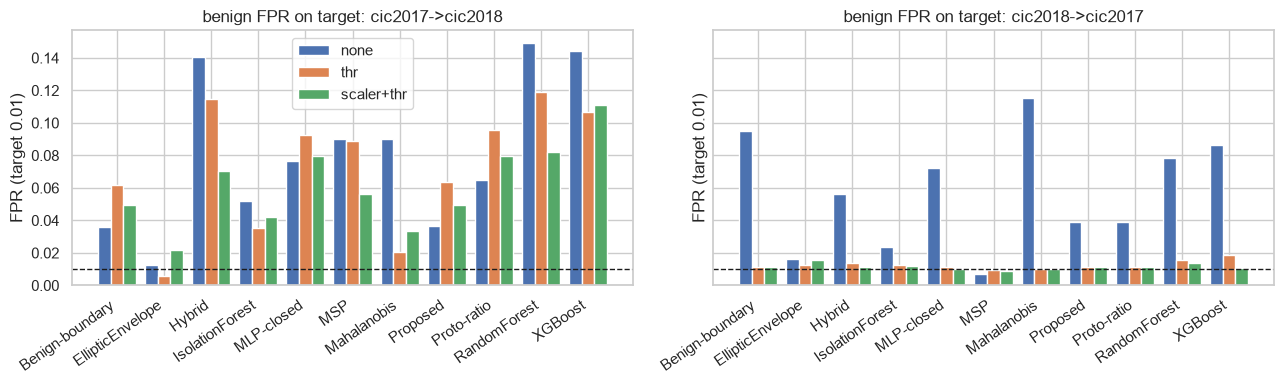

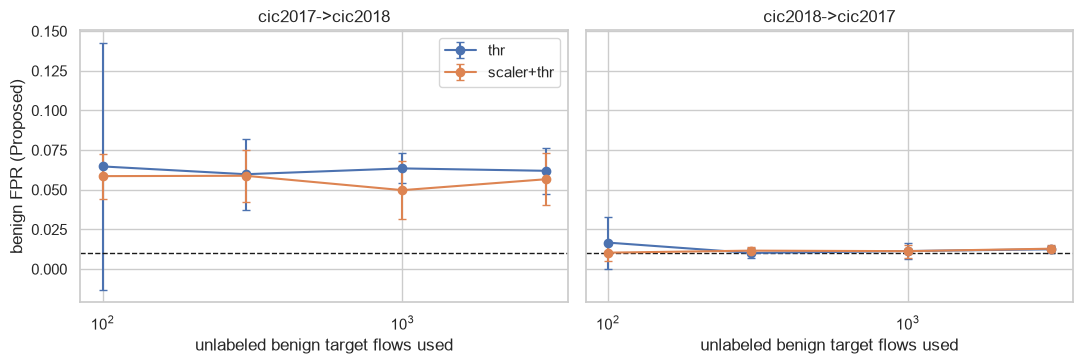


G3 PRE-REGISTERED CRITERIA (Proposed detector)


,criterion,passed,values
0,C1 benign FPR after recalibration <= 2x nomina...,False,"{'cic2017->cic2018': 0.0497, 'cic2018->cic2017..."
1,C2 SSH transfer AUROC within 0.05 of in-source...,False,"{'cic2017->cic2018': 0.5994955569398496, 'cic2..."
2,C3 recalibration reduces FPR error in the wors...,False,"{'cic2017->cic2018': (0.026299999999999997, 0...."


G3 verdict: Not achieved

rank of each method after recalibration by |FPR - 0.01| (1 = closest to the target)


direction,cic2017->cic2018,cic2018->cic2017
method,,
Benign-boundary,4.0,7.5
EllipticEnvelope,1.0,11.0
Hybrid,7.0,6.0
IsolationForest,3.0,9.0
MLP-closed,9.0,1.5
MSP,6.0,4.0
Mahalanobis,2.0,1.5
Proposed,5.0,5.0
Proto-ratio,8.0,7.5


In [14]:
# ============ 6b. C2 tables, statistics, figures and verdict ============

# Benign FPR on the target network per mode
MODES = ['none', 'thr', 'scaler+thr']
main = RC[(RC['mode'].isin(['none', 'in_source'])) | (RC.n_cal == C2_MAIN_NCAL)]

drift = (main[main.kind == 'benign_fpr'].groupby(['direction', 'method', 'mode'])['fpr'].mean()
         .unstack('mode')[MODES].round(4))
print(f'BENIGN FPR ON THE TARGET NETWORK (nominal {FPR_TARGET}); sample size for thr / scaler+thr = {C2_MAIN_NCAL}')
save_table(drift, 'g3_benign_fpr_by_mode')

sd = (main[main.kind == 'benign_fpr'].groupby(['direction', 'method', 'mode'])['fpr'].std().unstack('mode')[MODES].round(4))
print('\nstd over seeds')
display(sd)

# SSH transfer (the only family in both datasets)
ssh = main[(main.kind == 'attack') & (main.family == SHARED_FAMILY)]
ref = ssh[ssh['mode'] == 'in_source'].assign(src=lambda d: d.direction.str.split('->').str[0]).groupby(['src', 'method'])['auroc'].mean()
cross = ssh[ssh['mode'] != 'in_source'].groupby(['direction', 'method', 'mode'])['auroc'].mean().unstack('mode')[MODES]
cross.insert(0, 'in_source', [ref.get((i[0].split('->')[0], i[1]), np.nan) for i in cross.index])
cross['drop_none'] = cross['in_source'] - cross['none']
cross['drop_recal'] = cross['in_source'] - cross['scaler+thr']
print(f'\nSSH TRANSFER AUROC (SSH is the only family in both sources); drop = in-source minus cross-dataset')
save_table(cross.round(4), 'g3_ssh_transfer')

tpr = (ssh[ssh['mode'] != 'in_source'].groupby(['direction', 'method', 'mode'])['tpr'].mean().unstack('mode')[MODES].round(4))
print('\nSSH detection rate (TPR) at each mode threshold')
display(tpr)

allfam = (main[(main.kind == 'attack') & (main['mode'] != 'in_source')].groupby(['direction', 'family', 'method', 'mode'])['auroc'].mean().unstack('mode')[MODES].round(4))
print('\nAUROC for every target family (unseen-in-source families are a G1-style test, not part of G3 criteria)')
save_table(allfam, 'g3_all_family_transfer')

# Does a larger calibration sample help?
sw = RC[(RC.method == 'Proposed') & (RC.kind == 'benign_fpr') & (RC.mode != 'none')]
swt = sw.groupby(['direction', 'mode', 'n_cal'])['fpr'].agg(['mean', 'std']).round(4)
print('\nSIZE SWEEP, Proposed: benign FPR vs size of the unlabeled benign target sample')
save_table(swt, 'g3_ncal_sweep')

# Wilcoxon test: does recalibration reduce the FPR error?
pb = main[(main.method == 'Proposed') & (main.kind == 'benign_fpr')]
piv = pb.pivot_table(index=['direction', 'seed'], columns='mode', values='fpr')
err = (piv[MODES] - FPR_TARGET).abs()
G3R = dict(main_ncal=C2_MAIN_NCAL)
for mode in ['thr', 'scaler+thr']:
    try:
        p = float(stats.wilcoxon(err['none'], err[mode], alternative='greater')[1])
    except Exception:
        p = np.nan
    G3R[f'wilcoxon_p_none_vs_{mode}'] = p
    print(f'Wilcoxon (one-sided), |FPR - 1%| none > {mode}: p = {p:.4f}  (n = {len(err)} paired runs; mean error {err["none"].mean():.4f} -> {err[mode].mean():.4f})')

# ---- figures ----
def _save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()
dirs = list(drift.index.get_level_values(0).unique())
fig, axs = plt.subplots(1, len(dirs), figsize=(6.5 * len(dirs), 4), sharey=True)
axs = np.atleast_1d(axs)
for ax, dname in zip(axs, dirs):
    dd = drift.loc[dname]
    xs = np.arange(len(dd))
    w = 0.27
    for i, mode in enumerate(MODES):
        ax.bar(xs + (i - 1) * w, dd[mode].values, w, label=mode)
    ax.axhline(FPR_TARGET, color='k', ls='--', lw=1)
    ax.set_xticks(xs)
    ax.set_xticklabels(dd.index, rotation=35, ha='right')
    ax.set_title(f'benign FPR on target: {dname}')
    ax.set_ylabel('FPR (target 0.01)')
axs[0].legend()
_save('g3_recalibration_fpr.png')

fig, axs = plt.subplots(1, len(dirs), figsize=(5.5 * len(dirs), 3.8), sharey=True)
axs = np.atleast_1d(axs)
for ax, dname in zip(axs, dirs):
    for mode in ['thr', 'scaler+thr']:
        q = sw[(sw.direction == dname) & (sw['mode'] == mode)].groupby('n_cal')['fpr'].agg(['mean', 'std'])
        ax.errorbar(q.index, q['mean'], yerr=q['std'].fillna(0), marker='o', capsize=3, label=mode)
    ax.axhline(FPR_TARGET, color='k', ls='--', lw=1)
    ax.set_xscale('log')
    ax.set_xlabel('unlabeled benign target flows used')
    ax.set_title(dname)
axs[0].set_ylabel('benign FPR (Proposed)')
axs[0].legend()
_save('g3_ncal_sweep.png')

# ---- pre-registered criteria (Proposed detector) ----
crit = []
pd_ = drift.xs('Proposed', level='method')
c1 = {d_: float(pd_.loc[d_, 'scaler+thr']) for d_ in pd_.index}
crit.append(('C1 benign FPR after recalibration <= 2x nominal, both directions', all(v <= 2 * FPR_TARGET for v in c1.values()), c1))
pc = cross.xs('Proposed', level='method')
c2 = {d_: float(pc.loc[d_, 'drop_recal']) for d_ in pc.index}
crit.append((f'C2 {SHARED_FAMILY.upper()} transfer AUROC within 0.05 of in-source after recalibration, both directions', all(v <= 0.05 for v in c2.values()), c2))
e_none = (pd_['none'] - FPR_TARGET).abs()
e_rec = (pd_['scaler+thr'] - FPR_TARGET).abs()
worst = e_none.idxmax()
c3 = {d_: (float(e_none[d_]), float(e_rec[d_])) for d_ in pd_.index}
crit.append(('C3 recalibration reduces FPR error in the worst direction and does not worsen the other by more than 0.002',
             bool(e_rec[worst] < e_none[worst] and all(e_rec[d_] <= e_none[d_] + 0.002 for d_ in pd_.index)), c3))
CRIT3 = pd.DataFrame([dict(criterion=a, passed=b, values=str(c)) for a, b, c in crit])
print('\nG3 PRE-REGISTERED CRITERIA (Proposed detector)')
display(CRIT3)
G3R.update(passed=int(CRIT3.passed.sum()), total=len(CRIT3), verdict=('Achieved' if CRIT3.passed.all() else 'Partly achieved' if CRIT3.passed.any() else 'Not achieved'))
print('G3 verdict:', G3R['verdict'])
# Rank methods by how close they get to 1% FPR
rk = (drift['scaler+thr'] - FPR_TARGET).abs().unstack('direction').rank()
print('\nrank of each method after recalibration by |FPR - 0.01| (1 = closest to the target)')
display(rk)
json.dump(G3R, open(OUT / 'g3_summary.json', 'w'), indent=2, default=str)

**Findings - C2**
* **Verdict: Not achieved (0/3).**
* 2018 → 2017 works: Proposed FPR 3.9% → **1.1%**; all methods land at 0.9-1.6%.
* 2017 → 2018 does not: 3.6% → 5.0%. More samples (100 → 3000) do not help, so the cause is drift *between days*, not sample size.
* Rescaling hurts SSH detection of the MLP scores (AUROC 0.69 → 0.40 and 0.81 → 0.70). Random Forest and Hybrid keep ~0.98 (2017 → 2018).
* Wilcoxon: not significant (p = 0.58 and 0.22).
* We then found four design bugs (Section 6c). C2 stays reported; C3 is the corrected test.

## 6c. Protocol C3: corrected test (written before running)
**Bugs found in C2:**
1. Calibration (target train days) and evaluation (target test days) were different days, so time drift was mixed in. Even in-source, 2018 test days give 9.9-11.7% FPR.
2. The open-set head kept its source values after rescaling.
3. The same sample both fitted the scaler and set the threshold.
4. Attacks were compared with benign flows from other days.

**C3 design:**
* Calibration sample (n = 1000) split in half: one half adapts the model, the other sets the threshold.
* Two designs: `random` (no time drift) and `warmup` (first flows in time).
* Modes: `none`, `thr`, `scaler+thr`, `scaler+head+thr` (head also re-fitted).
* Robustness: 0% or 5% attacks hidden in the "benign" sample.
* Attack AUROC also against benign from the **same files** (`same_file`).

**Primary setup (fixed now):** Proposed, `scaler+head+thr`, all features, `random`, 0% contamination, n = 1000, `same_file`.

**Criteria (same thresholds as C2):**
* **C1:** FPR ≤ 2% both directions.
* **C2:** SSH AUROC drop ≤ 0.05 both directions.
* **C3:** reduces |FPR - 1%| vs `none` in the worst direction; other direction not worse by > 0.002.
* **C4 (new):** with `warmup`, FPR ≤ max(2%, 2 × in-source test FPR).

*Run-time note:* "stable features" and 1% contamination were dropped, and the runner fits RF + MLP only. The primary setup and criteria are unchanged. The same runner also produces the v3 rows (Section 6d).

In [15]:
# ============ 6c. Helpers for the corrected protocol C3 ============

# Open-set scores that come from the MLP
OS_METHODS = ('Benign-boundary', 'Proto-ratio', 'Proposed', 'Mahalanobis', 'MLP-closed', 'MSP')

# Re-fit benign prototype and calibration of the open-set head on target benign flows
def recal_head(G, cal_df):
    """Unlabeled-benign adaptation of the open-set head: benign prototype, benign covariance and the
    median/MAD calibration are re-estimated on target benign embeddings. Attack prototypes and MLP
    weights are unchanged. Needs no target attack labels."""
    if not hasattr(G, 'mlp'):
        return G
    Z, _ = G.mlp.forward_np(G.pre.transform_np(cal_df[G.feats].to_numpy(np.float32)))
    O = copy.deepcopy(G.os)
    O.mu = O.mu.copy()
    O.mu[0] = Z.mean(0)
    O.Pinv = np.linalg.inv(np.cov(Z.T) + 1e-3 * np.eye(Z.shape[1]))
    raw = O._raw(Z)
    for key in ('boundary', 'proto'):
        med = np.median(raw[key])
        O.cal[key] = (med, np.median(np.abs(raw[key] - med)) * 1.4826 + 1e-6)
    H = copy.copy(G)
    H.os = O
    return H

# Drop the features that shift most between datasets (KS test)
def shift_stable_feats(trS, cal_fit, feats, drop_frac=0.25, n_max=20000, seed=0):
    """Rank features by Kolmogorov-Smirnov shift between SOURCE train benign and the unlabeled TARGET
    benign sample (both in source-fitted preprocessing) and drop the most-shifted `drop_frac`."""
    b = trS[trS.family == 'benign']
    if len(b) > n_max:
        b = b.sample(n_max, random_state=seed)
    pre = Preproc(feats).fit(b[feats].to_numpy(np.float32))
    A = pre.transform_np(b[feats].to_numpy(np.float32))
    B = pre.transform_np(cal_fit[feats].to_numpy(np.float32))
    ks = pd.Series([stats.ks_2samp(A[:, j], B[:, j]).statistic for j in range(A.shape[1])], index=pre.names)
    keep = list(ks.sort_values().index[:int(np.ceil(len(ks) * (1 - drop_frac)))])
    return keep, ks

# Wilson confidence interval for a rate
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

# Draw the calibration sample (random or first flows in time)
def draw_cal(Tben, design, n, seed):
    """'random': n random target benign flows (no temporal drift between calibration and evaluation).
       'warmup': the first n target benign flows in time (deployment-realistic: calibrate at switch-on)."""
    n = min(n, len(Tben) // 2)
    if design == 'random':
        pos = np.random.RandomState(1000 + seed).choice(len(Tben), n, replace=False)
    else:
        pos = np.argsort(Tben['t'].to_numpy(), kind='mergesort')[:n]
    return Tben.index.to_numpy()[pos]

# Re-fit the Hybrid percentile maps on target benign flows
def recal_hybrid(G, cal_df):
    """v3: rebuild the hybrid benign-percentile maps from unlabeled target benign flows (after the scaler / head update)."""
    if getattr(G, 'hyb', None) is None:
        return G
    H = copy.copy(G)
    H.hyb = None
    Sc = H.score_scaled(H.pre.transform_np(cal_df[H.feats].to_numpy(np.float32)))
    H.hyb = make_hyb({m: Sc[m] for m in HYB_PARTS})
    return H

In [16]:
# ============ 6c/6d. One runner for protocol C3 (v2) and the v3 method ============
# featset 'all' = original z-score preprocessing, 'quantile' = v3 QPreproc. Methods include 'Hybrid' (v3).
# designs: 'random' / 'warmup' (as in v2) and 'daily' (every target day is recalibrated on its own first
# benign flows; a day with too few benign flows keeps the previous day's calibration).
# Expected run time: about 1-1.5 h on a laptop.
C3_SEEDS, C3_NCAL = SEEDS, 1000
C3_DESIGNS = ('random', 'warmup', 'daily')
C3_ALPHAS = (0.0, 0.05)  # contamination test on the random design only
DAILY_N, DAILY_MIN = 1000, 200
C3_VARIANTS = {'all': 'zscore', 'quantile': 'quantile'}
C3_WHICH = ('RF', 'MLP')
C3_MODES = ('thr', 'scaler+thr', 'scaler+head+thr')

# Split the calibration sample in two halves
def _halves(idx, seed):
    p = np.random.RandomState(3000 + seed).permutation(len(idx))
    h = len(idx) // 2
    return idx[p[:h]], idx[p[h:]]

# Apply one adaptation mode to a fitted model
def adapt(F, cal_fit, mode):
    if mode == 'thr':
        return F
    G = retarget(F, cal_fit)
    if mode == 'scaler+head+thr':
        G = recal_head(G, cal_fit)
    return recal_hybrid(G, cal_fit)

# Thresholds from the second half of the calibration sample
def _cal_taus(G, cal_thr):
    return {m: float(np.quantile(s, 1 - FPR_TARGET)) for m, s in G.score(cal_thr).items()}

# Daily design: calibration flows for each target day
def daily_plan(Tall, is_ben):
    names = list(Tall.file.unique())
    files = sorted(names, key=lambda n: file_rank(n, names))
    tb = Tall[is_ben]
    fallback = tb.index.to_numpy()[np.argsort(tb['t'].to_numpy(), kind='mergesort')[:min(DAILY_N, len(tb) // 2)]]
    plan, prev = {}, None
    for f in files:
        b = tb[tb.file == f]
        if len(b) >= 2 * DAILY_MIN:
            prev = b.index.to_numpy()[np.argsort(b['t'].to_numpy(), kind='mergesort')[:min(DAILY_N, len(b) // 2)]]
        plan[f] = prev if prev is not None else fallback  # fallback = earliest target benign flows (only before the first usable day)
    return plan

# Scores minus the day-specific threshold
def margins_daily(F, mode, Tall, plan, seed, S0):
    groups = {}
    for f, idx in plan.items():
        groups.setdefault((int(idx[0]), len(idx)), [idx, []])[1].append(f)
    out = None
    for idx, files in groups.values():
        fit_i, thr_i = _halves(idx, seed)
        G = adapt(F, Tall.loc[fit_i], mode)
        taus = _cal_taus(G, Tall.loc[thr_i])
        rows_ = Tall.file.isin(files).to_numpy()
        Sc = {m: s[rows_] for m, s in S0.items()} if mode == 'thr' else G.score(Tall[rows_])
        if out is None:
            out = {m: np.full(len(Tall), np.nan) for m in Sc}
        for m in out:
            out[m][rows_] = np.asarray(Sc[m], dtype=np.float64) - taus[m]
    return out

# Add result rows (benign FPR and attack metrics)
def _emit(rows, base, Mg, ev_ben, is_eval_atk, fam, same, atkS):
    """Mg = margins (score minus the threshold that applies to that flow); a flow is flagged when margin > 0."""
    n_ = int(ev_ben.sum())
    for m, mg in Mg.items():
        k = int((mg[ev_ben] > 0).sum())
        lo, hi = wilson(k, n_)
        rows.append(dict(base, kind='benign_fpr', family='benign', method=m, fpr=k / max(n_, 1), fpr_lo=lo, fpr_hi=hi))
        for f, fm in fam.items():
            atk = is_eval_atk & fm
            if atk.sum() == 0:
                continue
            for ev_name, bmask in (('all_benign', ev_ben), ('same_file', ev_ben & same[f])):
                if bmask.sum() < 50:
                    continue
                mk = bmask | atk
                r = dict(base, kind='attack', family=f, eval=ev_name, seen_in_source=f in atkS, method=m)
                r.update(binary_metrics(atk[mk].astype(int), mg[mk], 0.0))
                rows.append(r)

# Run every direction, seed, feature set, design and mode
def run_C3(seeds=C3_SEEDS):
    rows = []
    for S, T in [(SOURCES[0], SOURCES[1]), (SOURCES[1], SOURCES[0])]:
        dirn = f'{S}->{T}'
        trS = M[(M.source == S) & (M.split == 'train')]
        vaS = M[(M.source == S) & (M.split == 'val')]
        teS = M[(M.source == S) & (M.split == 'test')]
        atkS = [a for a in ATTACKS if (trS.family == a).sum() >= 50]
        classes = ['benign'] + atkS
        Tall = M[M.source == T]
        is_ben = (Tall.family == 'benign').to_numpy()
        Tben = Tall[is_ben]
        famsT = [a for a in ATTACKS if (Tall.family == a).sum() >= 50]
        fam = {f: (Tall.family == f).to_numpy() for f in famsT}
        same = {f: Tall.file.isin(list(set(Tall.loc[Tall.family == f, 'file']))).to_numpy() for f in famsT}
        plan = daily_plan(Tall, is_ben)
        daily_cal = np.unique(np.concatenate(list(plan.values())))
        for seed in seeds:
            set_seed(seed)
            rs = np.random.RandomState(2000 + seed)
            atk_pos = np.where(~is_ben)[0]
            rs.shuffle(atk_pos)
            reserve_pos = atk_pos[:int(0.2 * len(atk_pos))]
            is_eval_atk = ~is_ben
            is_eval_atk[reserve_pos] = False  # 20 % of target attacks: contamination pool, never evaluated
            cal_sets = {d: draw_cal(Tben, d, C3_NCAL, seed) for d in ('random', 'warmup')}
            for fs, pk in C3_VARIANTS.items():
                F = fit_detectors(trS, vaS, FEATS, classes, seed, C3_WHICH, HIDDEN, {}, pre_kind=pk)
                tau_src = tau_from_val(F.score(vaS), (vaS.family == 'benign').values)
                base0 = dict(direction=dirn, seed=seed, featset=fs, n_feats=len(F.pre.names))
                Ss = F.score(teS)
                sb = (teS.family == 'benign').to_numpy()  # in-source reference (source test window)
                for m, s in Ss.items():
                    s = np.asarray(s, dtype=np.float64)
                    k = int((s[sb] > tau_src[m]).sum())
                    lo, hi = wilson(k, int(sb.sum()))
                    rows.append(dict(base0, design='source', mode='in_source', alpha=0.0, kind='benign_fpr', family='benign',
                                     method=m, fpr=k / max(int(sb.sum()), 1), fpr_lo=lo, fpr_hi=hi))
                    for f in atkS:
                        mk = sb | (teS.family == f).to_numpy()
                        r = dict(base0, design='source', mode='in_source', alpha=0.0, kind='attack', family=f, eval='source_test',
                                 seen_in_source=True, method=m)
                        r.update(binary_metrics((teS.family[mk] == f).astype(int).values, s[mk], tau_src[m]))
                        rows.append(r)
                S0 = {m: np.asarray(s, dtype=np.float64) for m, s in F.score(Tall).items()}
                for design in C3_DESIGNS:
                    if design == 'daily':
                        ev_ben = is_ben & ~Tall.index.isin(daily_cal)
                        b = dict(base0, design='daily', n_cal=int(len(daily_cal)), alpha=0.0)
                        _emit(rows, dict(b, mode='none'), {m: s - tau_src[m] for m, s in S0.items()}, ev_ben, is_eval_atk, fam, same, atkS)
                        for mode in C3_MODES:
                            _emit(rows, dict(b, mode=mode), margins_daily(F, mode, Tall, plan, seed, S0), ev_ben, is_eval_atk, fam, same, atkS)
                        continue
                    cal_idx = cal_sets[design]
                    ev_ben = is_ben & ~Tall.index.isin(cal_idx)
                    fit0, thr0 = _halves(cal_idx, seed)
                    b = dict(base0, design=design, n_cal=len(cal_idx))
                    _emit(rows, dict(b, mode='none', alpha=0.0), {m: s - tau_src[m] for m, s in S0.items()}, ev_ben, is_eval_atk, fam, same, atkS)
                    for alpha in (C3_ALPHAS if design == 'random' else (0.0,)):
                        n_c = int(round(alpha * len(fit0)))
                        cf, ct = Tall.loc[fit0], Tall.loc[thr0]
                        if n_c:
                            take = Tall.iloc[np.random.RandomState(4000 + seed).choice(reserve_pos, 2 * n_c, replace=False)]
                            cf = pd.concat([cf.iloc[n_c:], take.iloc[:n_c]])
                            ct = pd.concat([ct.iloc[n_c:], take.iloc[n_c:]])
                        for mode in C3_MODES:
                            G = adapt(F, cf, mode)
                            taus = _cal_taus(G, ct)
                            Sc = S0 if mode == 'thr' else {m: np.asarray(s, dtype=np.float64) for m, s in G.score(Tall).items()}
                            _emit(rows, dict(b, mode=mode, alpha=alpha), {m: Sc[m] - taus[m] for m in Sc}, ev_ben, is_eval_atk, fam, same, atkS)
                del F
                gc.collect()
            print(f'{dirn} seed {seed} done')
    return pd.DataFrame(rows)

# Run C3
t0 = time.time()
RC3 = run_C3()
RC3.to_csv(TAB_DIR / 'results_C3.csv', index=False)
print(f'Protocol C3 (v2 + v3 rows) finished in {(time.time() - t0) / 60:.1f} min | rows: {len(RC3):,}')

cic2017->cic2018 seed 0 done
cic2017->cic2018 seed 1 done
cic2017->cic2018 seed 2 done
cic2017->cic2018 seed 3 done
cic2017->cic2018 seed 4 done
cic2018->cic2017 seed 0 done
cic2018->cic2017 seed 1 done
cic2018->cic2017 seed 2 done
cic2018->cic2017 seed 3 done
cic2018->cic2017 seed 4 done
Protocol C3 (v2 + v3 rows) finished in 23.9 min | rows: 12,480


In [17]:
# ============ 6c. C3 tables, error decomposition and verdict ============

# Primary configuration (fixed before the run)
PRIM = dict(method='Proposed', mode='scaler+head+thr', featset='all', design='random', alpha=0.0)
fpr_tab = (RC3[(RC3.kind == 'benign_fpr') & (RC3.alpha == 0) & (RC3.method == 'Proposed')]
           .groupby(['direction', 'featset', 'design', 'mode'])['fpr'].agg(['mean', 'std']).round(4))
print('PROPOSED: target benign FPR (alpha = 0). in_source = source test window (temporal ceiling)')
save_table(fpr_tab, 'g3v2_fpr_proposed')

allm = (RC3[(RC3.kind == 'benign_fpr') & (RC3.alpha == 0) & (RC3.featset == 'all') & (RC3.design == 'random')]
        .groupby(['direction', 'method', 'mode'])['fpr'].mean().unstack('mode').round(4))
print('\nALL METHODS: target benign FPR, design=random, features=all')
save_table(allm, 'g3v2_fpr_all_methods')

# How much of the FPR error is time drift vs dataset shift?
dec = (RC3[(RC3.kind == 'benign_fpr') & (RC3.alpha == 0) & (RC3.method == 'Proposed') & (RC3.featset == 'all')
           & (RC3['mode'] == PRIM['mode'])].groupby(['direction', 'design'])['fpr'].mean().unstack('design'))
dec['in_source'] = RC3[(RC3['mode'] == 'in_source') & (RC3.kind == 'benign_fpr') & (RC3.method == 'Proposed')
                       & (RC3.featset == 'all')].groupby('direction')['fpr'].mean()
dec['err_cross_dataset'] = (dec['random'] - FPR_TARGET).abs()
dec['err_temporal_extra'] = (dec['warmup'] - FPR_TARGET).abs() - dec['err_cross_dataset']
print('\nFPR ERROR DECOMPOSITION (Proposed, primary mode)')
save_table(dec.round(4), 'g3v2_decomposition')

# Select rows by column values
def _sel(d, **kw):
    for k, v in kw.items():
        d = d[d[k] == v]
    return d

# SSH transfer AUROC
ssh_rows = _sel(RC3, kind='attack', family=SHARED_FAMILY, alpha=0.0)
ins = _sel(ssh_rows, mode='in_source').groupby(['direction', 'featset', 'method'])['auroc'].mean()
xs = (ssh_rows[ssh_rows['mode'] != 'in_source']
      .groupby(['direction', 'featset', 'design', 'eval', 'method', 'mode'])['auroc'].mean().unstack('mode'))
xs.insert(0, 'in_source', [ins.get((i[0], i[1], i[4]), np.nan) for i in xs.index])
print('\nSSH TRANSFER AUROC (only family present in both sources; in_source = source test split)')
save_table(xs.round(4), 'g3v2_ssh_auroc')

# Robustness: attacks mixed into the "benign" calibration sample
base_c = _sel(RC3, method='Proposed', featset='all', design='random')
base_c = base_c[base_c['mode'].isin(['thr', 'scaler+head+thr'])]
c_fpr = _sel(base_c, kind='benign_fpr').assign(metric='benign_fpr', val=lambda d: d.fpr)
c_tpr = _sel(base_c, kind='attack', family=SHARED_FAMILY, eval='same_file').assign(metric='ssh_tpr', val=lambda d: d.tpr)
cont = (pd.concat([c_fpr, c_tpr]).groupby(['direction', 'mode', 'metric', 'alpha'])['val'].mean().unstack('alpha').round(4))
print('\nCONTAMINATED CALIBRATION SAMPLE (Proposed): FPR and SSH TPR vs attack fraction in the "benign" sample')
save_table(cont, 'g3v2_contamination')

# ---- pre-registered verdict (thresholds from the 6c markdown) ----
P = _sel(RC3, method='Proposed', featset='all', alpha=0.0)
fpr_p = _sel(P, kind='benign_fpr', design='random', mode=PRIM['mode']).groupby('direction')['fpr'].mean()
fpr_n = _sel(P, kind='benign_fpr', design='random', mode='none').groupby('direction')['fpr'].mean()
fpr_w = _sel(P, kind='benign_fpr', design='warmup', mode=PRIM['mode']).groupby('direction')['fpr'].mean()
fpr_in = _sel(P, kind='benign_fpr', mode='in_source').groupby('direction')['fpr'].mean()  # keyed by S->T, value = source test FPR
auc_x = _sel(P, kind='attack', family=SHARED_FAMILY, design='random', mode=PRIM['mode'], eval='same_file').groupby('direction')['auroc'].mean()
auc_in = _sel(P, kind='attack', family=SHARED_FAMILY, mode='in_source').groupby('direction')['auroc'].mean()
drop = {d_: float(auc_in[d_] - auc_x[d_]) for d_ in auc_x.index}
e_n, e_p = (fpr_n - FPR_TARGET).abs(), (fpr_p - FPR_TARGET).abs()
worst = e_n.idxmax()
ceil = {d_: max(2 * FPR_TARGET, 2 * float(fpr_in[d_])) for d_ in fpr_w.index}

# Criteria C1-C4
crit = [
    ('C1 primary target FPR <= 0.02, both directions', bool((fpr_p <= 2 * FPR_TARGET).all()), fpr_p.round(4).to_dict()),
    ('C2 primary SSH AUROC drop <= 0.05 (same_file), both directions', bool(all(v <= 0.05 for v in drop.values())), {k: round(v, 4) for k, v in drop.items()}),
    ('C3 primary reduces |FPR-1%| in worst direction, other not worse by > 0.002',
     bool(e_p[worst] < e_n[worst] and all(e_p[d_] <= e_n[d_] + 0.002 for d_ in e_p.index)), {d_: (round(e_n[d_], 4), round(e_p[d_], 4)) for d_ in e_p.index}),
    ('C4 warmup FPR <= max(0.02, 2x in-source test FPR), both directions', bool(all(fpr_w[d_] <= ceil[d_] for d_ in fpr_w.index)),
     {d_: (round(float(fpr_w[d_]), 4), round(ceil[d_], 4)) for d_ in fpr_w.index}),
]
CRIT3V2 = pd.DataFrame([dict(criterion=a, passed=b, values=str(c)) for a, b, c in crit])
print('\nG3 (C3 protocol) PRE-REGISTERED CRITERIA')
display(CRIT3V2)
G3V2 = dict(passed=int(CRIT3V2.passed.sum()), total=len(CRIT3V2),
            verdict='Achieved' if CRIT3V2.passed.all() else 'Partly achieved' if CRIT3V2.passed.any() else 'Not achieved')
print('G3 verdict (C3):', G3V2['verdict'], '| original C2 verdict stays in the report:', G3R['verdict'])
json.dump(G3V2, open(OUT / 'g3v2_summary.json', 'w'), indent=2, default=str)

PROPOSED: target benign FPR (alpha = 0). in_source = source test window (temporal ceiling)


mean     std
direction        featset  design mode                           
cic2017->cic2018 all      daily  none             0.0085  0.0039
                                 scaler+head+thr  0.0148  0.0030
                                 scaler+thr       0.0152  0.0023
                                 thr              0.0112  0.0035
                          random none             0.0092  0.0043
                                 scaler+head+thr  0.0111  0.0032
                                 scaler+thr       0.0124  0.0046
                                 thr              0.0134  0.0016
                          source in_source        0.0117  0.0045
                          warmup none             0.0093  0.0044
                                 scaler+head+thr  0.0159  0.0169
                                 scaler+thr       0.0288  0.0156
                                 thr              0.0425  0.0226
                 quantile daily  none             0.0004  0.0003
                                 scaler+head+thr  0.0130  0.0016
                                 scaler+thr       0.0129  0.0015
                                 thr              0.0115  0.0012
                          random none             0.0003  0.0003
                                 scaler+head+thr  0.0123  0.0091
                                 scaler+thr       0.0122  0.0070
                                 thr              0.0140  0.0037
                          source in_source        0.0077  0.0007
                          warmup none             0.0003  0.0003
                                 scaler+head+thr  0.0410  0.0089
                                 scaler+thr       0.0421  0.0088
                                 thr              0.0658  0.0205
cic2018->cic2017 all      daily  none             0.0330  0.0099
                                 scaler+head+thr  0.0213  0.0095
                                 scaler+thr       0.0118  0.0045
                                 thr              0.0226  0.0050
                          random none             0.0322  0.0097
                                 scaler+head+thr  0.0102  0.0058
                                 scaler+thr       0.0177  0.0104
                                 thr              0.0128  0.0069
                          source in_source        0.0896  0.0129
                          warmup none             0.0325  0.0098
                                 scaler+head+thr  0.0475  0.0191
                                 scaler+thr       0.0128  0.0145
                                 thr              0.0427  0.0128
                 quantile daily  none             0.0451  0.0310
                                 scaler+head+thr  0.0204  0.0030
                                 scaler+thr       0.0169  0.0032
                                 thr              0.0178  0.0009
                          random none             0.0447  0.0312
                                 scaler+head+thr  0.0122  0.0025
                                 scaler+thr       0.0123  0.0060
                                 thr              0.0111  0.0066
                          source in_source        0.0898  0.0096
                          warmup none             0.0450  0.0313
                                 scaler+head+thr  0.0511  0.0075
                                 scaler+thr       0.0361  0.0128
                                 thr              0.0308  0.0019


ALL METHODS: target benign FPR, design=random, features=all


mode                                none  scaler+head+thr  scaler+thr     thr
direction        method                                                      
cic2017->cic2018 Benign-boundary  0.0091           0.0110      0.0124  0.0136
                 Hybrid           0.0357           0.0063      0.0076  0.0075
                 MLP-closed       0.0189           0.0125      0.0125  0.0146
                 MSP              0.0243           0.0124      0.0124  0.0151
                 Mahalanobis      0.0748           0.0116      0.0105  0.0121
                 Proposed         0.0092           0.0111      0.0124  0.0134
                 Proto-ratio      0.0148           0.0128      0.0134  0.0144
                 RandomForest     0.0400           0.0108      0.0108  0.0100
cic2018->cic2017 Benign-boundary  0.0840           0.0086      0.0099  0.0122
                 Hybrid           0.0425           0.0096      0.0131  0.0119
                 MLP-closed       0.0615           0.0119      0.0119  0.0126
                 MSP              0.0077           0.0118      0.0118  0.0116
                 Mahalanobis      0.1028           0.0107      0.0105  0.0133
                 Proposed         0.0322           0.0102      0.0177  0.0128
                 Proto-ratio      0.0322           0.0164      0.0181  0.0128
                 RandomForest     0.0598           0.0154      0.0154  0.0126


FPR ERROR DECOMPOSITION (Proposed, primary mode)


design,daily,random,warmup,in_source,err_cross_dataset,err_temporal_extra
direction,,,,,,
cic2017->cic2018,0.0148,0.0111,0.0159,0.0117,0.0011,0.0048
cic2018->cic2017,0.0213,0.0102,0.0475,0.0896,0.0002,0.0373


... (4 outputs left out)


G3 (C3 protocol) PRE-REGISTERED CRITERIA


,criterion,passed,values
0,"C1 primary target FPR <= 0.02, both directions",True,"{'cic2017->cic2018': 0.0111, 'cic2018->cic2017..."
1,"C2 primary SSH AUROC drop <= 0.05 (same_file),...",False,"{'cic2017->cic2018': 0.7654, 'cic2018->cic2017..."
2,C3 primary reduces |FPR-1%| in worst direction...,True,"{'cic2017->cic2018': (np.float64(0.0008), np.f..."
3,"C4 warmup FPR <= max(0.02, 2x in-source test F...",True,"{'cic2017->cic2018': (0.0159, 0.0234), 'cic201..."


G3 verdict (C3): Partly achieved | original C2 verdict stays in the report: Not achieved


C:\Users\DELL\AppData\Local\Temp\ipykernel_7728\1680663412.py:77: ResourceWarning: unclosed file <_io.TextIOWrapper name='D:\\Projects\\FAST-NUCES\\Cnet\\CNET-Project\\Outputs\\g3v2_summary.json' mode='w' encoding='cp1252'>
  json.dump(G3V2, open(OUT / 'g3v2_summary.json', 'w'), indent=2, default=str)


**Findings - C3**
* **Verdict: Partly achieved (3/4).** C1, C3, C4 pass; C2 fails.
* **C1:** FPR back to **1.11%** (2017 → 2018) and **1.02%** (2018 → 2017) with 1,000 unlabeled benign flows, no attack labels.
* **The error is time drift, not dataset shift:** dataset part 0.11 / 0.02 points, time part 0.48 / 3.73 points. Even in-source, 2018 test FPR is 8.96%.
* **Robust:** with 5% attacks in the calibration sample, FPR stays 1.09-1.13%.
* **C2 fails:** SSH AUROC drops by 0.77 (2017 → 2018). At the new threshold Proposed catches only ~0.1% of SSH flows. Section 8c (T1) explains why.

## 6d. v3 method (written before running)
**Why:** C3 showed (i) most FPR error is time drift inside the target, and (ii) the MLP's SSH knowledge does not transfer, because it relies on the most-shifted features (Section 8c).

**Changes:**
1. **Daily recalibration:** each target day is recalibrated on its own first benign flows. Days with < 400 benign flows reuse the previous day.
2. **Quantile preprocessing (`QPreproc`):** each feature becomes a percentile of benign traffic *of its own network*.
3. **Hybrid detector:** max of the benign percentiles of Proposed and Random Forest (RF relied on less-shifted features).
4. **Data cleaning:** label conflicts and cross-dataset duplicates removed (Section 3, step 3b).

**Primary setup (fixed now):** Hybrid, quantile, `scaler+head+thr`, n = 1000, 0% contamination.

**Criteria (same thresholds):**
* **C1:** `random` design FPR ≤ 2% both directions.
* **C2:** `random`, `same_file`: SSH AUROC drop ≤ 0.05 both directions.
* **C3:** reduces |FPR - 1%| in the worst direction; other not worse by > 0.002.
* **C4:** `daily` design FPR ≤ max(2%, 2 × in-source test FPR).

Other variants (Proposed / RF / Hybrid × z-score / quantile) are secondary.

**Limitation:** v3 was designed after seeing v2 results on the same data, so its numbers are less independent. All versions are reported.

In [18]:
# ============ 6d. v3 verdict and all variants ============

# Primary v3 configuration (fixed before the run)
PRIM3 = dict(method='Hybrid', featset='quantile', mode='scaler+head+thr')

# Same four criteria as C3, for any method / feature set
def g3_criteria(method, featset, mode=PRIM3['mode']):
    P = _sel(RC3, method=method, featset=featset, alpha=0.0)
    fpr_p = _sel(P, kind='benign_fpr', design='random', mode=mode).groupby('direction')['fpr'].mean()
    fpr_n = _sel(P, kind='benign_fpr', design='random', mode='none').groupby('direction')['fpr'].mean()
    fpr_d = _sel(P, kind='benign_fpr', design='daily', mode=mode).groupby('direction')['fpr'].mean()
    fpr_in = _sel(P, kind='benign_fpr', mode='in_source').groupby('direction')['fpr'].mean()
    auc_x = _sel(P, kind='attack', family=SHARED_FAMILY, design='random', mode=mode, eval='same_file').groupby('direction')['auroc'].mean()
    auc_in = _sel(P, kind='attack', family=SHARED_FAMILY, mode='in_source').groupby('direction')['auroc'].mean()
    drop = (auc_in - auc_x).dropna()
    e_n, e_p = (fpr_n - FPR_TARGET).abs(), (fpr_p - FPR_TARGET).abs()
    worst = e_n.idxmax()
    ceil = np.maximum(2 * FPR_TARGET, 2 * fpr_in)
    return [
        ('C1 target FPR <= 0.02 (random design), both directions', bool(len(fpr_p) == 2 and (fpr_p <= 2 * FPR_TARGET).all()), fpr_p.round(4).to_dict()),
        ('C2 SSH AUROC drop <= 0.05 (same_file), both directions', bool(len(drop) == 2 and (drop <= 0.05).all()), drop.round(4).to_dict()),
        ('C3 reduces |FPR-1%| in worst direction, other not worse by > 0.002',
         bool(e_p[worst] < e_n[worst] and (e_p <= e_n + 0.002).all()), {d_: (round(e_n[d_], 4), round(e_p[d_], 4)) for d_ in e_p.index}),
        ('C4 daily recalibration: FPR <= max(0.02, 2x in-source FPR), both directions',
         bool(len(fpr_d) == 2 and all(fpr_d[d_] <= ceil[d_] for d_ in fpr_d.index)), {d_: (round(fpr_d[d_], 4), round(float(ceil[d_]), 4)) for d_ in fpr_d.index}),
    ]

CRIT3V3 = pd.DataFrame([dict(criterion=a, passed=b, values=str(c)) for a, b, c in g3_criteria(PRIM3['method'], PRIM3['featset'])])
print('G3 v3 PRE-REGISTERED CRITERIA (primary: Hybrid, quantile preprocessing, scaler+head+thr)')
display(CRIT3V3)
G3V3 = dict(passed=int(CRIT3V3.passed.sum()), total=len(CRIT3V3),
            verdict='Achieved' if CRIT3V3.passed.all() else 'Partly achieved' if CRIT3V3.passed.any() else 'Not achieved')
print('G3 verdict (v3):', G3V3['verdict'], f"({G3V3['passed']}/{G3V3['total']})")
json.dump(G3V3, open(OUT / 'g3v3_summary.json', 'w'), indent=2, default=str)

# Secondary: every method x feature-set variant
var_rows = []
for fs in ('all', 'quantile'):
    for meth in ('Proposed', 'RandomForest', 'Hybrid'):
        cr = g3_criteria(meth, fs)
        var_rows.append(dict(featset=fs, method=meth, primary=(meth, fs) == (PRIM3['method'], PRIM3['featset']),
                             passed=sum(c[1] for c in cr), **{c[0].split()[0]: c[2] for c in cr}))
VAR3 = pd.DataFrame(var_rows)
print('\nALL VARIANTS (secondary; the primary was fixed before the run)')
save_table(VAR3, 'g3v3_variants', index=False)

# Benign FPR by calibration design (random / warmup / daily)
dly = (RC3[(RC3.kind == 'benign_fpr') & (RC3.alpha == 0) & RC3.method.isin(['Proposed', 'Hybrid', 'RandomForest'])
           & RC3['mode'].isin(['none', 'scaler+head+thr', 'in_source'])]
       .groupby(['direction', 'featset', 'method', 'design', 'mode'])['fpr'].mean().unstack(['design', 'mode']).round(4))
print('\nBENIGN FPR BY CALIBRATION DESIGN (does daily recalibration remove the temporal drift?)')
save_table(dly, 'g3v3_fpr_by_design')

G3 v3 PRE-REGISTERED CRITERIA (primary: Hybrid, quantile preprocessing, scaler+head+thr)


,criterion,passed,values
0,"C1 target FPR <= 0.02 (random design), both di...",True,"{'cic2017->cic2018': 0.0109, 'cic2018->cic2017..."
1,"C2 SSH AUROC drop <= 0.05 (same_file), both di...",False,"{'cic2017->cic2018': 0.0139, 'cic2018->cic2017..."
2,"C3 reduces |FPR-1%| in worst direction, other ...",True,"{'cic2017->cic2018': (np.float64(0.0162), np.f..."
3,"C4 daily recalibration: FPR <= max(0.02, 2x in...",True,"{'cic2017->cic2018': (np.float64(0.0108), 0.02..."


G3 verdict (v3): Partly achieved (3/4)


C:\Users\DELL\AppData\Local\Temp\ipykernel_7728\4214744428.py:34: ResourceWarning: unclosed file <_io.TextIOWrapper name='D:\\Projects\\FAST-NUCES\\Cnet\\CNET-Project\\Outputs\\g3v3_summary.json' mode='w' encoding='cp1252'>
  json.dump(G3V3, open(OUT / 'g3v3_summary.json', 'w'), indent=2, default=str)



ALL VARIANTS (secondary; the primary was fixed before the run)


,featset,method,primary,passed,C1,C2,C3,C4
0,all,Proposed,False,3,"{'cic2017->cic2018': 0.0111, 'cic2018->cic2017...","{'cic2017->cic2018': 0.7654, 'cic2018->cic2017...","{'cic2017->cic2018': (0.0008, 0.0011), 'cic201...","{'cic2017->cic2018': (0.0148, 0.0234), 'cic201..."
1,all,RandomForest,False,3,"{'cic2017->cic2018': 0.0108, 'cic2018->cic2017...","{'cic2017->cic2018': 0.0013, 'cic2018->cic2017...","{'cic2017->cic2018': (0.03, 0.0008), 'cic2018-...","{'cic2017->cic2018': (0.0113, 0.02), 'cic2018-..."
2,all,Hybrid,False,3,"{'cic2017->cic2018': 0.0063, 'cic2018->cic2017...","{'cic2017->cic2018': 0.026, 'cic2018->cic2017'...","{'cic2017->cic2018': (0.0257, 0.0037), 'cic201...","{'cic2017->cic2018': (0.0102, 0.0232), 'cic201..."
3,quantile,Proposed,False,3,"{'cic2017->cic2018': 0.0123, 'cic2018->cic2017...","{'cic2017->cic2018': 0.5781, 'cic2018->cic2017...","{'cic2017->cic2018': (0.0097, 0.0023), 'cic201...","{'cic2017->cic2018': (0.013, 0.02), 'cic2018->..."
4,quantile,RandomForest,False,3,"{'cic2017->cic2018': 0.0108, 'cic2018->cic2017...","{'cic2017->cic2018': 0.0047, 'cic2018->cic2017...","{'cic2017->cic2018': (0.0304, 0.0008), 'cic201...","{'cic2017->cic2018': (0.0125, 0.02), 'cic2018-..."
5,quantile,Hybrid,True,3,"{'cic2017->cic2018': 0.0109, 'cic2018->cic2017...","{'cic2017->cic2018': 0.0139, 'cic2018->cic2017...","{'cic2017->cic2018': (0.0162, 0.0009), 'cic201...","{'cic2017->cic2018': (0.0108, 0.02), 'cic2018-..."



BENIGN FPR BY CALIBRATION DESIGN (does daily recalibration remove the temporal drift?)


design                                   daily                  random  \
mode                                      none scaler+head+thr    none   
direction        featset  method                                         
cic2017->cic2018 all      Hybrid        0.0320          0.0102  0.0357   
                          Proposed      0.0085          0.0148  0.0092   
                          RandomForest  0.0362          0.0113  0.0400   
                 quantile Hybrid        0.0229          0.0108  0.0262   
                          Proposed      0.0004          0.0130  0.0003   
                          RandomForest  0.0365          0.0125  0.0404   
cic2018->cic2017 all      Hybrid        0.0430          0.0112  0.0425   
                          Proposed      0.0330          0.0213  0.0322   
                          RandomForest  0.0598          0.0136  0.0598   
                 quantile Hybrid        0.0556          0.0147  0.0555   
                          Proposed      0.0451          0.0204  0.0447   
                          RandomForest  0.0730          0.0109  0.0729   

design                                                    source  warmup  \
mode                                   scaler+head+thr in_source    none   
direction        featset  method                                           
cic2017->cic2018 all      Hybrid                0.0063    0.0116  0.0360   
                          Proposed              0.0111    0.0117  0.0093   
                          RandomForest          0.0108    0.0070  0.0402   
                 quantile Hybrid                0.0109    0.0059  0.0264   
                          Proposed              0.0123    0.0077  0.0003   
                          RandomForest          0.0108    0.0070  0.0406   
cic2018->cic2017 all      Hybrid                0.0096    0.3028  0.0428   
                          Proposed              0.0102    0.0896  0.0325   
                          RandomForest          0.0154    0.3232  0.0603   
                 quantile Hybrid                0.0154    0.3137  0.0559   
                          Proposed              0.0122    0.0898  0.0450   
                          RandomForest          0.0144    0.3329  0.0735   

design                                                  
mode                                   scaler+head+thr  
direction        featset  method                        
cic2017->cic2018 all      Hybrid                0.0257  
                          Proposed              0.0159  
                          RandomForest          0.0286  
                 quantile Hybrid                0.0157  
                          Proposed              0.0410  
                          RandomForest          0.0090  
cic2018->cic2017 all      Hybrid                0.0258  
                          Proposed              0.0475  
                          RandomForest          0.0259  
                 quantile Hybrid                0.0356  
                          Proposed              0.0511  
                          RandomForest          0.0152

design                                   daily                  random  \
mode                                      none scaler+head+thr    none   
direction        featset  method                                         
cic2017->cic2018 all      Hybrid        0.0320          0.0102  0.0357   
                          Proposed      0.0085          0.0148  0.0092   
                          RandomForest  0.0362          0.0113  0.0400   
                 quantile Hybrid        0.0229          0.0108  0.0262   
                          Proposed      0.0004          0.0130  0.0003   
                          RandomForest  0.0365          0.0125  0.0404   
cic2018->cic2017 all      Hybrid        0.0430          0.0112  0.0425   
                          Proposed      0.0330          0.0213  0.0322   
                          RandomForest  0.0598          0.0136  0.0598   
                 quantile Hybrid        0.0556          0.0147  0.0555   
                          Proposed      0.0451          0.0204  0.0447   
                          RandomForest  0.0730          0.0109  0.0729   

design                                                    source  warmup  \
mode                                   scaler+head+thr in_source    none   
direction        featset  method                                           
cic2017->cic2018 all      Hybrid                0.0063    0.0116  0.0360   
                          Proposed              0.0111    0.0117  0.0093   
                          RandomForest          0.0108    0.0070  0.0402   
                 quantile Hybrid                0.0109    0.0059  0.0264   
                          Proposed              0.0123    0.0077  0.0003   
                          RandomForest          0.0108    0.0070  0.0406   
cic2018->cic2017 all      Hybrid                0.0096    0.3028  0.0428   
                          Proposed              0.0102    0.0896  0.0325   
                          RandomForest          0.0154    0.3232  0.0603   
                 quantile Hybrid                0.0154    0.3137  0.0559   
                          Proposed              0.0122    0.0898  0.0450   
                          RandomForest          0.0144    0.3329  0.0735   

design                                                  
mode                                   scaler+head+thr  
direction        featset  method                        
cic2017->cic2018 all      Hybrid                0.0257  
                          Proposed              0.0159  
                          RandomForest          0.0286  
                 quantile Hybrid                0.0157  
                          Proposed              0.0410  
                          RandomForest          0.0090  
cic2018->cic2017 all      Hybrid                0.0258  
                          Proposed              0.0475  
                          RandomForest          0.0259  
                 quantile Hybrid                0.0356  
                          Proposed              0.0511  
                          RandomForest          0.0152

**Findings - v3**
* **Verdict: Partly achieved (3/4).** C1 (FPR 1.09%), C3 and C4 (daily: 1.08% vs 2% limit) pass.
* **SSH transfer fixed in one direction:** Hybrid drop only **0.014** for 2017 → 2018 (was 0.77). Still > 0.05 for 2018 → 2017, so C2 fails.
* All six variants also pass 3/4. Random Forest alone already has a 0.001 drop for 2017 → 2018.
* **Daily recalibration removes most time drift:** Hybrid FPR 1.0-1.5% vs 1.6-3.6% with a single warm-up calibration.
* On 2017 → 2018 every Hybrid alert in the target comes from its Random Forest part (Section 8d), so the gain comes from the trees.

## 7. Protocol E: CPU cost (G2)
Same measurement for every method, on **one CPU thread**:
* **Latency:** time per flow (preprocessing + scoring), p50 / p95 / p99 over 1000 flows after warm-up. *p95 = 95% of flows finish within this time.*
* Throughput (batches of 4096), parameter / node count, model size, training time.

Hardware: the laptop CPU of the reported run, not a Raspberry Pi (edge latency not measured).

In [19]:
# Time one function call per flow (after warm-up), in ms
def measure_latency(fn, rows, n=1000, warm=50):
    n = min(n, len(rows))
    for i in range(warm):
        fn(rows[i % len(rows)])
    ts = []
    for i in range(n):
        x = rows[i]
        t = time.perf_counter()
        fn(x)
        ts.append((time.perf_counter() - t) * 1e3)
    return np.array(ts)

# Model size: tree nodes or MLP parameters
def n_nodes(F, m):
    try:
        if m == 'RandomForest':
            return int(sum(t.tree_.node_count for t in F.rf.estimators_))
        if m == 'XGBoost':
            return int(len(F.xgb.get_booster().trees_to_dataframe()))
        if m == 'IsolationForest':
            return int(sum(t.tree_.node_count for t in F.bo.iso.estimators_))
        if m == 'EllipticEnvelope':
            return int(F.bo.pca.components_.size + F.bo.pca.n_components_ ** 2)
    except Exception:
        return np.nan
    if m == 'Hybrid':
        return int(sum(t.tree_.node_count for t in F.rf.estimators_) + F.mlp.n_params)
    return int(F.mlp.n_params)

# Model size on disk (MB)
def size_mb(F, m):
    try:
        if m == 'RandomForest':
            return len(pickle.dumps(F.rf)) / 1e6
        if m == 'XGBoost':
            return len(pickle.dumps(F.xgb)) / 1e6
        if m == 'IsolationForest':
            return len(pickle.dumps(F.bo.iso)) / 1e6
        if m == 'EllipticEnvelope':
            return len(pickle.dumps((F.bo.pca, F.bo.ee))) / 1e6
        if m == 'Hybrid':
            return len(pickle.dumps(F.rf)) / 1e6 + (F.mlp.n_params * 4) / 1e6
        return (F.mlp.n_params * 4 + F.os.mu.size * 8 + F.os.Pinv.size * 8) / 1e6
    except Exception:
        return np.nan

# Cost profile of every method on one CPU thread
def run_protocol_E():
    F = KEEP[('A', 'main')]
    te = M[M.split == 'test']
    rs = np.random.RandomState(0)
    idx = rs.choice(len(te), min(5000, len(te)), replace=False)
    Xraw = te[F.feats].to_numpy(np.float32)[idx]
    rows1 = [Xraw[i:i + 1] for i in range(len(Xraw))]
    try:
        import torch
        torch.set_num_threads(1)
    except ImportError:
        pass
    for a in ('rf', 'xgb'):
        try:
            getattr(F, a).set_params(n_jobs=1)
        except Exception:
            pass
    try:
        F.bo.iso.set_params(n_jobs=1)
    except Exception:
        pass
    fns = {}
    if hasattr(F, 'rf'):
        fns['RandomForest'] = lambda x: F.rf.predict_proba(F.pre.transform_np(x))
    if hasattr(F, 'xgb'):
        fns['XGBoost'] = lambda x: F.xgb.predict_proba(F.pre.transform_np(x))
    if hasattr(F, 'mlp'):
        fns['MLP-closed'] = lambda x: softmax(F.mlp.forward_np(F.pre.transform_np(x))[1])
        fns['Proposed'] = lambda x: (lambda zl: F.os.scores(zl[0], zl[1], only=('Proposed',)))(F.mlp.forward_np(F.pre.transform_np(x)))
    if getattr(F, 'hyb', None) is not None and hasattr(F, 'rf'):
        fns['Hybrid'] = lambda x: F.score_scaled(F.pre.transform_np(x), only=('Hybrid',))
    if getattr(F, 'bo', None) is not None:
        fns['IsolationForest'] = lambda x: F.bo.iso.score_samples(F.bo.pre.transform_np(x))
        fns['EllipticEnvelope'] = lambda x: F.bo.ee.mahalanobis(F.bo.pca.transform(F.bo.pre.transform_np(x)))
    out, LAT = [], {}
    with threadpool_limits(limits=1):
        for m, fn in fns.items():
            lat = measure_latency(fn, rows1)
            LAT[m] = lat
            Xb = Xraw[:4096]
            t = time.perf_counter()
            fn(Xb)
            dt = time.perf_counter() - t
            out.append(dict(method=m, p50_ms=np.percentile(lat, 50), p95_ms=np.percentile(lat, 95), p99_ms=np.percentile(lat, 99), max_ms=lat.max(),
                            throughput_flows_s=len(Xb) / dt, n_params_or_nodes=n_nodes(F, m), model_mb=size_mb(F, m),
                            train_time_s=F.method_time(m), n_features=len(F.pre.names) if hasattr(F, 'pre') else len(F.bo.pre.names)))
    return pd.DataFrame(out).set_index('method'), LAT

# Run and show the cost table
COST, LAT = run_protocol_E()
print('CPU COST PROFILE (single thread, seed-0 fit from Protocol A; params = MLP weights, nodes = tree models)')
save_table(COST.round(4), 'cost_profile')

CPU COST PROFILE (single thread, seed-0 fit from Protocol A; params = MLP weights, nodes = tree models)


,p50_ms,p95_ms,p99_ms,max_ms,throughput_flows_s,n_params_or_nodes,model_mb,train_time_s,n_features
method,,,,,,,,,
RandomForest,8.0543,11.8454,16.0712,21.1242,41964.6333,467608,46.2762,43.5319,68
XGBoost,1.1838,1.8605,2.0858,2.9506,64163.2152,19842,0.9476,15.2140,68
MLP-closed,0.2439,0.3251,0.4060,0.7071,189673.5355,7092,0.0309,15.3409,68
Proposed,0.3810,0.4870,0.6332,0.8078,172436.2941,7092,0.0309,15.3409,68
Hybrid,10.6991,13.6243,18.3129,26.6350,22893.9623,474700,46.3046,15.3409,68
IsolationForest,9.5885,12.4125,14.7645,17.8470,54637.3009,14862,1.3962,1.0266,68
EllipticEnvelope,0.9908,1.6821,2.4228,2.7689,171657.2722,1215,0.2114,10.2848,68


,p50_ms,p95_ms,p99_ms,max_ms,throughput_flows_s,n_params_or_nodes,model_mb,train_time_s,n_features
method,,,,,,,,,
RandomForest,8.0543,11.8454,16.0712,21.1242,41964.6333,467608,46.2762,43.5319,68
XGBoost,1.1838,1.8605,2.0858,2.9506,64163.2152,19842,0.9476,15.2140,68
MLP-closed,0.2439,0.3251,0.4060,0.7071,189673.5355,7092,0.0309,15.3409,68
Proposed,0.3810,0.4870,0.6332,0.8078,172436.2941,7092,0.0309,15.3409,68
Hybrid,10.6991,13.6243,18.3129,26.6350,22893.9623,474700,46.3046,15.3409,68
IsolationForest,9.5885,12.4125,14.7645,17.8470,54637.3009,14862,1.3962,1.0266,68
EllipticEnvelope,0.9908,1.6821,2.4228,2.7689,171657.2722,1215,0.2114,10.2848,68


**Findings - CPU cost**
* Proposed is the cheapest supervised model: **p50 0.38 ms, p95 0.49 ms**, 172,400 flows/s, **7,092 parameters, 0.03 MB**, 15 s training.
* Random Forest: 8.05 ms (21× slower), 46.3 MB. XGBoost: 1.18 ms (3.1× slower), 0.95 MB.
* Hybrid costs more than its Random Forest part alone (10.70 ms p50), because it runs both models.
* One rule for all methods = the uniform cost report G2 asked for. **G2 achieved** (laptop CPU; no edge device).

### 7b. v3 method: effect on G1 (unseen families) and G2 (cost)
Re-runs Protocols A/B with quantile preprocessing and times the v3 detectors.

In [20]:
# ============ 7b. v3 method: G1 (unseen families) and G2 (CPU cost) check ============

# Protocols A and B with quantile preprocessing (v3)
V3_SEEDS = SEEDS[:3]
_old_pk = PRE_KIND
PRE_KIND = 'quantile'
try:
    t0 = time.time()
    RES_V3 = run_scenarios('v3_quantile', FEATS, V3_SEEDS, ('RF', 'MLP'))
    print(f'v3 Protocols A/B finished in {(time.time() - t0) / 60:.1f} min')
    F3c = fit_detectors(M[M.split == 'train'], M[M.split == 'val'], FEATS, ['benign'] + ATTACKS, 0, ('RF', 'MLP'))
finally:
    PRE_KIND = _old_pk
RES_V3.to_csv(TAB_DIR / 'results_v3_AB.csv', index=False)

# Compare v3 with the original (z-score) version
keep_m = ['Proposed', 'RandomForest', 'Hybrid']
cmpAB = pd.concat([RES_MAIN.assign(variant='z-score (v1/v2)'), RES_V3.assign(variant='quantile (v3)')])
cmpAB = cmpAB[cmpAB.method.isin(keep_m) & cmpAB.scenario.str.match(r'^(A:all|B:)')]
print('G1 CHECK: Protocol A (all attacks) and B (held-out family), mean over seeds')
save_table(cmpAB.groupby(['scenario', 'method', 'variant'])[['auroc', 'tpr_at_1fpr', 'fpr']].mean().round(4), 'v3_G1_comparison')

# Latency of the v3 detectors (one thread)
te_ = M[M.split == 'test'].sample(min(2000, (M.split == 'test').sum()), random_state=0)
Xr_ = te_[F3c.feats].to_numpy(np.float32)
rows1_ = [Xr_[i:i + 1] for i in range(len(Xr_))]
try:
    import torch
    torch.set_num_threads(1)
except ImportError:
    pass
F3c.rf.set_params(n_jobs=1)
with threadpool_limits(limits=1):
    lat_p3 = measure_latency(lambda x: (lambda zl: F3c.os.scores(zl[0], zl[1], only=('Proposed',)))(F3c.mlp.forward_np(F3c.pre.transform_np(x))), rows1_, n=500)
    lat_h3 = measure_latency(lambda x: F3c.score_scaled(F3c.pre.transform_np(x), only=('Hybrid',)), rows1_, n=500)
COST3 = pd.DataFrame({'Proposed (quantile)': [np.percentile(lat_p3, q) for q in (50, 95, 99)],
                      'Hybrid (quantile)': [np.percentile(lat_h3, q) for q in (50, 95, 99)]}, index=['p50_ms', 'p95_ms', 'p99_ms']).T
print('\nG2 CHECK: single-flow CPU latency, one thread (compare with the cost table of Section 7)')
save_table(COST3.round(3), 'v3_G2_cost')

[v3_quantile] seed 0 done in 192s
[v3_quantile] seed 1 done in 197s
[v3_quantile] seed 2 done in 180s
v3 Protocols A/B finished in 9.5 min
G1 CHECK: Protocol A (all attacks) and B (held-out family), mean over seeds


auroc  tpr_at_1fpr     fpr
scenario       method       variant                                     
A:all          Hybrid       quantile (v3)    0.9370       0.3874  0.1490
                            z-score (v1/v2)  0.9383       0.4817  0.1591
               Proposed     quantile (v3)    0.9169       0.5551  0.0269
                            z-score (v1/v2)  0.9222       0.5559  0.0550
               RandomForest quantile (v3)    0.9398       0.1938  0.1686
                            z-score (v1/v2)  0.9395       0.2273  0.1676
B:infiltration Hybrid       quantile (v3)    0.4567       0.0057  0.0196
                            z-score (v1/v2)  0.4727       0.0062  0.0237
               Proposed     quantile (v3)    0.3829       0.0001  0.0079
                            z-score (v1/v2)  0.5022       0.0070  0.0126
               RandomForest quantile (v3)    0.4733       0.0067  0.0290
                            z-score (v1/v2)  0.4746       0.0059  0.0278
B:portscan     Hybrid       quantile (v3)    0.7510       0.0000  0.1633
                            z-score (v1/v2)  0.7413       0.0000  0.1679
               Proposed     quantile (v3)    0.4752       0.0000  0.0423
                            z-score (v1/v2)  0.4702       0.0000  0.0599
               RandomForest quantile (v3)    0.7819       0.0000  0.1803
                            z-score (v1/v2)  0.7730       0.0000  0.1788
B:ssh          Hybrid       quantile (v3)    0.4984       0.0000  0.1524
                            z-score (v1/v2)  0.2838       0.0000  0.1564
               Proposed     quantile (v3)    0.6249       0.0000  0.0432
                            z-score (v1/v2)  0.2781       0.0000  0.0410
               RandomForest quantile (v3)    0.4107       0.0000  0.1660
                            z-score (v1/v2)  0.3244       0.0000  0.1663


G2 CHECK: single-flow CPU latency, one thread (compare with the cost table of Section 7)


,p50_ms,p95_ms,p99_ms
Proposed (quantile),10.718,15.191,23.011
Hybrid (quantile),21.286,26.498,33.438


,p50_ms,p95_ms,p99_ms
Proposed (quantile),10.718,15.191,23.011
Hybrid (quantile),21.286,26.498,33.438


**Findings - v3 cost**
* **G1 does not improve.** Unseen infiltration AUROC 0.502 → 0.383, unseen SSH 0.278 → 0.625, but TPR at 1% FPR stays ≈ 0. Known-attack AUROC unchanged; Proposed test FPR improves 5.5% → 2.7%.
* **G2 gets worse:** Proposed latency 0.38 → **10.7 ms** (28×), Hybrid 21.3 ms. The per-feature percentile lookup dominates.
* **Trade-off:** v3 buys cross-dataset stability (G3) with CPU cost (G2).

## 8. Explanations with SHAP (G5)
**SHAP** gives each feature a share of the credit for one prediction.

The Proposed detector is not a tree, so two explainers are used:
* **TreeSHAP on a surrogate:** an XGBoost model is trained to copy the detector's decisions (flag / not flag), then TreeSHAP explains it. Fast. *Fidelity* = how often the copy agrees.
* **KernelSHAP on the detector itself:** works on any model but is slow, so only a small sample.

Unseen case: the Protocol B model with **infiltration held out**. Cross-dataset case: top features of SSH alerts in 2017 vs 2018.

surrogate fidelity to detector decisions on held-out part of the pool: 0.9982
flagged held-out infiltration flows available for explanation: 103

TreeSHAP top-10 features for flagged unseen infiltration flows (mean |SHAP|); 0.10 ms per explanation


,mean_abs_shap
bwd_pkts_s,1.6532
min_seg_size_fwd,1.5926
tot_bwd_pkts,1.1830
fwd_header_len,1.0651
psh_flag_cnt,0.7461
act_data_pkt_fwd,0.6339
rst_flag_cnt,0.5621
bwd_header_len,0.4774
pkt_len_std,0.4237
fwd_iat_min,0.3416


C:\Users\DELL\AppData\Local\Temp\ipykernel_7728\1855246404.py:61: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, R['Xs'][sel], feature_names=names, show=False, max_display=15)


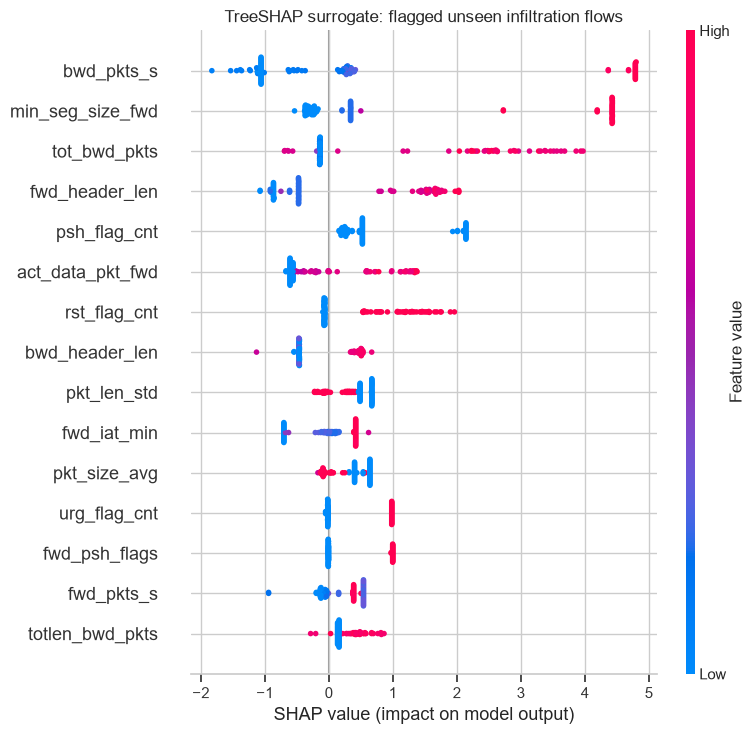

KernelSHAP on the detector: 34.8 ms per explanation; top-10 Jaccard with TreeSHAP = 0.11; Spearman = 0.18
families flagged in both sources: ['ssh']
cross-source top-10 Jaccard = 0.67, Spearman over all features = 0.91


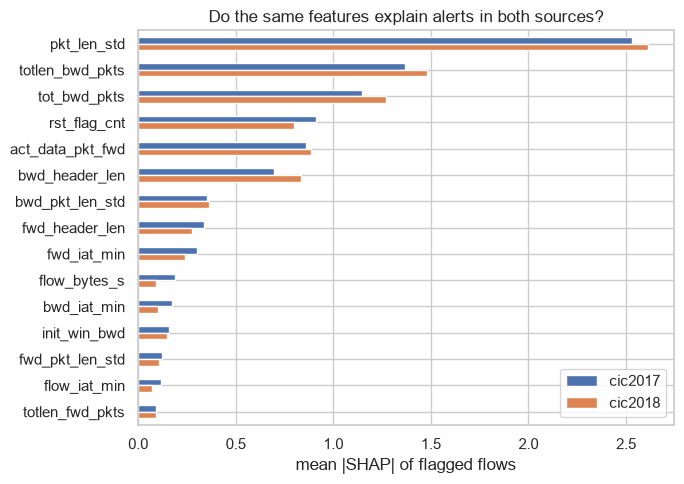

{'fidelity': 0.9982077908386484, 't_tree_ms': 0.10147572815962456, 't_kernel_ms': 34.821479999967174, 'jaccard_tree_vs_kernel': 0.1111111111111111, 'spearman_tree_vs_kernel': 0.17864655013486022, 'top10_tree': ['bwd_pkts_s', 'min_seg_size_fwd', 'tot_bwd_pkts', 'fwd_header_len', 'psh_flag_cnt', 'act_data_pkt_fwd', 'rst_flag_cnt', 'bwd_header_len', 'pkt_len_std', 'fwd_iat_min'], 'xsrc_jaccard_top10': 0.6666666666666666, 'xsrc_spearman': 0.9129884086896445, 'xsrc_families': ['ssh']}


C:\Users\DELL\AppData\Local\Temp\ipykernel_7728\1855246404.py:118: ResourceWarning: unclosed file <_io.TextIOWrapper name='D:\\Projects\\FAST-NUCES\\Cnet\\CNET-Project\\Outputs\\shap_summary.json' mode='w' encoding='cp1252'>
  json.dump(SHAPR, open(OUT / 'shap_summary.json', 'w'), indent=2, default=str)


In [21]:
import shap

# Small helpers: SHAP output shape, top-k list, Jaccard overlap
def sv_array(v):
    if isinstance(v, list):
        v = v[-1]
    v = np.asarray(v)
    return v[..., -1] if v.ndim == 3 else v

def topk(imp, names, k=10):
    return [names[i] for i in np.argsort(-imp)[:k]]
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / max(len(a | b), 1)

SHAPR = {}

# Train an XGBoost copy of the detector, then explain it with TreeSHAP
def surrogate_explain(F, pool, seed=0):
    Xs = F.pre.transform_np(pool[F.feats].to_numpy(np.float32))
    sc = F.score_scaled(Xs, only=('Proposed',))['Proposed']
    tau = float(np.quantile(F.val_b_scores, 1 - FPR_TARGET))
    dec = (sc > tau).astype(int)
    rs = np.random.RandomState(seed)
    perm = rs.permutation(len(pool))
    cut = int(0.6 * len(pool))
    a, b = perm[:cut], perm[cut:]
    if dec[a].sum() < 5 or dec[a].sum() == len(a):
        print('   too few flagged flows for a surrogate')
        return None
    sur = xgb.XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, tree_method='hist', n_jobs=THREADS, random_state=seed).fit(Xs[a], dec[a])
    fid = float((sur.predict(Xs[b]) == dec[b]).mean())
    return dict(Xs=Xs, dec=dec, sur=sur, fid=fid, holdout=b, score=sc, tau=tau)

# Explain alerts on the unseen family (infiltration held out)
F_B = KEEP.get(('B', 'infiltration', 'main'))
if F_B is not None:
    h = 'infiltration'
    trk = M[(M.split == 'train') & M.family.isin(F_B.classes)]
    vak = M[(M.split == 'val') & M.family.isin(F_B.classes)]
    Zv = F_B.score(vak)
    F_B.val_b_scores = Zv['Proposed'][(vak.family == 'benign').values]
    pool = pd.concat([trk.sample(min(30000, len(trk)), random_state=0), M[M.family == h]])
    R = surrogate_explain(F_B, pool)
    if R is not None:
        names = F_B.pre.names
        print(f'surrogate fidelity to detector decisions on held-out part of the pool: {R["fid"]:.4f}')
        flagged = [i for i in R['holdout'] if R['dec'][i] == 1 and pool.iloc[i].family == h]
        print(f'flagged held-out {h} flows available for explanation: {len(flagged)}')
        if len(flagged) >= 5:
            sel = np.array(flagged[:SHAP_N_TREE])
            tex = shap.TreeExplainer(R['sur'])
            t0 = time.perf_counter()
            sv = sv_array(tex.shap_values(R['Xs'][sel]))
            t_tree = (time.perf_counter() - t0) / len(sel) * 1e3
            imp_tree = np.abs(sv).mean(0)
            top_tree = pd.Series(imp_tree, index=names).sort_values(ascending=False).head(10)
            print(f'\nTreeSHAP top-10 features for flagged unseen {h} flows (mean |SHAP|); {t_tree:.2f} ms per explanation')
            display(top_tree.round(4).to_frame('mean_abs_shap'))
            plt.figure()
            shap.summary_plot(sv, R['Xs'][sel], feature_names=names, show=False, max_display=15)
            plt.title(f'TreeSHAP surrogate: flagged unseen {h} flows')
            plt.tight_layout()
            plt.savefig(FIG_DIR / 'shap_summary_unseen_infiltration.png', dpi=150, bbox_inches='tight')
            plt.show()
            # KernelSHAP directly on the detector
            ksel = sel[:SHAP_N_KERNEL]
            f_det = lambda X: F_B.score_scaled(np.asarray(X, dtype=np.float32), only=('Proposed',))['Proposed']
            bg = shap.kmeans(R['Xs'][R['holdout'][:2000]], 15)
            kex = shap.KernelExplainer(f_det, bg)
            t0 = time.perf_counter()
            skv = sv_array(kex.shap_values(R['Xs'][ksel], nsamples=SHAP_KERNEL_NSAMPLES, silent=True))
            t_kern = (time.perf_counter() - t0) / len(ksel) * 1e3
            imp_k = np.abs(skv).mean(0)
            SHAPR.update(dict(fidelity=R['fid'], t_tree_ms=t_tree, t_kernel_ms=t_kern,
                              jaccard_tree_vs_kernel=jaccard(topk(imp_tree, names), topk(imp_k, names)),
                              spearman_tree_vs_kernel=float(stats.spearmanr(imp_tree, imp_k)[0]), top10_tree=list(top_tree.index)))
            print(f'KernelSHAP on the detector: {t_kern:.1f} ms per explanation; top-10 Jaccard with TreeSHAP = {SHAPR["jaccard_tree_vs_kernel"]:.2f}; Spearman = {SHAPR["spearman_tree_vs_kernel"]:.2f}')
else:
    print('no Protocol B fit with infiltration held out; SHAP on unseen attack skipped')

# Compare explanations of the same family across the two datasets
F_A = KEEP[('A', 'main')]
teA = M[M.split == 'test']
Xa = F_A.pre.transform_np(teA[F_A.feats].to_numpy(np.float32))
vaA = M[M.split == 'val']
F_A.val_b_scores = F_A.score(vaA)['Proposed'][(vaA.family == 'benign').values]
RA = surrogate_explain(F_A, teA)
if RA is not None and len(SOURCES) == 2:
    names = F_A.pre.names
    tex = shap.TreeExplainer(RA['sur'])
    fam_by_src = {}
    flag = RA['dec'] == 1
    for s in SOURCES:
        fam_by_src[s] = set(teA.family[(teA.source == s).values & flag & (teA.family != 'benign').values])
    common = set.intersection(*fam_by_src.values()) - {'benign'}
    use = sorted(common) if common else None
    print('families flagged in both sources:', use if use else 'none -> comparing all flagged attacks (families differ between sources, so differences are confounded)')
    imps = {}
    for s in SOURCES:
        m_ = (teA.source == s).values & flag & ((teA.family != 'benign').values if not use else teA.family.isin(use).values)
        idx = np.where(m_)[0][:SHAP_N_TREE]
        if len(idx) >= 5:
            imps[s] = np.abs(sv_array(tex.shap_values(RA['Xs'][idx]))).mean(0)
    if len(imps) == 2:
        a, b = imps[SOURCES[0]], imps[SOURCES[1]]
        SHAPR.update(dict(xsrc_jaccard_top10=jaccard(topk(a, names), topk(b, names)), xsrc_spearman=float(stats.spearmanr(a, b)[0]),
                          xsrc_families=use if use else 'all flagged'))
        cmp_ = pd.DataFrame({SOURCES[0]: a, SOURCES[1]: b}, index=names).sort_values(SOURCES[0], ascending=False).head(15)
        print(f'cross-source top-10 Jaccard = {SHAPR["xsrc_jaccard_top10"]:.2f}, Spearman over all features = {SHAPR["xsrc_spearman"]:.2f}')
        cmp_.plot.barh(figsize=(7, 5))
        plt.gca().invert_yaxis()
        plt.xlabel('mean |SHAP| of flagged flows')
        plt.title('Do the same features explain alerts in both sources?')
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'shap_cross_source.png', dpi=150)
        plt.show()
json.dump(SHAPR, open(OUT / 'shap_summary.json', 'w'), indent=2, default=str)
print(SHAPR)

**Findings - surrogate SHAP**
* The surrogate copies the detector with **99.8% fidelity**; TreeSHAP costs 0.10 ms per alert.
* 103 unseen infiltration alerts explained. Top features: `bwd_pkts_s`, `min_seg_size_fwd`, `tot_bwd_pkts`, `fwd_header_len`, `psh_flag_cnt`.
* **But it does not explain the real detector:** top-10 overlap with KernelSHAP on the detector is only **0.11** (Jaccard). Copying decisions ≠ copying reasons.
* Cross-dataset overlap looked fine (0.67) but is not trusted. → Section 8b.

## 8b. Explain the detector itself: Integrated Gradients
**Problem:** the surrogate disagreed with KernelSHAP (Jaccard 0.11), so we were explaining a stand-in.

**Integrated Gradients (IG).** The Proposed score is differentiable, so we compute exact gradients (how the score changes when a feature changes) in numpy. IG averages them on the path from a **baseline** (mean benign flow) to the flow (32 steps).

**Checks:**
1. **Engine:** our numpy score = detector score; gradients = finite differences.
2. **Faithfulness (deletion test):** replace the top-k features by the baseline. The score should drop much faster than with k random features. *AOPC* = size of that drop.
3. **Stability:** same top-10 features across 5 retrained seeds, and across datasets (SSH).
4. **Agreement:** IG vs KernelSHAP, compared with surrogate vs KernelSHAP.
5. **Cost:** IG time per alert.

**Success criteria, fixed before running:**
* **F1:** IG AOPC ≥ 2× random, Wilcoxon p < 0.05, both cases.
* **F2:** completeness error (sum of IG vs score change) ≤ 10%.
* **S1:** seed-to-seed top-10 Jaccard ≥ 0.60.
* **S2:** cross-dataset top-10 Jaccard on SSH ≥ 0.50.
* **A1:** IG agrees with KernelSHAP better than the surrogate does.
* **C1:** IG p95 ≤ 10 ms per alert.

In [22]:
# ============ 8b. Integrated Gradients on the detector itself ============
# The proposed score is max(calibrated benign-distance, calibrated prototype-ratio) of the MLP embedding. Both parts are
# differentiable, so exact gradients are computed in numpy (manual backprop through the ReLU MLP), which also keeps the
# explanation cheap on CPU. IG baseline = the mean standardised benign training flow ("a typical benign flow").
G5_STEPS, G5_N_EVAL, G5_RANDOM_REPS = 32, 500, 10
G5_KS = [0, 1, 2, 3, 5, 8, 10, 15, 20]
G5_N_KERNEL, G5_KERNEL_NSAMPLES = SHAP_N_KERNEL, 1000

# MLP weights as numpy arrays
def mlp_layers(F):
    L = getattr(F, '_layers_np', None)
    if L is None:  # weights are read once and cached on the fitted object
        if hasattr(F.mlp, 'layers_np'):  # (used only for testing)
            L = F.mlp.layers_np
        else:
            import torch.nn as nn
            L = [(l.weight.detach().cpu().numpy().astype(np.float64), l.bias.detach().cpu().numpy().astype(np.float64))
                 for l in F.mlp.enc if isinstance(l, nn.Linear)]
        F._layers_np = L
    return L

# Proposed score in numpy
def det_scores(F, Xs):
    Z, L = F.mlp.forward_np(np.ascontiguousarray(Xs, dtype=np.float32))
    return F.os.scores(Z, L, only=('Proposed',))['Proposed']

# Proposed score and its exact gradient (manual backprop)
def det_score_grad(F, X):
    """Proposed score and its gradient w.r.t. the standardised input features (float64)."""
    layers, O = mlp_layers(F), F.os
    a, masks = np.asarray(X, dtype=np.float64), []
    for i, (W, b) in enumerate(layers):
        a = a @ W.T + b
        if i < len(layers) - 1:
            masks.append(a > 0)
            a = np.maximum(a, 0)
    z, mu = a, O.mu.astype(np.float64)
    d0 = z - mu[0]
    db = np.linalg.norm(d0, axis=1)
    da_all = np.stack([np.linalg.norm(z - mu[c], axis=1) for c in range(1, O.k)], 1)
    j = da_all.argmin(1)
    da = da_all[np.arange(len(z)), j]
    dza = z - mu[1:][j]
    eps = O.EPS
    sb = O.cal['boundary']
    sp = O.cal['proto']
    cb = (db - sb[0]) / sb[1]
    cp = ((np.log(db + eps) - np.log(da + eps)) - sp[0]) / sp[1]
    ddb = d0 / (db + 1e-12)[:, None]
    dda = dza / (da + 1e-12)[:, None]
    g = np.where((cb >= cp)[:, None], ddb / sb[1], (ddb / (db + eps)[:, None] - dda / (da + eps)[:, None]) / sp[1])
    for i in range(len(layers) - 1, -1, -1):
        g = g @ layers[i][0]
        if i > 0:
            g = g * masks[i - 1]
    return np.maximum(cb, cp), g

# IG: average gradient on the path baseline -> flow, times (flow - baseline)
def integrated_gradients(F, X, base, steps=G5_STEPS, chunk=200):
    X = np.asarray(X, dtype=np.float64)
    base = np.asarray(base, dtype=np.float64)
    out = []
    alphas = (np.arange(steps) + 0.5) / steps  # midpoint rule
    for i in range(0, len(X), chunk):
        xc = X[i:i + chunk]
        path = base[None, None, :] + alphas[None, :, None] * (xc - base)[:, None, :]
        _, g = det_score_grad(F, path.reshape(-1, X.shape[1]))
        out.append((xc - base) * g.reshape(len(xc), steps, -1).mean(1))
    return np.concatenate(out)

# Baseline = mean benign training flow (scaled)
def benign_baseline(F):
    trb = M[(M.split == 'train') & (M.family == 'benign')]
    return F.pre.transform_np(trb[F.feats].to_numpy(np.float32)).mean(0).astype(np.float64)

# Replace the top-k features of each flow by the baseline
def delete_topk(X, base, order, k):
    if k == 0:
        return X
    Xm = X.copy()
    idx = order[:, :k]
    Xm[np.arange(len(X))[:, None], idx] = base[idx].astype(X.dtype)
    return Xm

# Score drop when deleting top-k features (explainer vs random)
def deletion_curves(F, X, rankers, base, ks=G5_KS, reps=G5_RANDOM_REPS, seed=0):
    """Replace the k top-ranked features of each flow by the benign baseline and re-score with the real detector."""
    curves = {}
    for name, A in rankers.items():
        order = np.argsort(-np.abs(A), axis=1)
        curves[name] = np.stack([det_scores(F, delete_topk(X, base, order, k)) for k in ks])  # (len(ks), n)
    rs = np.random.RandomState(seed)
    rnd = np.zeros((len(ks), len(X)))
    for _ in range(reps):
        order = np.argsort(rs.rand(*X.shape), axis=1)
        for i, k in enumerate(ks):
            rnd[i] += det_scores(F, delete_topk(X, base, order, k)) / reps
    curves['Random'] = rnd
    return curves

# Benign validation scores and threshold of a fitted model
def prep_val(F, classes):
    va = M[(M.split == 'val') & M.family.isin(classes)]
    F.val_b_scores = F.score(va)['Proposed'][(va.family == 'benign').values]
    F.tau = float(np.quantile(F.val_b_scores, 1 - FPR_TARGET))
    return F

# Full G5 test on one case: explain alerts, faithfulness, completeness
def g5_case(name, F, classes, pool, fam_filter, seed=0):
    prep_val(F, classes)
    R = surrogate_explain(F, pool, seed)  # surrogate of the detector's DECISIONS (for the TreeSHAP comparison)
    if R is None:
        return None
    fams = pool.family.to_numpy()
    hold = np.asarray(R['holdout'])
    idx = hold[(R['dec'][hold] == 1) & np.isin(fams[hold], fam_filter)]
    if len(idx) < 10:
        print(f'{name}: only {len(idx)} flagged flows, skipped')
        return None
    idx = np.random.RandomState(seed).permutation(idx)[:G5_N_EVAL]
    X = R['Xs'][idx]
    base = benign_baseline(F)
    ig = integrated_gradients(F, X, base)
    rankers = {'IntegratedGradients': ig}
    try:
        tex = shap.TreeExplainer(R['sur'])
        rankers['TreeSHAP-surrogate'] = np.abs(sv_array(tex.shap_values(X)))
    except Exception as e:
        print('   TreeSHAP unavailable:', str(e)[:80])
    curves = deletion_curves(F, X, rankers, base, seed=seed)
    s0 = det_scores(F, X)
    tau = R['tau']
    # completeness check: sum(IG) should equal score(x) - score(baseline)
    sb_ = det_score_grad(F, base[None, :])[0][0]
    gap = s0 - sb_
    comp = np.abs(ig.sum(1) - gap) / np.maximum(np.abs(gap), 1e-6)
    kk = [i for i, k in enumerate(G5_KS) if k > 0]
    aopc = {n: (s0[None, :] - c[kk]).mean(0) for n, c in curves.items()}  # per-flow area over the deletion curve
    rows = []
    for n_, c in curves.items():
        rows.append(dict(case=name, ranker=n_, n_flows=len(X), AOPC=float(aopc[n_].mean()),
                         **{f'flag_left@{k}': float((c[G5_KS.index(k)] > tau).mean()) for k in (1, 3, 5, 10)}))
    tab = pd.DataFrame(rows).set_index(['case', 'ranker'])
    res = dict(name=name, F=F, R=R, idx=idx, X=X, base=base, ig=ig, rankers=rankers, curves=curves, s0=s0, tau=tau,
               aopc=aopc, table=tab, completeness_median=float(np.median(comp)), n=len(X))
    for other in rankers:
        try:
            res[f'p_{other}_vs_random'] = float(stats.wilcoxon(aopc[other], aopc['Random'], alternative='greater')[1])
        except Exception:
            res[f'p_{other}_vs_random'] = np.nan
    try:
        res['p_ig_vs_tree'] = float(stats.wilcoxon(aopc['IntegratedGradients'], aopc['TreeSHAP-surrogate'], alternative='greater')[1])
    except Exception:
        res['p_ig_vs_tree'] = np.nan
    return res

In [23]:
# ---- sanity checks: our score and gradients match the real detector ----
F_A = KEEP[('A', 'main')]
rs_ = np.random.RandomState(0)
te_ = M[M.split == 'test']
sm_ = te_.iloc[rs_.choice(len(te_), min(500, len(te_)), replace=False)]
Xchk = F_A.pre.transform_np(sm_[F_A.feats].to_numpy(np.float32))
s_ref = det_scores(F_A, Xchk)
s_mine, g_mine = det_score_grad(F_A, Xchk)
print(f'1) my numpy score vs the detector score: max abs difference = {np.abs(s_ref - s_mine).max():.2e}')
# Gradient check against finite differences
errs = []
for i in range(5):
    for f in rs_.choice(Xchk.shape[1], 5, replace=False):
        e = np.zeros(Xchk.shape[1])
        e[f] = 1e-5
        fd = (det_score_grad(F_A, (Xchk[i] + e)[None])[0][0] - det_score_grad(F_A, (Xchk[i] - e)[None])[0][0]) / 2e-5
        errs.append(abs(fd - g_mine[i, f]) / (abs(fd) + 1e-6))
print(f'2) gradient vs finite differences: median relative error = {np.median(errs):.2e}')

1) my numpy score vs the detector score: max abs difference = 1.10e-05
2) gradient vs finite differences: median relative error = 2.53e-10



=== unseen_infiltration: 103 flagged flows | IG completeness (median relative error) = 0.023


n_flows    AOPC  flag_left@1  \
case                ranker                                              
unseen_infiltration IntegratedGradients      103  1.6354       0.4757   
                    TreeSHAP-surrogate       103  0.9448       0.4078   
                    Random                   103  0.6486       0.8932   

                                         flag_left@3  flag_left@5  \
case                ranker                                          
unseen_infiltration IntegratedGradients       0.2233       0.2233   
                    TreeSHAP-surrogate        0.2621       0.4466   
                    Random                    0.7282       0.6699   

                                         flag_left@10  
case                ranker                             
unseen_infiltration IntegratedGradients        0.0000  
                    TreeSHAP-surrogate         0.2524  
                    Random                     0.3495

{'p_IntegratedGradients_vs_random': 0.0, 'p_TreeSHAP-surrogate_vs_random': 0.0, 'p_ig_vs_tree': 0.0}

=== closed_set: 500 flagged flows | IG completeness (median relative error) = 0.018


n_flows    AOPC  flag_left@1  flag_left@3  \
case       ranker                                                           
closed_set IntegratedGradients      500  8.3575        0.036        0.004   
           TreeSHAP-surrogate       500  4.0896        0.862        0.852   
           Random                   500  2.8844        0.984        0.952   

                                flag_left@5  flag_left@10  
case       ranker                                          
closed_set IntegratedGradients        0.000         0.000  
           TreeSHAP-surrogate         0.786         0.016  
           Random                     0.916         0.808

{'p_IntegratedGradients_vs_random': 0.0, 'p_TreeSHAP-surrogate_vs_random': 0.0, 'p_ig_vs_tree': 0.0}


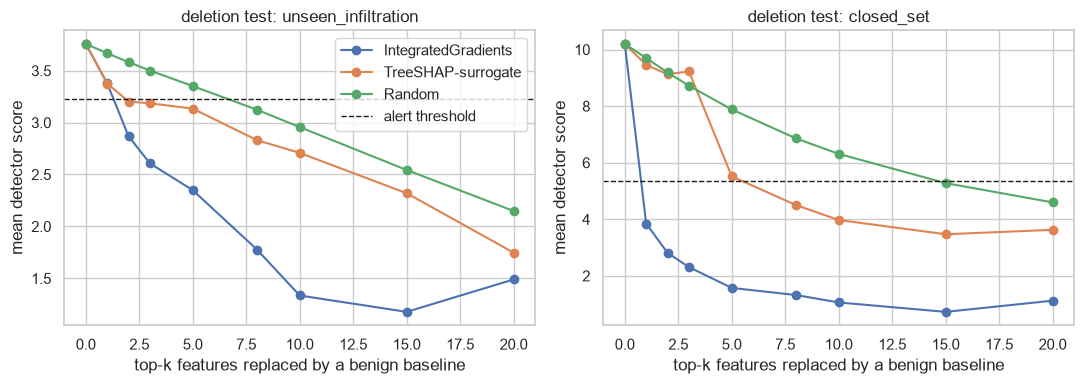


Integrated Gradients, top-15 features for flagged UNSEEN infiltration flows (mean |attribution|)


,mean_abs_IG
fwd_header_len,0.2495
min_seg_size_fwd,0.2065
init_win_fwd,0.1874
act_data_pkt_fwd,0.1848
urg_flag_cnt,0.1762
fwd_iat_min,0.1740
bwd_pkts_s,0.1690
pkt_size_avg,0.1580
bwd_iat_std,0.1552
bwd_header_len,0.1485


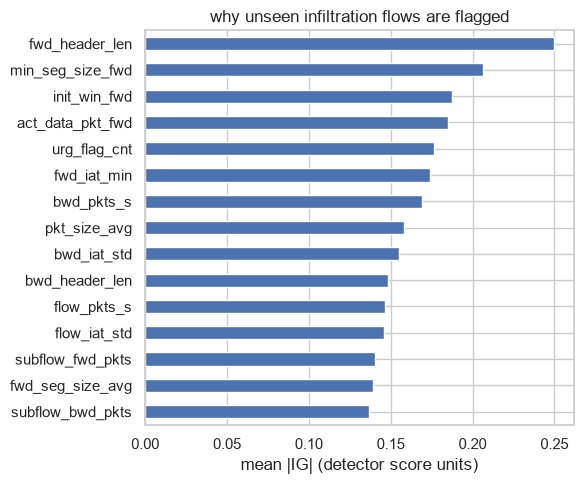

In [24]:
# ---- faithfulness: unseen-family alerts (Protocol B) and closed-set alerts (Protocol A) ----
G5 = {}
F_B = KEEP.get(('B', 'infiltration', 'main'))
if F_B is not None:
    clsB = list(F_B.classes)
    trk = M[(M.split == 'train') & M.family.isin(clsB)]
    poolB = pd.concat([trk.sample(min(30000, len(trk)), random_state=0), M[M.family == 'infiltration']])
    G5['unseen_infiltration'] = g5_case('unseen_infiltration', F_B, clsB, poolB, ['infiltration'])
F_A = KEEP[('A', 'main')]
G5['closed_set'] = g5_case('closed_set', F_A, ['benign'] + ATTACKS, M[M.split == 'test'], ATTACKS)
G5 = {k: v for k, v in G5.items() if v is not None}

for k, v in G5.items():
    print(f'\n=== {k}: {v["n"]} flagged flows | IG completeness (median relative error) = {v["completeness_median"]:.3f}')
    display(v['table'].round(4))
    print({kk: round(vv, 5) for kk, vv in v.items() if kk.startswith('p_')})

fig, axs = plt.subplots(1, max(len(G5), 1), figsize=(5.5 * max(len(G5), 1), 4))
axs = np.atleast_1d(axs)
for ax, (k, v) in zip(axs, G5.items()):
    for n_, c in v['curves'].items():
        ax.plot(G5_KS, c.mean(1), marker='o', label=n_)
    ax.axhline(v['tau'], color='k', ls='--', lw=1, label='alert threshold')
    ax.set_xlabel('top-k features replaced by a benign baseline')
    ax.set_ylabel('mean detector score')
    ax.set_title(f'deletion test: {k}')
axs[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'g5_deletion_curves.png', dpi=150, bbox_inches='tight')
plt.show()

if 'unseen_infiltration' in G5:
    v = G5['unseen_infiltration']
    names = v['F'].pre.names
    top = pd.Series(np.abs(v['ig']).mean(0), index=names).sort_values(ascending=False).head(15)
    print('\nIntegrated Gradients, top-15 features for flagged UNSEEN infiltration flows (mean |attribution|)')
    display(top.round(4).to_frame('mean_abs_IG'))
    top[::-1].plot.barh(figsize=(6, 5))
    plt.xlabel('mean |IG| (detector score units)')
    plt.title('why unseen infiltration flows are flagged')
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'g5_ig_top_features.png', dpi=150, bbox_inches='tight')
    plt.show()

In [25]:
# Fit only the MLP for a seed
def fit_mlp_only(seed, classes, tr, va):
    F = fit_detectors(tr, va, FEATS, classes, seed, ('MLP',), HIDDEN)
    return prep_val(F, classes)

# Mean |IG| per feature over flagged flows
def mean_abs_ig(F, flows, cap=G5_N_EVAL, seed=0):
    X = F.pre.transform_np(flows[F.feats].to_numpy(np.float32))
    fl = np.where(det_scores(F, X) > F.tau)[0]
    if len(fl) < 5:
        return None, len(fl)
    fl = np.random.RandomState(seed).permutation(fl)[:cap]
    return np.abs(integrated_gradients(F, X[fl], benign_baseline(F))).mean(0), len(fl)

# Top-10 Jaccard and Spearman for every pair of seeds
def pairwise(vecs, names, k=10):
    J, S = [], []
    for a, b in itertools.combinations(vecs, 2):
        J.append(jaccard(topk(a, names, k), topk(b, names, k)))
        S.append(float(stats.spearmanr(a, b)[0]))
    return J, S

# Retrain per seed and collect attributions
STAB, XSRC = {'closed_set': {}, 'unseen_infiltration': {}}, []
clsA = ['benign'] + ATTACKS
for sd_ in SEEDS:
    set_seed(sd_)
    FA = fit_mlp_only(sd_, clsA, M[M.split == 'train'], M[M.split == 'val'])
    STAB['closed_set'][sd_] = mean_abs_ig(FA, M[(M.split == 'test') & (M.family != 'benign')])[0]
    names_ = FA.pre.names
    if len(SOURCES) == 2 and SHARED_FAMILY in ATTACKS:
        vs = [mean_abs_ig(FA, M[(M.split == 'test') & (M.family == SHARED_FAMILY) & (M.source == s)])[0] for s in SOURCES]
        if all(v_ is not None for v_ in vs):
            XSRC.append(dict(seed=sd_, jaccard_top10=jaccard(topk(vs[0], names_), topk(vs[1], names_)), spearman=float(stats.spearmanr(*vs)[0])))
    if 'infiltration' in ATTACKS:
        clsB_ = ['benign'] + [a for a in ATTACKS if a != 'infiltration']
        FBs = fit_mlp_only(sd_, clsB_, M[(M.split == 'train') & M.family.isin(clsB_)], M[(M.split == 'val') & M.family.isin(clsB_)])
        STAB['unseen_infiltration'][sd_] = mean_abs_ig(FBs, M[M.family == 'infiltration'])[0]
    del FA
    gc.collect()
    print(f'seed {sd_} done')

# Stability tables
STAB_ROWS = []
for case, d_ in STAB.items():
    vecs = [v for v in d_.values() if v is not None]
    if len(vecs) >= 2:
        J, S = pairwise(vecs, names_)
        STAB_ROWS.append(dict(case=case, n_models=len(vecs), top10_jaccard_mean=np.mean(J), top10_jaccard_min=np.min(J), spearman_mean=np.mean(S)))
STAB_DF = pd.DataFrame(STAB_ROWS, columns=['case', 'n_models', 'top10_jaccard_mean', 'top10_jaccard_min', 'spearman_mean']).set_index('case')
print('\nSEED-TO-SEED STABILITY of IG attributions (same flows, models retrained with different seeds)')
save_table(STAB_DF.round(3), 'g5_seed_stability')
XSRC_DF = pd.DataFrame(XSRC)
if len(XSRC_DF):
    print(f'\nCROSS-SOURCE STABILITY on {SHARED_FAMILY.upper()} alerts (2017 vs 2018), per seed')
    save_table(XSRC_DF.round(3), 'g5_cross_source', index=False)

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done

SEED-TO-SEED STABILITY of IG attributions (same flows, models retrained with different seeds)


,n_models,top10_jaccard_mean,top10_jaccard_min,spearman_mean
case,,,,
closed_set,5,0.542,0.333,0.771
unseen_infiltration,5,0.204,0.053,0.444



CROSS-SOURCE STABILITY on SSH alerts (2017 vs 2018), per seed


,seed,jaccard_top10,spearman
0,0,0.667,0.710
1,1,0.667,0.698
2,2,0.667,0.701
3,3,0.667,0.681
4,4,0.538,0.647


In [26]:
# ---- agreement with KernelSHAP, and explanation cost ----
G5R = {}

# KernelSHAP on the real detector vs IG and surrogate TreeSHAP
if 'unseen_infiltration' in G5:
    v = G5['unseen_infiltration']
    Fb = v['F']
    R_ = v['R']
    nK = min(G5_N_KERNEL, len(v['X']))
    Xk = v['X'][:nK]
    agree = {}
    try:
        bg = shap.kmeans(R_['Xs'][np.asarray(R_['holdout'])[:2000]], 15)
        kex = shap.KernelExplainer(lambda Z: det_scores(Fb, np.asarray(Z, dtype=np.float32)), bg)
        A_k = np.abs(sv_array(kex.shap_values(Xk, nsamples=G5_KERNEL_NSAMPLES, silent=True)))
        A_ig = np.abs(v['ig'][:nK])
        A_tr = np.abs(v['rankers']['TreeSHAP-surrogate'][:nK]) if 'TreeSHAP-surrogate' in v['rankers'] else None
        nm = Fb.pre.names
        def cmp_(A, B):
            sp = [stats.spearmanr(a, b)[0] for a, b in zip(A, B)]
            return dict(per_flow_spearman=float(np.nanmean(sp)), top10_jaccard=jaccard(topk(A.mean(0), nm), topk(B.mean(0), nm)))
        agree['IG vs KernelSHAP'] = cmp_(A_ig, A_k)
        if A_tr is not None:
            agree['TreeSHAP-surrogate vs KernelSHAP'] = cmp_(A_tr, A_k)
            agree['IG vs TreeSHAP-surrogate'] = cmp_(A_ig, A_tr)
        AG = pd.DataFrame(agree).T
        print(f'\nAGREEMENT between explainers on {nK} flagged unseen-infiltration flows (KernelSHAP: {G5_KERNEL_NSAMPLES} samples)')
        save_table(AG.round(3), 'g5_explainer_agreement')
        G5R['agreement'] = AG.to_dict('index')
    except Exception as e:
        print('KernelSHAP comparison skipped:', str(e)[:120])

# Latency: detector score vs one IG explanation
F_c = KEEP[('A', 'main')]
base_c = benign_baseline(F_c)
te_c = M[M.split == 'test'].sample(600, random_state=0)
Xc = F_c.pre.transform_np(te_c[F_c.feats].to_numpy(np.float32))
rows_c = [Xc[i:i + 1] for i in range(len(Xc))]
with threadpool_limits(limits=1):
    lat_det = measure_latency(lambda x: det_scores(F_c, x), rows_c, n=500, warm=30)
    lat_ig = measure_latency(lambda x: integrated_gradients(F_c, x, base_c), rows_c, n=500, warm=30)
cost5 = pd.DataFrame({'detector score': [np.percentile(lat_det, q) for q in (50, 95, 99)],
                      f'Integrated Gradients ({G5_STEPS} steps)': [np.percentile(lat_ig, q) for q in (50, 95, 99)]}, index=['p50 ms', 'p95 ms', 'p99 ms']).T
if SHAPR.get('t_tree_ms') is not None:
    cost5.loc['TreeSHAP on surrogate (batch average)', 'p50 ms'] = SHAPR['t_tree_ms']
if SHAPR.get('t_kernel_ms') is not None:
    cost5.loc['KernelSHAP (batch average)', 'p50 ms'] = SHAPR['t_kernel_ms']
print('\nEXPLANATION COST, one CPU thread')
save_table(cost5.round(3), 'g5_explanation_cost')
G5R['ig_p50_ms'], G5R['ig_p95_ms'] = float(np.percentile(lat_ig, 50)), float(np.percentile(lat_ig, 95))


AGREEMENT between explainers on 30 flagged unseen-infiltration flows (KernelSHAP: 1000 samples)


,per_flow_spearman,top10_jaccard
IG vs KernelSHAP,0.451,0.250
TreeSHAP-surrogate vs KernelSHAP,0.155,0.176
IG vs TreeSHAP-surrogate,0.211,0.333



EXPLANATION COST, one CPU thread


,p50 ms,p95 ms,p99 ms
detector score,0.533,1.579,2.307
Integrated Gradients (32 steps),0.598,1.468,2.138
TreeSHAP on surrogate (batch average),0.101,NaN,NaN
KernelSHAP (batch average),34.821,NaN,NaN


In [27]:
# ---- G5 pre-registered criteria (thresholds fixed in the markdown above) ----
THR5 = dict(aopc_ratio=2.0, p=0.05, completeness=0.10, seed_jaccard=0.60, xsrc_jaccard=0.50, ig_p95_ms=10.0)

# Check every criterion
crit5 = []
for k, v in G5.items():
    a_ig, a_rn = float(v['aopc']['IntegratedGradients'].mean()), float(v['aopc']['Random'].mean())
    p = v.get('p_IntegratedGradients_vs_random', np.nan)
    crit5.append((f'F1 faithfulness ({k}): AOPC(IG) >= 2x random and Wilcoxon p < 0.05', bool(a_ig >= THR5['aopc_ratio'] * a_rn and p < THR5['p']), dict(AOPC_IG=round(a_ig, 3), AOPC_random=round(a_rn, 3), p=round(p, 5))))
    crit5.append((f'F2 completeness ({k}): median relative error of sum(IG) <= 0.10', bool(v['completeness_median'] <= THR5['completeness']), dict(median_rel_err=round(v['completeness_median'], 3))))
for case, r in STAB_DF.iterrows():
    crit5.append((f'S1 seed stability ({case}): mean top-10 Jaccard >= 0.60', bool(r.top10_jaccard_mean >= THR5['seed_jaccard']), dict(mean=round(float(r.top10_jaccard_mean), 3), min=round(float(r.top10_jaccard_min), 3))))
if len(XSRC_DF):
    crit5.append((f'S2 cross-source ({SHARED_FAMILY.upper()}): mean top-10 Jaccard >= 0.50', bool(XSRC_DF.jaccard_top10.mean() >= THR5['xsrc_jaccard']), dict(mean=round(float(XSRC_DF.jaccard_top10.mean()), 3), n_seeds=len(XSRC_DF))))
ag = G5R.get('agreement', {})
if 'IG vs KernelSHAP' in ag and 'TreeSHAP-surrogate vs KernelSHAP' in ag:
    a, b = ag['IG vs KernelSHAP']['per_flow_spearman'], ag['TreeSHAP-surrogate vs KernelSHAP']['per_flow_spearman']
    crit5.append(('A1 IG agrees with KernelSHAP on the detector better than the surrogate TreeSHAP does (per-flow Spearman)', bool(a > b), dict(IG=round(a, 3), TreeSHAP_surrogate=round(b, 3))))
crit5.append(('C1 IG cost: p95 <= 10 ms per alert on one CPU thread', bool(G5R['ig_p95_ms'] <= THR5['ig_p95_ms']), dict(p50=round(G5R['ig_p50_ms'], 3), p95=round(G5R['ig_p95_ms'], 3))))
CRIT5 = pd.DataFrame([dict(criterion=a, passed=b, values=str(c)) for a, b, c in crit5])
print('G5 PRE-REGISTERED CRITERIA')
display(CRIT5)
G5R.update(passed=int(CRIT5.passed.sum()), total=len(CRIT5), verdict=('Achieved' if CRIT5.passed.all() else 'Partly achieved' if CRIT5.passed.any() else 'Not achieved'))
print('G5 verdict:', G5R['verdict'])
json.dump(G5R, open(OUT / 'g5_summary.json', 'w'), indent=2, default=str)

# Combined G3 / G5 verdict table
VERD = pd.DataFrame([
    dict(gap='G3 cross-dataset transfer', verdict=G3R['verdict'], criteria_passed=f"{G3R['passed']}/{G3R['total']}"),
    dict(gap='G5 explanations tied to detection', verdict=G5R['verdict'], criteria_passed=f"{G5R['passed']}/{G5R['total']}")])
save_table(VERD, 'g3_g5_verdicts', index=False)
CRIT3.assign(gap='G3').pipe(lambda d: pd.concat([d, CRIT5.assign(gap='G5')])).to_csv(TAB_DIR / 'g3_g5_criteria.csv', index=False)

G5 PRE-REGISTERED CRITERIA


,criterion,passed,values
0,F1 faithfulness (unseen_infiltration): AOPC(IG...,True,"{'AOPC_IG': 1.635, 'AOPC_random': 0.649, 'p': ..."
1,F2 completeness (unseen_infiltration): median ...,True,{'median_rel_err': 0.023}
2,F1 faithfulness (closed_set): AOPC(IG) >= 2x r...,True,"{'AOPC_IG': 8.357, 'AOPC_random': 2.884, 'p': ..."
3,F2 completeness (closed_set): median relative ...,True,{'median_rel_err': 0.018}
4,S1 seed stability (closed_set): mean top-10 Ja...,False,"{'mean': 0.542, 'min': 0.333}"
5,S1 seed stability (unseen_infiltration): mean ...,False,"{'mean': 0.204, 'min': 0.053}"
6,S2 cross-source (SSH): mean top-10 Jaccard >= ...,True,"{'mean': 0.641, 'n_seeds': 5}"
7,A1 IG agrees with KernelSHAP on the detector b...,True,"{'IG': 0.451, 'TreeSHAP_surrogate': 0.155}"
8,C1 IG cost: p95 <= 10 ms per alert on one CPU ...,True,"{'p50': 0.598, 'p95': 1.468}"


G5 verdict: Partly achieved


C:\Users\DELL\AppData\Local\Temp\ipykernel_7728\4252685589.py:25: ResourceWarning: unclosed file <_io.TextIOWrapper name='D:\\Projects\\FAST-NUCES\\Cnet\\CNET-Project\\Outputs\\g5_summary.json' mode='w' encoding='cp1252'>
  json.dump(G5R, open(OUT / 'g5_summary.json', 'w'), indent=2, default=str)


,gap,verdict,criteria_passed
0,G3 cross-dataset transfer,Not achieved,0/3
1,G5 explanations tied to detection,Partly achieved,7/9


**Findings - Integrated Gradients**
* **Engine checks pass:** score difference 1.1e-5, gradient error 2.5e-10.
* **Faithful:** deleting top IG features drops the score 2.5× more than random (unseen) and 2.9× (closed-set), p < 0.001. After deleting the top-10, **no** unseen alert is still flagged (35% with random features).
* **Complete:** error 2.3% / 1.8%.
* **Agrees with KernelSHAP** better than the surrogate (0.45 vs 0.16).
* **Cheap:** IG p95 = 1.47 ms per alert, about the cost of scoring the flow in the same test (1.58 ms), vs 34.8 ms for KernelSHAP.
* **Not stable across seeds:** Jaccard 0.54 / 0.20 (fails S1). Cross-dataset 0.64 passes.
* Top unseen-infiltration features: `fwd_header_len`, `min_seg_size_fwd`, `init_win_fwd`, `act_data_pkt_fwd`, `urg_flag_cnt` (TCP header / window features).
* **Verdict: Partly achieved (7/9).**

## 8c. Extended G5 tests (written before running)
**Problems(Measurement bugs) found in 8b:**
1. Seed stability compared *different* flows per seed.
2. Many features are copies (e.g. `tot_fwd_pkts` = `subflow_fwd_pkts`), so credit jumps between copies.
3. KernelSHAP and IG used different baselines.
4. The deletion test used IG's own baseline, which favours IG.

**New criteria:**
* **S1b:** on the **same** 500 flows, seed-to-seed top-10 Jaccard ≥ 0.60 at the level of **correlation clusters** (groups of features with |Spearman| ≥ 0.95).
* **F3:** IG deletion ≥ 2× random (p < 0.05) under **other** baselines (benign median, random benign flows), **and** IG insertion beats random (p < 0.05).
* **A2:** IG agrees with KernelSHAP (same baseline) better than the surrogate does.
* **T1:** explanations of SSH alerts transfer across datasets: cluster top-10 Jaccard ≥ 0.50, both directions.
* Reported only: attribution vs feature shift (explains G3), and number of unseen alerts available (coverage).

In [28]:
# ============ 8c. Seed stability on fixed flows, at cluster level (S1b) ============

# Group near-copy features into correlation clusters
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

def feature_clusters(F, df, thr=0.95, n=20000, seed=0):
    d = df.sample(min(n, len(df)), random_state=seed)
    X = F.pre.transform_np(d[F.feats].to_numpy(np.float32))
    rho = np.nan_to_num(stats.spearmanr(X).correlation, nan=0.0)
    D = np.clip(1 - np.abs(rho), 0, None)
    np.fill_diagonal(D, 0)
    D = (D + D.T) / 2
    lab = fcluster(linkage(squareform(D, checks=False), method='complete'), t=1 - thr, criterion='distance')
    return pd.Series(lab, index=F.pre.names)

# Sum attribution per cluster
def cluster_mass(imp, names, clusters):
    return pd.Series(imp, index=names).groupby(clusters.reindex(names).values).sum()

# Same 500 flows for every seed; compare top-10 features and clusters
def stability_fixed(case, classes, tr, va, flows, n_flows=500, seeds=SEEDS, k=10):
    fixed = flows.sample(min(n_flows, len(flows)), random_state=0)
    IG, FLAG, names, CL, MODELS = {}, {}, None, None, {}
    for sd_ in seeds:
        set_seed(sd_)
        F = prep_val(fit_detectors(tr, va, FEATS, classes, sd_, ('MLP',), HIDDEN), classes)
        if names is None:
            names = F.pre.names
            CL = feature_clusters(F, tr)
        assert F.pre.names == names, 'feature list changed between seeds'
        X = F.pre.transform_np(fixed[F.feats].to_numpy(np.float32))
        IG[sd_] = np.abs(integrated_gradients(F, X, benign_baseline(F)))
        FLAG[sd_] = det_scores(F, X) > F.tau
        MODELS[sd_] = F
    out = {}
    for sub, mask in (('all_fixed_flows', np.ones(len(fixed), bool)), ('flagged_by_all_seeds', np.logical_and.reduce(list(FLAG.values())))):
        if mask.sum() < 5 or len(seeds) < 2:  # needs >= 2 seeds
            out[sub] = dict(n_flows=int(mask.sum()))
            continue
        feat = [IG[s][mask].mean(0) for s in seeds]
        clus = [cluster_mass(v, names, CL) for v in feat]
        Jf = [jaccard(topk(a, names, k), topk(b, names, k)) for a, b in itertools.combinations(feat, 2)]
        Jc = [jaccard(list(a.nlargest(k).index), list(b.nlargest(k).index)) for a, b in itertools.combinations(clus, 2)]
        Sp = [np.nanmean([stats.spearmanr(x, y)[0] for x, y in zip(IG[a][mask], IG[b][mask])]) for a, b in itertools.combinations(seeds, 2)]
        out[sub] = dict(n_flows=int(mask.sum()), feat_top10_jaccard=np.mean(Jf), cluster_top10_jaccard=np.mean(Jc),
                        cluster_top10_jaccard_min=np.min(Jc), per_flow_spearman=np.mean(Sp))
    print(f'{case}: {CL.nunique()} clusters from {len(names)} features')
    return pd.DataFrame(out).T.assign(case=case), CL, MODELS

# Run for closed-set and unseen-infiltration cases
clsA = ['benign'] + ATTACKS
STAB_A, CL_A, MODELS_A = stability_fixed('closed_set', clsA, M[M.split == 'train'], M[M.split == 'val'],
                                         M[(M.split == 'test') & (M.family != 'benign')])
STAB_ROWS2 = [STAB_A]
if 'infiltration' in ATTACKS:
    clsB_ = ['benign'] + [a for a in ATTACKS if a != 'infiltration']
    STAB_B, CL_B, MODELS_B = stability_fixed('unseen_infiltration', clsB_, M[(M.split == 'train') & M.family.isin(clsB_)],
                                             M[(M.split == 'val') & M.family.isin(clsB_)], M[M.family == 'infiltration'])
    STAB_ROWS2.append(STAB_B)
STAB2 = pd.concat(STAB_ROWS2).round(3)
print('SEED STABILITY ON FIXED FLOWS (feature level and correlation-cluster level)')
save_table(STAB2, 'g5v2_stability_fixed')

closed_set: 42 clusters from 68 features
unseen_infiltration: 40 clusters from 66 features
SEED STABILITY ON FIXED FLOWS (feature level and correlation-cluster level)


,n_flows,feat_top10_jaccard,cluster_top10_jaccard,cluster_top10_jaccard_min,per_flow_spearman,case
all_fixed_flows,500.0,0.520,0.791,0.667,0.599,closed_set
flagged_by_all_seeds,295.0,0.534,0.646,0.538,0.646,closed_set
all_fixed_flows,500.0,0.295,0.730,0.538,0.624,unseen_infiltration
flagged_by_all_seeds,2.0,NaN,NaN,NaN,NaN,unseen_infiltration


,n_flows,feat_top10_jaccard,cluster_top10_jaccard,cluster_top10_jaccard_min,per_flow_spearman,case
all_fixed_flows,500.0,0.520,0.791,0.667,0.599,closed_set
flagged_by_all_seeds,295.0,0.534,0.646,0.538,0.646,closed_set
all_fixed_flows,500.0,0.295,0.730,0.538,0.624,unseen_infiltration
flagged_by_all_seeds,2.0,NaN,NaN,NaN,NaN,unseen_infiltration


In [29]:
# ============ 8c. Faithfulness under other baselines (F3) and KernelSHAP agreement (A2) ============

# Deletion / insertion curves for one ranking
def perturb_curves(F, X, A, base, ks=G5_KS, mode='delete'):
    order = np.argsort(-np.abs(A), axis=1)
    r = np.arange(len(X))[:, None]
    out = []
    for k in ks:
        if mode == 'delete':
            Xm = delete_topk(X, base, order, k)
        else:
            Xm = np.broadcast_to(base.astype(X.dtype), X.shape).copy()
            if k:
                Xm[r, order[:, :k]] = X[r, order[:, :k]]
        out.append(det_scores(F, Xm))
    return np.stack(out)

# One-sided Wilcoxon p-value
def _wx(a, b):
    try:
        return float(stats.wilcoxon(a, b, alternative='greater')[1])
    except ValueError:
        return np.nan

# Faithfulness under several baselines
def faithfulness_multi(v, n_rand=10, n_bench=10, seed=0):
    F, X = v['F'], v['X']
    rs = np.random.RandomState(seed)
    trb_df = M[(M.split == 'train') & (M.family == 'benign')]
    trb = F.pre.transform_np(trb_df.sample(min(5000, len(trb_df)), random_state=seed)[F.feats].to_numpy(np.float32))
    baselines = {'benign_mean (IG baseline)': [v['base']], 'benign_median': [np.median(trb, 0)],
                 'random_benign_flows': [trb[i] for i in rs.choice(len(trb), n_bench, replace=False)]}
    rankers = dict(v['rankers'])
    rankers.update({f'Random{i}': rs.rand(*X.shape) for i in range(n_rand)})
    s0 = det_scores(F, X)
    kk = [i for i, k in enumerate(G5_KS) if k > 0]
    rows = []
    for bname, blist in baselines.items():
        per = {}
        for rn, A in rankers.items():
            dl = np.mean([perturb_curves(F, X, A, b.astype(np.float64), mode='delete') for b in blist], 0)
            ins = np.mean([perturb_curves(F, X, A, b.astype(np.float64), mode='insert') for b in blist], 0)
            per[rn] = ((s0[None] - dl[kk]).mean(0), (ins[kk] - ins[0][None]).mean(0))
        rnd_del = np.mean([per[f'Random{i}'][0] for i in range(n_rand)], 0)
        rnd_ins = np.mean([per[f'Random{i}'][1] for i in range(n_rand)], 0)
        for rn in v['rankers']:
            d_, i_ = per[rn]
            rows.append(dict(baseline=bname, ranker=rn, AOPC_del=d_.mean(), AOPC_del_random=rnd_del.mean(),
                             ratio_del=(d_.mean() / rnd_del.mean()) if rnd_del.mean() > 1e-6 else np.nan,
                             p_del=_wx(d_, rnd_del),
                             AUC_ins=i_.mean(), AUC_ins_random=rnd_ins.mean(),
                             p_ins=_wx(i_, rnd_ins)))
    return pd.DataFrame(rows).set_index(['baseline', 'ranker'])

# Run for every case
FAITH2 = {k: faithfulness_multi(v) for k, v in G5.items()}
for k, t in FAITH2.items():
    print(f'\nFAITHFULNESS UNDER SEVERAL BASELINES: {k}')
    save_table(t.round(4), f'g5v2_faithfulness_{k}')

# Agreement with KernelSHAP using the same benign baseline
A2 = {}
if 'unseen_infiltration' in G5:
    v = G5['unseen_infiltration']
    nK = min(100, len(v['X']))
    Xk = v['X'][:nK]
    kex = shap.KernelExplainer(lambda Z: det_scores(v['F'], np.asarray(Z, dtype=np.float32)), v['base'][None, :].astype(np.float32))
    A_k = np.abs(sv_array(kex.shap_values(Xk, nsamples=G5_KERNEL_NSAMPLES, silent=True)))
    sp = lambda A, B: float(np.nanmean([stats.spearmanr(a, b)[0] for a, b in zip(A, B)]))
    A2 = {'IG vs KernelSHAP(same baseline)': sp(np.abs(v['ig'][:nK]), A_k)}
    if 'TreeSHAP-surrogate' in v['rankers']:
        A2['TreeSHAP-surrogate vs KernelSHAP(same baseline)'] = sp(v['rankers']['TreeSHAP-surrogate'][:nK], A_k)
    print('\nA2 agreement (per-flow Spearman, n =', nK, '):', {k: round(x, 3) for k, x in A2.items()})


FAITHFULNESS UNDER SEVERAL BASELINES: unseen_infiltration


AOPC_del  AOPC_del_random  \
baseline                  ranker                                           
benign_mean (IG baseline) IntegratedGradients    1.6354           0.6153   
                          TreeSHAP-surrogate     0.9448           0.6153   
benign_median             IntegratedGradients    1.6956           0.4775   
                          TreeSHAP-surrogate     0.8934           0.4775   
random_benign_flows       IntegratedGradients    1.5292           0.5553   
                          TreeSHAP-surrogate     0.8914           0.5553   

                                               ratio_del  p_del  AUC_ins  \
baseline                  ranker                                           
benign_mean (IG baseline) IntegratedGradients     2.6580    0.0  -0.7675   
                          TreeSHAP-surrogate      1.5356    0.0  -0.5256   
benign_median             IntegratedGradients     3.5511    0.0   1.6737   
                          TreeSHAP-surrogate      1.8710    0.0   1.1442   
random_benign_flows       IntegratedGradients     2.7539    0.0   0.9086   
                          TreeSHAP-surrogate      1.6054    0.0   0.7902   

                                               AUC_ins_random   p_ins  
baseline                  ranker                                       
benign_mean (IG baseline) IntegratedGradients         -0.6128  0.9997  
                          TreeSHAP-surrogate          -0.6128  0.0389  
benign_median             IntegratedGradients          0.7664  0.0000  
                          TreeSHAP-surrogate           0.7664  0.0020  
random_benign_flows       IntegratedGradients          0.2669  0.0000  
                          TreeSHAP-surrogate           0.2669  0.0000


FAITHFULNESS UNDER SEVERAL BASELINES: closed_set


AOPC_del  AOPC_del_random  \
baseline                  ranker                                           
benign_mean (IG baseline) IntegratedGradients    8.3575           2.8953   
                          TreeSHAP-surrogate     4.0896           2.8953   
benign_median             IntegratedGradients    9.3269           3.8035   
                          TreeSHAP-surrogate     5.1557           3.8035   
random_benign_flows       IntegratedGradients    8.4807           3.7433   
                          TreeSHAP-surrogate     4.7009           3.7433   

                                               ratio_del  p_del  AUC_ins  \
baseline                  ranker                                           
benign_mean (IG baseline) IntegratedGradients     2.8866    0.0   0.8424   
                          TreeSHAP-surrogate      1.4125    0.0  -0.0552   
benign_median             IntegratedGradients     2.4522    0.0   1.2064   
                          TreeSHAP-surrogate      1.3555    0.0   0.6052   
random_benign_flows       IntegratedGradients     2.2656    0.0   0.2574   
                          TreeSHAP-surrogate      1.2558    0.0  -0.3287   

                                               AUC_ins_random   p_ins  
baseline                  ranker                                       
benign_mean (IG baseline) IntegratedGradients         -0.2318  0.0000  
                          TreeSHAP-surrogate          -0.2318  0.0000  
benign_median             IntegratedGradients          0.2405  0.0000  
                          TreeSHAP-surrogate           0.2405  0.0000  
random_benign_flows       IntegratedGradients         -0.3987  0.0000  
                          TreeSHAP-surrogate          -0.3987  0.4384


A2 agreement (per-flow Spearman, n = 100 ): {'IG vs KernelSHAP(same baseline)': 0.464, 'TreeSHAP-surrogate vs KernelSHAP(same baseline)': 0.173}


In [30]:
# ============ 8c. Do explanations transfer across datasets? (T1) ============

# Exact TreeSHAP for the Random Forest attack score
def rf_attack_shap(F, Xs):
    """Exact TreeSHAP for RandomForest; attack score = 1 - P(benign), so attribution = -SHAP(class 0)."""
    sv = shap.TreeExplainer(F.rf).shap_values(Xs, check_additivity=False)
    sv = sv[0] if isinstance(sv, list) else (sv[..., 0] if np.ndim(sv) == 3 else sv)
    return -np.asarray(sv)

# Compare explanations of SSH alerts in source and target
def transfer_attr(seed=0, n=300, k=10):
    rows, corr = [], []
    for S, T in [(SOURCES[0], SOURCES[1]), (SOURCES[1], SOURCES[0])]:
        trS = M[(M.source == S) & (M.split == 'train')]
        vaS = M[(M.source == S) & (M.split == 'val')]
        atkS = [a for a in ATTACKS if (trS.family == a).sum() >= 50]
        classes = ['benign'] + atkS
        F = fit_detectors(trS, vaS, FEATS, classes, seed, ('RF', 'MLP'), HIDDEN)  # source data only
        taus = tau_from_val(F.score(vaS), (vaS.family == 'benign').values)
        CL = feature_clusters(F, trS)
        names = F.pre.names
        trb = trS[trS.family == 'benign']
        base = F.pre.transform_np(trb[F.feats].to_numpy(np.float32)).mean(0).astype(np.float64)
        sets = {'source_test': M[(M.source == S) & (M.split == 'test') & (M.family == SHARED_FAMILY)],
                'target': M[(M.source == T) & (M.family == SHARED_FAMILY)]}
        imp = {}
        for where, d in sets.items():
            Xs = F.pre.transform_np(d[F.feats].to_numpy(np.float32))
            sc = F.score_scaled(Xs)
            for meth in ('Proposed', 'RandomForest'):
                fl = np.where(sc[meth] > taus[meth])[0]
                rows.append(dict(direction=f'{S}->{T}', where=where, method=meth, n_alerts=len(fl), n_flows=len(d)))
                if len(fl) < 10:
                    continue
                sel = Xs[np.random.RandomState(seed).permutation(fl)[:n]]
                A = integrated_gradients(F, sel, base) if meth == 'Proposed' else rf_attack_shap(F, sel)
                imp[(where, meth)] = cluster_mass(np.abs(A).mean(0), names, CL)
        # attribution mass vs feature shift (source benign vs target benign), at cluster level
        Tb_all = M[(M.source == T) & (M.family == 'benign')]
        Tb = Tb_all.sample(min(20000, len(Tb_all)), random_state=seed)
        Sb = trb.sample(min(20000, len(trb)), random_state=seed)
        A_ = F.pre.transform_np(Sb[F.feats].to_numpy(np.float32))
        B_ = F.pre.transform_np(Tb[F.feats].to_numpy(np.float32))
        ks = pd.Series([stats.ks_2samp(A_[:, j], B_[:, j]).statistic for j in range(A_.shape[1])], index=names)
        ks_c = ks.groupby(CL.reindex(names).values).max()
        for meth in ('Proposed', 'RandomForest'):
            a, b = imp.get(('source_test', meth)), imp.get(('target', meth))
            r = dict(direction=f'{S}->{T}', method=meth)
            if a is not None and b is not None:
                r.update(top10_cluster_jaccard=jaccard(list(a.nlargest(k).index), list(b.nlargest(k).index)),
                         spearman_src_vs_tgt=float(stats.spearmanr(a, b.reindex(a.index))[0]))
            if a is not None:
                r['spearman_attr_vs_ks_shift'] = float(stats.spearmanr(a, ks_c.reindex(a.index))[0])
                r['top_attr_clusters_mean_ks'] = float(ks_c.reindex(a.nlargest(k).index).mean())
                r['all_clusters_mean_ks'] = float(ks_c.mean())
            corr.append(r)
    return pd.DataFrame(rows), pd.DataFrame(corr)

# Run and show coverage and transfer tables
T1_ALERTS, T1 = transfer_attr()
print('ALERTS AVAILABLE TO EXPLAIN (coverage)')
save_table(T1_ALERTS, 'g5v2_transfer_alert_counts', index=False)
print('\nDO EXPLANATIONS TRANSFER? (SSH alerts, model trained on one source)')
save_table(T1.round(3), 'g5v2_transfer_attr', index=False)

ALERTS AVAILABLE TO EXPLAIN (coverage)


,direction,where,method,n_alerts,n_flows
0,cic2017->cic2018,source_test,Proposed,478,482
1,cic2017->cic2018,source_test,RandomForest,482,482
2,cic2017->cic2018,target,Proposed,46,20000
3,cic2017->cic2018,target,RandomForest,19998,20000
4,cic2018->cic2017,source_test,Proposed,2997,3000
5,cic2018->cic2017,source_test,RandomForest,2997,3000
6,cic2018->cic2017,target,Proposed,2,3219
7,cic2018->cic2017,target,RandomForest,550,3219



DO EXPLANATIONS TRANSFER? (SSH alerts, model trained on one source)


,direction,method,top10_cluster_jaccard,spearman_src_vs_tgt,spearman_attr_vs_ks_shift,top_attr_clusters_mean_ks,all_clusters_mean_ks
0,cic2017->cic2018,Proposed,0.176,0.500,0.172,0.223,0.186
1,cic2017->cic2018,RandomForest,0.667,0.879,0.049,0.155,0.186
2,cic2018->cic2017,Proposed,NaN,NaN,0.288,0.267,0.188
3,cic2018->cic2017,RandomForest,0.667,0.845,0.405,0.253,0.188


,direction,method,top10_cluster_jaccard,spearman_src_vs_tgt,spearman_attr_vs_ks_shift,top_attr_clusters_mean_ks,all_clusters_mean_ks
0,cic2017->cic2018,Proposed,0.176,0.500,0.172,0.223,0.186
1,cic2017->cic2018,RandomForest,0.667,0.879,0.049,0.155,0.186
2,cic2018->cic2017,Proposed,NaN,NaN,0.288,0.267,0.188
3,cic2018->cic2017,RandomForest,0.667,0.845,0.405,0.253,0.188


In [31]:
# ============ 8c. Extended G5 verdict ============

# Check each extended criterion
c5 = []
for case in STAB2.case.unique():
    r = STAB2[(STAB2.case == case)].loc['all_fixed_flows']
    cj, fj = r.get('cluster_top10_jaccard', np.nan), r.get('feat_top10_jaccard', np.nan)  # NaN in QUICK_MODE (one seed)
    c5.append((f'S1b fixed-flow cluster top-10 Jaccard >= 0.60 ({case})', bool(cj >= 0.60), dict(cluster=cj, feature=fj)))
if 'unseen_infiltration' in FAITH2:
    t_all = FAITH2['unseen_infiltration'].xs('IntegratedGradients', level='ranker')
    # The written criterion (8c markdown) names the ALTERNATIVE baselines (benign median, random benign flows).
    # The v2 code also tested IG's own benign-mean baseline; that row is still printed but is not part of F3.
    t = t_all.drop(index='benign_mean (IG baseline)', errors='ignore')
    print('F3 note: benign-mean baseline (not part of the written criterion):', t_all.loc[['benign_mean (IG baseline)']].round(4).to_dict('index') if 'benign_mean (IG baseline)' in t_all.index else 'n/a')
    # ratio is undefined when random deletion does not lower the score; then IG must beat random with p < 0.05 and AOPC > 0
    ratio_ok = (t.ratio_del >= 2) | (t.ratio_del.isna() & (t.AOPC_del > 0))
    ok = bool((ratio_ok & (t.p_del < 0.05) & (t.p_ins < 0.05)).all())
    c5.append(('F3 IG deletion >= 2x random and insertion > random under each alternative baseline (unseen infiltration)', ok,
               t[['AOPC_del', 'AOPC_del_random', 'ratio_del', 'p_del', 'p_ins']].round(4).to_dict('index')))
else:
    c5.append(('F3 faithfulness (unseen infiltration)', False, 'not testable: fewer than 10 flagged unseen-infiltration flows'))
if len(A2) == 2:
    a, b = A2.values()
    c5.append(('A2 IG agrees with same-baseline KernelSHAP better than surrogate TreeSHAP', bool(a > b), A2))
else:
    c5.append(('A2 IG vs same-baseline KernelSHAP', False, 'not testable (no unseen-infiltration case)'))  # untestable counts as not passed
for meth in ('Proposed', 'RandomForest'):
    d = T1[T1.method == meth]
    if 'top10_cluster_jaccard' in d and d.top10_cluster_jaccard.notna().all() and len(d) == 2:
        c5.append((f'T1 cross-dataset attribution transfer, cluster top-10 Jaccard >= 0.50 ({meth})',
                   bool((d.top10_cluster_jaccard >= 0.50).all()), d.set_index('direction').top10_cluster_jaccard.round(3).to_dict()))
    else:
        c5.append((f'T1 cross-dataset attribution transfer ({meth})', False, 'too few alerts in source or target (see coverage table)'))
CRIT5V2 = pd.DataFrame([dict(criterion=a, passed=b, values=str(c)) for a, b, c in c5])
print('G5 EXTENDED CRITERIA')
display(CRIT5V2)
G5V2 = dict(passed=int(CRIT5V2.passed.sum()), total=len(CRIT5V2),
            verdict='Achieved' if CRIT5V2.passed.all() else 'Partly achieved' if CRIT5V2.passed.any() else 'Not achieved')
print('G5 extended verdict:', G5V2['verdict'], '| original 8b verdict stays in the report:', G5R['verdict'])
pd.concat([CRIT3V2.assign(gap='G3-C3'), CRIT5V2.assign(gap='G5-ext')]).to_csv(TAB_DIR / 'g3_g5_criteria_v2.csv', index=False)

F3 note: benign-mean baseline (not part of the written criterion): {'benign_mean (IG baseline)': {'AOPC_del': 1.6354000568389893, 'AOPC_del_random': 0.6152999997138977, 'ratio_del': 2.6579999923706055, 'p_del': 0.0, 'AUC_ins': -0.7674999833106995, 'AUC_ins_random': -0.6128000020980835, 'p_ins': 0.9997}}
G5 EXTENDED CRITERIA


,criterion,passed,values
0,S1b fixed-flow cluster top-10 Jaccard >= 0.60 ...,True,"{'cluster': np.float64(0.791), 'feature': np.f..."
1,S1b fixed-flow cluster top-10 Jaccard >= 0.60 ...,True,"{'cluster': np.float64(0.73), 'feature': np.fl..."
2,F3 IG deletion >= 2x random and insertion > ra...,True,{'benign_median': {'AOPC_del': 1.6956000328063...
3,A2 IG agrees with same-baseline KernelSHAP bet...,True,{'IG vs KernelSHAP(same baseline)': 0.46356682...
4,T1 cross-dataset attribution transfer (Proposed),False,too few alerts in source or target (see covera...
5,"T1 cross-dataset attribution transfer, cluster...",True,"{'cic2017->cic2018': 0.667, 'cic2018->cic2017'..."


G5 extended verdict: Partly achieved | original 8b verdict stays in the report: Partly achieved


**Findings - extended G5 tests**
* **8b instability was a measurement problem.** 68 features form only 42 clusters. On fixed flows, cluster Jaccard is **0.79** (closed-set) and **0.73** (unseen), both pass. Feature-level: 0.52 / 0.30.
* **Faithful under other baselines:** deletion 3.6× (median) and 2.8× (random benign) better than random; insertion beats random (p < 0.001). With the benign-*mean* baseline, insertion fails: the "average flow" is not a realistic flow. → Expected Gradients (8d).
* **A2 passes:** 0.46 vs 0.17.
* **T1 fails for Proposed, passes for Random Forest.** On the other network Proposed raises only 46 and 2 SSH alerts, so there is almost nothing to explain (Jaccard 0.18). RF transfers (0.67 both ways).
* **This explains G3:** Proposed relies on clusters that shift more between datasets (KS 0.22-0.27 vs 0.19 average); RF on less-shifted ones (0.155, 2017 → 2018).
* **Verdict: Partly achieved (5/6).**

## 8d. Expected Gradients on the v3 detector (written before running)
**Changes:**
1. **Expected Gradients (EG)** replaces IG: instead of one artificial "average flow", each explanation is averaged over 64 **real** benign flows.
2. Explains the **v3 detector** (MLP part with EG, Random Forest part with exact TreeSHAP).
3. The F3 check now uses only the baselines named in the criterion.

**Criteria (same thresholds as 8c):**
* **S1b-v3:** cluster top-10 Jaccard across 5 seeds ≥ 0.60, both cases.
* **F3-v3:** EG deletion ≥ 2× random and insertion > random, under each alternative baseline (unseen infiltration).
* **A2-v3:** EG agrees with KernelSHAP better than the surrogate.
* **T1-v3:** Hybrid SSH explanations transfer, cluster Jaccard ≥ 0.50, both directions.

In [32]:
# ============ 8d. Expected Gradients on the v3 detector ============

# Settings
EG_SAMPLES, EG_REF_N = 64, 2000

# Reference set: real benign training flows
def eg_reference(F, n=EG_REF_N, seed=0, df=None):
    b = M[(M.split == 'train') & (M.family == 'benign')] if df is None else df
    b = b.sample(min(n, len(b)), random_state=seed)
    return F.pre.transform_np(b[F.feats].to_numpy(np.float32)).astype(np.float64)

# EG: IG averaged over many real benign reference flows
def expected_gradients(F, X, ref, n_samples=EG_SAMPLES, seed=0, chunk=100):
    """EG (Erion et al.): E over benign references b and alpha~U(0,1) of (x - b) * grad score(b + alpha (x - b))."""
    rs = np.random.RandomState(seed)
    X = np.asarray(X, dtype=np.float64)
    out = []
    for i in range(0, len(X), chunk):
        xc = X[i:i + chunk]
        n = len(xc)
        B = ref[rs.randint(0, len(ref), size=(n, n_samples))]
        a = rs.rand(n, n_samples, 1)
        _, g = det_score_grad(F, (B + a * (xc[:, None, :] - B)).reshape(-1, X.shape[1]))
        out.append(((xc[:, None, :] - B) * g.reshape(n, n_samples, -1)).mean(1))
    return np.concatenate(out)

# Fit the v3 detector (quantile preprocessing)
_old_pk = PRE_KIND
PRE_KIND = 'quantile'
try:
    clsB3 = ['benign'] + [a for a in ATTACKS if a != 'infiltration']
    FB3 = fit_detectors(M[(M.split == 'train') & M.family.isin(clsB3)], M[(M.split == 'val') & M.family.isin(clsB3)], FEATS, clsB3, 0, ('RF', 'MLP'))
    FA3 = fit_detectors(M[M.split == 'train'], M[M.split == 'val'], FEATS, ['benign'] + ATTACKS, 0, ('RF', 'MLP'))
finally:
    PRE_KIND = _old_pk

# Explain alerts of the v3 detector
G5V3 = {}
if 'infiltration' in ATTACKS:
    trk3 = M[(M.split == 'train') & M.family.isin(clsB3)]
    poolB3 = pd.concat([trk3.sample(min(30000, len(trk3)), random_state=0), M[M.family == 'infiltration']])
    G5V3['unseen_infiltration'] = g5_case('v3_unseen_infiltration', FB3, clsB3, poolB3, ['infiltration'])
G5V3['closed_set'] = g5_case('v3_closed_set', FA3, ['benign'] + ATTACKS, M[M.split == 'test'], ATTACKS)
G5V3 = {k: v for k, v in G5V3.items() if v is not None}
for k, v in G5V3.items():
    v['ref'] = eg_reference(v['F'])
    v['eg'] = expected_gradients(v['F'], v['X'], v['ref'])
    v['rankers']['ExpectedGradients'] = v['eg']
    gap = v['s0'] - det_scores(v['F'], v['ref'].astype(np.float32)).mean()
    v['eg_completeness_median'] = float(np.median(np.abs(v['eg'].sum(1) - gap) / np.maximum(np.abs(gap), 1e-6)))
    print(f"{k}: {v['n']} flagged flows explained | EG completeness (median relative error, sampling noise included) = {v['eg_completeness_median']:.3f}")

# Faithfulness under several baselines
FAITH3 = {k: faithfulness_multi(v) for k, v in G5V3.items()}
for k, t in FAITH3.items():
    print(f'\nFAITHFULNESS (v3 detector) UNDER SEVERAL BASELINES: {k}')
    save_table(t.round(4), f'g5v3_faithfulness_{k}')

# Agreement with KernelSHAP
A2V3 = {}
if 'unseen_infiltration' in G5V3:
    v = G5V3['unseen_infiltration']
    nK = min(60, len(v['X']))
    Xk = v['X'][:nK]
    bg = v['ref'][np.random.RandomState(0).choice(len(v['ref']), min(50, len(v['ref'])), replace=False)].astype(np.float32)
    kex = shap.KernelExplainer(lambda Z: det_scores(v['F'], np.asarray(Z, dtype=np.float32)), bg)
    A_k = np.abs(sv_array(kex.shap_values(Xk, nsamples=G5_KERNEL_NSAMPLES, silent=True)))
    _sp = lambda A, B: float(np.nanmean([stats.spearmanr(a, b)[0] for a, b in zip(A, B)]))
    A2V3['EG vs KernelSHAP(benign background)'] = _sp(np.abs(v['eg'][:nK]), A_k)
    if 'TreeSHAP-surrogate' in v['rankers']:
        A2V3['TreeSHAP-surrogate vs KernelSHAP(benign background)'] = _sp(v['rankers']['TreeSHAP-surrogate'][:nK], A_k)
    print('\nA2-v3 agreement (per-flow Spearman, n =', nK, '):', {k: round(x, 3) for k, x in A2V3.items()})

v3_unseen_infiltration: only 0 flagged flows, skipped
closed_set: 500 flagged flows explained | EG completeness (median relative error, sampling noise included) = 0.156

FAITHFULNESS (v3 detector) UNDER SEVERAL BASELINES: closed_set


AOPC_del  AOPC_del_random  \
baseline                  ranker                                           
benign_mean (IG baseline) IntegratedGradients    7.3396           2.0112   
                          TreeSHAP-surrogate     3.3177           2.0112   
                          ExpectedGradients      7.0307           2.0112   
benign_median             IntegratedGradients    8.0960           2.3225   
                          TreeSHAP-surrogate     3.5714           2.3225   
                          ExpectedGradients      7.6265           2.3225   
random_benign_flows       IntegratedGradients    6.9479           2.8357   
                          TreeSHAP-surrogate     3.4168           2.8357   
                          ExpectedGradients      6.6269           2.8357   

                                               ratio_del  p_del  AUC_ins  \
baseline                  ranker                                           
benign_mean (IG baseline) IntegratedGradients     3.6493    0.0   1.2031   
                          TreeSHAP-surrogate      1.6496    0.0  -0.3891   
                          ExpectedGradients       3.4957    0.0   1.1300   
benign_median             IntegratedGradients     3.4859    0.0   2.1034   
                          TreeSHAP-surrogate      1.5377    0.0  -0.0557   
                          ExpectedGradients       3.2838    0.0   1.9462   
random_benign_flows       IntegratedGradients     2.4501    0.0  -0.0022   
                          TreeSHAP-surrogate      1.2049    0.0  -0.3985   
                          ExpectedGradients       2.3369    0.0   0.0677   

                                               AUC_ins_random   p_ins  
baseline                  ranker                                       
benign_mean (IG baseline) IntegratedGradients         -0.2298  0.0000  
                          TreeSHAP-surrogate          -0.2298  1.0000  
                          ExpectedGradients           -0.2298  0.0000  
benign_median             IntegratedGradients         -0.0827  0.0000  
                          TreeSHAP-surrogate          -0.0827  0.9996  
                          ExpectedGradients           -0.0827  0.0000  
random_benign_flows       IntegratedGradients         -0.3418  0.0000  
                          TreeSHAP-surrogate          -0.3418  1.0000  
                          ExpectedGradients           -0.3418  0.0000

In [33]:
# ============ 8d. Seed stability of Expected Gradients (S1b-v3) ============

# Seed stability of EG on fixed flows
def stability_eg(case, classes, tr, va, flows, n_flows=500, seeds=SEEDS, k=10):
    fixed = flows.sample(min(n_flows, len(flows)), random_state=0)
    A, names, CL = {}, None, None
    for sd_ in seeds:
        set_seed(sd_)
        F = prep_val(fit_detectors(tr, va, FEATS, classes, sd_, ('MLP',), HIDDEN, pre_kind='quantile'), classes)
        if names is None:
            names = F.pre.names
            CL = feature_clusters(F, tr)
        assert F.pre.names == names, 'feature list changed between seeds'
        X = F.pre.transform_np(fixed[F.feats].to_numpy(np.float32))
        A[sd_] = np.abs(expected_gradients(F, X, eg_reference(F)))
    if len(seeds) < 2:
        return dict(case=case, n_flows=len(fixed), feat_top10_jaccard=np.nan, cluster_top10_jaccard=np.nan,
                    cluster_top10_jaccard_min=np.nan, per_flow_spearman=np.nan)  # QUICK_MODE: one seed, nothing to compare
    feat = [A[s].mean(0) for s in seeds]
    clus = [cluster_mass(v_, names, CL) for v_ in feat]
    Jf = [jaccard(topk(a, names, k), topk(b, names, k)) for a, b in itertools.combinations(feat, 2)]
    Jc = [jaccard(list(a.nlargest(k).index), list(b.nlargest(k).index)) for a, b in itertools.combinations(clus, 2)]
    Sp = [np.nanmean([stats.spearmanr(x, y)[0] for x, y in zip(A[a], A[b])]) for a, b in itertools.combinations(seeds, 2)]
    print(f'{case}: {CL.nunique()} clusters from {len(names)} features')
    return dict(case=case, n_flows=len(fixed), feat_top10_jaccard=np.mean(Jf), cluster_top10_jaccard=np.mean(Jc),
                cluster_top10_jaccard_min=np.min(Jc), per_flow_spearman=np.mean(Sp))

# Run for both cases
st_rows = [stability_eg('closed_set', ['benign'] + ATTACKS, M[M.split == 'train'], M[M.split == 'val'],
                        M[(M.split == 'test') & (M.family != 'benign')])]
if 'infiltration' in ATTACKS:
    st_rows.append(stability_eg('unseen_infiltration', clsB3, M[(M.split == 'train') & M.family.isin(clsB3)],
                                M[(M.split == 'val') & M.family.isin(clsB3)], M[M.family == 'infiltration']))
STAB3 = pd.DataFrame(st_rows).set_index('case').round(3)
print('S1b-v3: SEED STABILITY OF EXPECTED GRADIENTS ON FIXED FLOWS')
save_table(STAB3, 'g5v3_stability')

closed_set: 41 clusters from 66 features
unseen_infiltration: 40 clusters from 66 features
S1b-v3: SEED STABILITY OF EXPECTED GRADIENTS ON FIXED FLOWS


,n_flows,feat_top10_jaccard,cluster_top10_jaccard,cluster_top10_jaccard_min,per_flow_spearman
case,,,,,
closed_set,500,0.475,0.855,0.818,0.516
unseen_infiltration,500,0.309,0.669,0.538,0.579


,n_flows,feat_top10_jaccard,cluster_top10_jaccard,cluster_top10_jaccard_min,per_flow_spearman
case,,,,,
closed_set,500,0.475,0.855,0.818,0.516
unseen_infiltration,500,0.309,0.669,0.538,0.579


In [34]:
# ============ 8d. Do Hybrid explanations transfer? (T1-v3) ============

# Explanations of Hybrid alerts: source vs target
def transfer_attr_v3(seed=0, n=300, k=10):
    rows, res = [], []
    for S, T in [(SOURCES[0], SOURCES[1]), (SOURCES[1], SOURCES[0])]:
        dirn = f'{S}->{T}'
        trS = M[(M.source == S) & (M.split == 'train')]
        vaS = M[(M.source == S) & (M.split == 'val')]
        atkS = [a for a in ATTACKS if (trS.family == a).sum() >= 50]
        classes = ['benign'] + atkS
        F = fit_detectors(trS, vaS, FEATS, classes, seed, ('RF', 'MLP'), HIDDEN, pre_kind='quantile')  # source data only
        taus = tau_from_val(F.score(vaS), (vaS.family == 'benign').values)
        CL = feature_clusters(F, trS)
        names = F.pre.names
        trb = trS[trS.family == 'benign']
        ref = eg_reference(F, df=trb, seed=seed)
        sets = {'source_test': M[(M.source == S) & (M.split == 'test') & (M.family == SHARED_FAMILY)],
                'target': M[(M.source == T) & (M.family == SHARED_FAMILY)]}
        imp = {}
        for where, d in sets.items():
            Xs = F.pre.transform_np(d[F.feats].to_numpy(np.float32))
            sc = F.score_scaled(Xs)
            fl = np.where(sc['Hybrid'] > taus['Hybrid'])[0]
            r = dict(direction=dirn, where=where, method='Hybrid', n_alerts=len(fl), n_flows=len(d))
            rows.append(r)
            if len(fl) < 10:
                continue
            sel = np.random.RandomState(seed).permutation(fl)[:n]
            P = hyb_pct(F.hyb, {m: sc[m][sel] for m in HYB_PARTS})
            use_rf = P['RandomForest'] > P['Proposed']
            A = np.zeros((len(sel), len(names)))
            if (~use_rf).any():
                A[~use_rf] = np.abs(expected_gradients(F, Xs[sel][~use_rf], ref, seed=seed))
            if use_rf.any():
                A[use_rf] = np.abs(rf_attack_shap(F, Xs[sel][use_rf]))
            A = A / np.maximum(A.sum(1, keepdims=True), 1e-12)
            imp[where] = cluster_mass(A.mean(0), names, CL)
            r['share_alerts_from_RF_part'] = round(float(use_rf.mean()), 3)
        Tb_all = M[(M.source == T) & (M.family == 'benign')]
        Tb = Tb_all.sample(min(20000, len(Tb_all)), random_state=seed)
        Sb = trb.sample(min(20000, len(trb)), random_state=seed)
        A_ = F.pre.transform_np(Sb[F.feats].to_numpy(np.float32))
        B_ = F.pre.transform_np(Tb[F.feats].to_numpy(np.float32))
        ks = pd.Series([stats.ks_2samp(A_[:, j], B_[:, j]).statistic for j in range(A_.shape[1])], index=names)
        ks_c = ks.groupby(CL.reindex(names).values).max()
        out = dict(direction=dirn, method='Hybrid')
        a, b = imp.get('source_test'), imp.get('target')
        if a is not None and b is not None:
            out.update(top10_cluster_jaccard=jaccard(list(a.nlargest(k).index), list(b.nlargest(k).index)),
                       spearman_src_vs_tgt=float(stats.spearmanr(a, b.reindex(a.index))[0]))
        if a is not None:
            out.update(spearman_attr_vs_ks_shift=float(stats.spearmanr(a, ks_c.reindex(a.index))[0]),
                       top_attr_clusters_mean_ks=float(ks_c.reindex(a.nlargest(k).index).mean()), all_clusters_mean_ks=float(ks_c.mean()))
        res.append(out)
    return pd.DataFrame(rows), pd.DataFrame(res)

# Run and show
T1V3_ALERTS, T1V3 = transfer_attr_v3()
print('ALERT COVERAGE (Hybrid, v3)')
save_table(T1V3_ALERTS, 'g5v3_transfer_alert_counts', index=False)
print('\nDO EXPLANATIONS OF THE v3 DETECTOR TRANSFER?')
save_table(T1V3.round(3), 'g5v3_transfer_attr', index=False)

ALERT COVERAGE (Hybrid, v3)


,direction,where,method,n_alerts,n_flows,share_alerts_from_RF_part
0,cic2017->cic2018,source_test,Hybrid,479,482,1.000
1,cic2017->cic2018,target,Hybrid,19968,20000,1.000
2,cic2018->cic2017,source_test,Hybrid,2997,3000,0.017
3,cic2018->cic2017,target,Hybrid,253,3219,0.142



DO EXPLANATIONS OF THE v3 DETECTOR TRANSFER?


,direction,method,top10_cluster_jaccard,spearman_src_vs_tgt,spearman_attr_vs_ks_shift,top_attr_clusters_mean_ks,all_clusters_mean_ks
0,cic2017->cic2018,Hybrid,0.667,0.891,0.035,0.156,0.186
1,cic2018->cic2017,Hybrid,0.818,0.943,0.274,0.214,0.192


,direction,method,top10_cluster_jaccard,spearman_src_vs_tgt,spearman_attr_vs_ks_shift,top_attr_clusters_mean_ks,all_clusters_mean_ks
0,cic2017->cic2018,Hybrid,0.667,0.891,0.035,0.156,0.186
1,cic2018->cic2017,Hybrid,0.818,0.943,0.274,0.214,0.192


In [35]:
# ============ 8d. G5 v3 verdict and summary of all versions ============

# Check each v3 criterion
c5v3 = []
for case, r in STAB3.iterrows():
    c5v3.append((f'S1b-v3 EG fixed-flow cluster top-10 Jaccard >= 0.60 ({case})', bool(r.cluster_top10_jaccard >= 0.60),
                 dict(cluster=r.cluster_top10_jaccard, feature=r.feat_top10_jaccard)))
if 'unseen_infiltration' in FAITH3:
    t_all = FAITH3['unseen_infiltration'].xs('ExpectedGradients', level='ranker')
    t = t_all.drop(index='benign_mean (IG baseline)', errors='ignore')
    ratio_ok = (t.ratio_del >= 2) | (t.ratio_del.isna() & (t.AOPC_del > 0))
    c5v3.append(('F3-v3 EG deletion >= 2x random and insertion > random under each alternative baseline (unseen infiltration)',
                 bool(len(t) == 2 and (ratio_ok & (t.p_del < 0.05) & (t.p_ins < 0.05)).all()),
                 t_all[['AOPC_del', 'AOPC_del_random', 'ratio_del', 'p_del', 'p_ins']].round(4).to_dict('index')))
else:
    c5v3.append(('F3-v3 (unseen infiltration)', False, 'fewer than 10 flagged unseen-infiltration flows: not testable'))
if len(A2V3) == 2:
    a, b = A2V3.values()
    c5v3.append(('A2-v3 EG agrees with KernelSHAP better than surrogate TreeSHAP', bool(a > b), A2V3))
else:
    c5v3.append(('A2-v3', False, 'not testable (no unseen-infiltration case)'))
ok_t1 = 'top10_cluster_jaccard' in T1V3 and len(T1V3) == 2 and T1V3.top10_cluster_jaccard.notna().all()
c5v3.append(('T1-v3 Hybrid explanations transfer: cluster top-10 Jaccard >= 0.50, both directions',
             bool(ok_t1 and (T1V3.top10_cluster_jaccard >= 0.50).all()),
             T1V3.set_index('direction').top10_cluster_jaccard.round(3).to_dict() if ok_t1 else 'too few alerts in source or target (see coverage table)'))
CRIT5V3 = pd.DataFrame([dict(criterion=a, passed=b, values=str(c)) for a, b, c in c5v3])
print('G5 v3 PRE-REGISTERED CRITERIA')
display(CRIT5V3)
G5V3R = dict(passed=int(CRIT5V3.passed.sum()), total=len(CRIT5V3),
             verdict='Achieved' if CRIT5V3.passed.all() else 'Partly achieved' if CRIT5V3.passed.any() else 'Not achieved')
print('G5 verdict (v3):', G5V3R['verdict'], f"({G5V3R['passed']}/{G5V3R['total']})")
json.dump(G5V3R, open(OUT / 'g5v3_summary.json', 'w'), indent=2, default=str)
pd.concat([CRIT3V3.assign(gap='G3-v3'), CRIT5V3.assign(gap='G5-v3')]).to_csv(TAB_DIR / 'g3_g5_criteria_v3.csv', index=False)

# Summary of every G3 / G5 version
SUMMARY = pd.DataFrame([
    dict(gap='G3', version='v1: original protocol C2', **{k: G3R[k] for k in ('passed', 'total', 'verdict')}),
    dict(gap='G3', version='v2: corrected protocol C3 (Proposed)', **{k: G3V2[k] for k in ('passed', 'total', 'verdict')}),
    dict(gap='G3', version='v3: Hybrid + quantile + daily recalibration', **{k: G3V3[k] for k in ('passed', 'total', 'verdict')}),
    dict(gap='G5', version='v1: Integrated Gradients (8b)', **{k: G5R[k] for k in ('passed', 'total', 'verdict')}),
    dict(gap='G5', version='v2: corrected / extended tests (8c)', **{k: G5V2[k] for k in ('passed', 'total', 'verdict')}),
    dict(gap='G5', version='v3: Expected Gradients, v3 detector (8d)', **{k: G5V3R[k] for k in ('passed', 'total', 'verdict')}),
])
SUMMARY['percent'] = (100 * SUMMARY.passed / SUMMARY.total).round(0).astype(int)
print('\nSUMMARY OF EVERY VERSION (report all rows; each version was evaluated with criteria fixed before its run)')
save_table(SUMMARY, 'g3_g5_summary_all_versions', index=False)

G5 v3 PRE-REGISTERED CRITERIA


,criterion,passed,values
0,S1b-v3 EG fixed-flow cluster top-10 Jaccard >=...,True,"{'cluster': np.float64(0.855), 'feature': np.f..."
1,S1b-v3 EG fixed-flow cluster top-10 Jaccard >=...,True,"{'cluster': np.float64(0.669), 'feature': np.f..."
2,F3-v3 (unseen infiltration),False,fewer than 10 flagged unseen-infiltration flow...
3,A2-v3,False,not testable (no unseen-infiltration case)
4,T1-v3 Hybrid explanations transfer: cluster to...,True,"{'cic2017->cic2018': 0.667, 'cic2018->cic2017'..."


G5 verdict (v3): Partly achieved (3/5)

SUMMARY OF EVERY VERSION (report all rows; each version was evaluated with criteria fixed before its run)


C:\Users\DELL\AppData\Local\Temp\ipykernel_7728\3316787631.py:32: ResourceWarning: unclosed file <_io.TextIOWrapper name='D:\\Projects\\FAST-NUCES\\Cnet\\CNET-Project\\Outputs\\g5v3_summary.json' mode='w' encoding='cp1252'>
  json.dump(G5V3R, open(OUT / 'g5v3_summary.json', 'w'), indent=2, default=str)


,gap,version,passed,total,verdict,percent
0,G3,v1: original protocol C2,0,3,Not achieved,0
1,G3,v2: corrected protocol C3 (Proposed),3,4,Partly achieved,75
2,G3,v3: Hybrid + quantile + daily recalibration,3,4,Partly achieved,75
3,G5,v1: Integrated Gradients (8b),7,9,Partly achieved,78
4,G5,v2: corrected / extended tests (8c),5,6,Partly achieved,83
5,G5,"v3: Expected Gradients, v3 detector (8d)",3,5,Partly achieved,60


,gap,version,passed,total,verdict,percent
0,G3,v1: original protocol C2,0,3,Not achieved,0
1,G3,v2: corrected protocol C3 (Proposed),3,4,Partly achieved,75
2,G3,v3: Hybrid + quantile + daily recalibration,3,4,Partly achieved,75
3,G5,v1: Integrated Gradients (8b),7,9,Partly achieved,78
4,G5,v2: corrected / extended tests (8c),5,6,Partly achieved,83
5,G5,"v3: Expected Gradients, v3 detector (8d)",3,5,Partly achieved,60


**Findings - Expected Gradients (v3)**
* **Verdict: Partly achieved (3/5).**
* **Most stable version:** cluster Jaccard **0.855** (closed-set), **0.669** (unseen).
* **Faithful** on closed-set alerts: 2.3-3.5× random, insertion beats random.
* **Explanations transfer:** Hybrid Jaccard **0.667** (2017 → 2018) and **0.818** (2018 → 2017).
* **Two criteria fail for lack of alerts:** the v3 detector flags **0** unseen infiltration flows, so F3-v3 and A2-v3 cannot be tested. EG completeness error is 15.6% (sampling noise).
* **Best over all versions:** G3 3/4 (v2 and v3), G5 5/6 (v2).

## 9. Ablations, statistics and error analysis
**Ablation** = remove or change one part and see how much performance changes. Runs the MLP + open-set head only, 3 seeds, Protocols A and B:
1. **Feature groups:** drop length, timing, flags or volume.
2. **Open-set score:** closed head, MSP, benign boundary, prototype ratio, Mahalanobis, combined.
3. **Network size:** small / default / large.
4. **Feature count:** top-k by Random Forest importance (replaces Boruta).
5. **Port check:** add the port as a feature.
6. **Explanation overhead:** from Section 8 timings.

In [36]:
# Run one ablation (MLP only, ablation seeds)
ABL = []
def abl(tag, feats, **kw):
    r = run_scenarios(tag, feats, ABL_SEEDS, ('MLP',), **kw)
    r['ablation'] = tag
    ABL.append(r)
    return r

# Full model, then: drop each feature group
abl('full', FEATS)
for g, cols in GROUPS.items():
    if cols:
        abl(f'drop_{g}', [f for f in FEATS if f not in cols])

# Smaller / larger network
for name, hid in {'small': (16, 8, 4), 'large': (256, 128, 64)}.items():
    abl(f'width_{name}', FEATS, hidden=hid)

# Fewer features (top-k)
for k in (10, 20, 40):
    if k < len(FEATS):
        abl(f'top{k}_features', FEATS, select_k=k)

# Add the port as a feature (port-confound check)
abl('with_port', FEATS + PORT_FEATS)

# Collect and save
RES_ABL = pd.concat(ABL, ignore_index=True)
RES_ABL.to_csv(TAB_DIR / 'results_ablation.csv', index=False)

# Mean and std per ablation
def abl_table(scen_prefix, method='Proposed'):
    d = RES_ABL[(RES_ABL.method == method) & RES_ABL.scenario.str.startswith(scen_prefix)]
    return d.groupby('ablation')[['auroc', 'tpr_at_1fpr', 'tpr', 'fpr']].agg(['mean', 'std']).round(4)

print('ABLATION (Proposed score), Protocol B mean over held-out families and seeds')
ABL_B = abl_table('B:')
display(ABL_B)
print('\nABLATION (Proposed score), Protocol A all-attacks')
ABL_A = abl_table('A:all')
display(ABL_A)

# Open-set score variants from the same trained MLP
print('\nOPEN-SET SCORE VARIANTS (same trained MLP), Protocol B and A, tag=full')
d = RES_ABL[(RES_ABL.ablation == 'full') & RES_ABL.method.isin(['MLP-closed', 'MSP', 'Mahalanobis', 'Benign-boundary', 'Proto-ratio', 'Proposed'])]
SCORE_ABL = d.groupby(['protocol', 'method'])[['auroc', 'tpr_at_1fpr', 'unk_det' if 'unk_det' in d else 'tpr']].mean().round(4)
display(SCORE_ABL)

# Parameter count of each network size
print('\nWIDTH / FEATURE-COUNT cost reference (MLP parameters)')
for nm, hid in {'small': (16, 8, 4), 'default': HIDDEN, 'large': (256, 128, 64)}.items():
    dd = len(FEATS)
    n = sum(a * b + b for a, b in zip((dd,) + hid[:-1], hid)) + hid[-1] * (len(ATTACKS) + 1) + len(ATTACKS) + 1
    print(f'   {nm:8s} hidden={hid} approx params (all features) = {n:,}')
print('\nEXPLANATION OVERHEAD:', {k: SHAPR.get(k) for k in ('t_tree_ms', 't_kernel_ms')}, '| detector p50 latency (ms):', 
      
      round(COST.loc['Proposed', 'p50_ms'], 4) if 'Proposed' in COST.index else None)

[full] seed 0 done in 70s
[full] seed 1 done in 68s
[full] seed 2 done in 63s
[drop_length] seed 0 done in 64s
[drop_length] seed 1 done in 61s
[drop_length] seed 2 done in 61s
[drop_timing] seed 0 done in 37s
[drop_timing] seed 1 done in 28s
[drop_timing] seed 2 done in 37s
[drop_flags] seed 0 done in 59s
[drop_flags] seed 1 done in 57s
[drop_flags] seed 2 done in 51s
[drop_volume] seed 0 done in 44s
[drop_volume] seed 1 done in 40s
[drop_volume] seed 2 done in 35s
[width_small] seed 0 done in 46s
[width_small] seed 1 done in 65s
[width_small] seed 2 done in 46s
[width_large] seed 0 done in 75s
[width_large] seed 1 done in 80s
[width_large] seed 2 done in 76s
[top10_features] seed 0 done in 83s
[top10_features] seed 1 done in 100s
[top10_features] seed 2 done in 96s
[top20_features] seed 0 done in 87s
[top20_features] seed 1 done in 86s
[top20_features] seed 2 done in 92s
[top40_features] seed 0 done in 89s
[top40_features] seed 1 done in 97s
[top40_features] seed 2 done in 86s
[with_

auroc         tpr_at_1fpr             tpr             fpr  \
                  mean     std        mean     std    mean     std    mean   
ablation                                                                     
drop_flags      0.3406  0.1856      0.0010  0.0016  0.0007  0.0011  0.0113   
drop_length     0.3431  0.2388      0.0042  0.0066  0.0047  0.0078  0.0273   
drop_timing     0.4229  0.2028      0.0024  0.0039  0.0017  0.0025  0.0234   
drop_volume     0.5031  0.0897      0.0012  0.0019  0.0031  0.0049  0.0482   
full            0.4047  0.0891      0.0019  0.0028  0.0029  0.0048  0.0390   
top10_features  0.4948  0.0889      0.0015  0.0014  0.0014  0.0015  0.0145   
top20_features  0.4604  0.1854      0.0011  0.0017  0.0007  0.0010  0.0248   
top40_features  0.4462  0.2401      0.0012  0.0018  0.0010  0.0014  0.0368   
width_large     0.4080  0.2216      0.0034  0.0052  0.0016  0.0024  0.0403   
width_small     0.3546  0.1833      0.0019  0.0030  0.0028  0.0060  0.0449   
with_port       0.5182  0.1044      0.0015  0.0022  0.0015  0.0027  0.0415   

                        
                   std  
ablation                
drop_flags      0.0038  
drop_length     0.0205  
drop_timing     0.0206  
drop_volume     0.0279  
full            0.0253  
top10_features  0.0099  
top20_features  0.0222  
top40_features  0.0274  
width_large     0.0272  
width_small     0.0270  
with_port       0.0256


ABLATION (Proposed score), Protocol A all-attacks


auroc         tpr_at_1fpr             tpr             fpr  \
                  mean     std        mean     std    mean     std    mean   
ablation                                                                     
drop_flags      0.8322  0.0032      0.5416  0.0413  0.5400  0.0407  0.0086   
drop_length     0.9121  0.0034      0.5081  0.0108  0.5739  0.0421  0.0272   
drop_timing     0.8990  0.0021      0.4888  0.0042  0.4263  0.0564  0.0071   
drop_volume     0.9027  0.0158      0.5661  0.0051  0.6557  0.0229  0.0529   
full            0.9202  0.0023      0.5554  0.0042  0.6449  0.0199  0.0514   
top10_features  0.8623  0.0081      0.4970  0.0065  0.4971  0.0092  0.0106   
top20_features  0.8845  0.0220      0.5084  0.0059  0.5831  0.0512  0.0287   
top40_features  0.9037  0.0118      0.5058  0.0123  0.5495  0.0771  0.0229   
width_large     0.9260  0.0038      0.5180  0.0295  0.6170  0.0343  0.0524   
width_small     0.9196  0.0053      0.5412  0.0197  0.6437  0.0166  0.0546   
with_port       0.9226  0.0082      0.5483  0.0165  0.6275  0.0399  0.0440   

                        
                   std  
ablation                
drop_flags      0.0019  
drop_length     0.0126  
drop_timing     0.0004  
drop_volume     0.0113  
full            0.0073  
top10_features  0.0010  
top20_features  0.0077  
top40_features  0.0176  
width_large     0.0081  
width_small     0.0064  
with_port       0.0180


OPEN-SET SCORE VARIANTS (same trained MLP), Protocol B and A, tag=full


auroc  tpr_at_1fpr  unk_det
protocol method                                       
A        Benign-boundary  0.8549       0.6415      NaN
         MLP-closed       0.9010       0.6411      NaN
         MSP              0.5186       0.0068      NaN
         Mahalanobis      0.8356       0.5259      NaN
         Proposed         0.8920       0.6381      NaN
         Proto-ratio      0.8966       0.6386      NaN
B        Benign-boundary  0.3261       0.0020   0.0029
         MLP-closed       0.5260       0.0015   0.0039
         MSP              0.5328       0.0005   0.0040
         Mahalanobis      0.5445       0.0016   0.0029
         Proposed         0.4047       0.0019   0.0029
         Proto-ratio      0.4209       0.0015   0.0040


WIDTH / FEATURE-COUNT cost reference (MLP parameters)
   small    hidden=(16, 8, 4) approx params (all features) = 1,424
   default  hidden=(64, 32, 16) approx params (all features) = 7,604
   large    hidden=(256, 128, 64) approx params (all features) = 61,124

EXPLANATION OVERHEAD: {'t_tree_ms': 0.10147572815962456, 't_kernel_ms': 34.821479999967174} | detector p50 latency (ms): 0.381


**Findings - ablations** (Protocol A AUROC of Proposed; full model = 0.920)
* **Feature groups:** dropping **flags hurts most** (0.832), then timing (0.899), volume (0.903), length (0.912). All groups matter.
* **Network size:** small (~1,424 params) 0.920, large (~61,124) 0.926. **A 5× smaller MLP loses nothing** (good for G2).
* **Feature count:** top-10 0.862, top-20 0.885, top-40 0.904. Selection does not help.
* **Port:** adding it changes AUROC only 0.920 → 0.923. The model does **not** rely on the port.
* **Open-set score:** combined Proposed (0.892) ≈ Proto-ratio (0.897), > Benign-boundary (0.855), ≫ MSP (0.519). The combination does not beat its best part.
* **Protocol B:** every variant stays at 0.34-0.52 (Fig. 7). No single part causes the G1 failure.
* **Explanation overhead:** TreeSHAP 0.10 ms, KernelSHAP 34.8 ms vs detection 0.38 ms.

In [37]:
# ============ Statistics: bootstrap CIs and Wilcoxon tests ============

# Bootstrap 95% CI for AUROC and TPR@1%FPR
def boot_ci(key, metric='auroc', n=BOOT_N, cap=30000, seed=0):
    d = SCORES[key]
    y, s, tau = d['y'].astype(int), d['s'].astype(np.float64), d['tau']
    rs = np.random.RandomState(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    if len(neg) > cap:
        neg = rs.choice(neg, cap, replace=False)
    if len(pos) > cap:
        pos = rs.choice(pos, cap, replace=False)
    vals = []
    for _ in range(n):
        idx = np.concatenate([rs.choice(pos, len(pos)), rs.choice(neg, len(neg))])
        m = binary_metrics(y[idx], s[idx], tau)
        vals.append(m[metric])
    return np.nanpercentile(vals, [2.5, 97.5])

# CIs for every scenario and main method
ci_rows = []
for (scen, m) in sorted(SCORES):
    if scen.startswith(('A:all', 'B:')) and m in ('Proposed', 'RandomForest', 'XGBoost', 'MSP', 'IsolationForest', 'EllipticEnvelope'):
        lo, hi = boot_ci((scen, m), 'auroc')
        lo2, hi2 = boot_ci((scen, m), 'tpr_at_1fpr')
        ci_rows.append(dict(scenario=scen, method=m, auroc_lo=lo, auroc_hi=hi, tpr1_lo=lo2, tpr1_hi=hi2))
CI = pd.DataFrame(ci_rows).round(4)
print('BOOTSTRAP 95% CIs (seed-0 scores, negatives capped at 30k for speed)')
save_table(CI, 'bootstrap_ci', index=False)

# Wilcoxon: Proposed vs each baseline on paired (family, seed) AUROCs
B = RES_MAIN[RES_MAIN.protocol == 'B']
wil = []
if len(B):
    piv = B.pivot_table(index=['scenario', 'seed'], columns='method', values='auroc')
    for base in [c for c in ['RandomForest', 'XGBoost', 'MSP', 'IsolationForest', 'EllipticEnvelope', 'MLP-closed'] if c in piv.columns]:
        diff = (piv['Proposed'] - piv[base]).dropna()
        if len(diff) >= 3 and (diff != 0).any():
            st_ = stats.wilcoxon(diff, zero_method='zsplit')
            wil.append(dict(compare=f'Proposed vs {base}', n_pairs=len(diff), mean_auroc_diff=diff.mean(), wins=int((diff > 0).sum()), p_value=st_.pvalue))
WIL = pd.DataFrame(wil).round(4)
print('\nWILCOXON signed-rank on paired (held-out family, seed) AUROC (Protocol B).'
      '\nNOTE: with few pairs the smallest attainable p-value is large (5 pairs -> 0.0625), so read the wins column too.')
save_table(WIL, 'wilcoxon', index=False)

# ============ Error analysis ============

# Where do false alarms come from? (per file / day)
print('\n--- false positives of the Proposed detector on benign test flows (Protocol A, seed 0), by source and file ---')
Ste, taus = KEEP[('A_te_scores', 'main')]
meta = KEEP[('A_te_meta', 'main')].copy()
meta['flag'] = Ste['Proposed'] > taus['Proposed']
fpr_file = meta[meta.family == 'benign'].groupby(['source', 'file'])['flag'].agg(['mean', 'size']).rename(columns={'mean': 'fpr', 'size': 'n_benign'}).round(4)
save_table(fpr_file, 'error_fp_by_file')

# Recall per family
print('\n--- recall per family (Protocol A, Proposed, seed 0) ---')
rec = meta[meta.family != 'benign'].groupby(['source', 'family'])['flag'].agg(['mean', 'size']).rename(columns={'mean': 'recall', 'size': 'n'}).round(4)
save_table(rec, 'error_recall_by_family')

# How do missed unseen flows differ from detected ones?
print('\n--- missed vs detected held-out flows (Protocol B, seed 0): features that differ most (standardised mean difference) ---')
MISS = {}
for h in ATTACKS:
    F = KEEP.get(('B', h, 'main'))
    key = ('B:' + h, 'Proposed')
    if F is None or key not in SCORES:
        continue
    ev = pd.concat([M[(M.split == 'test') & (M.family == 'benign')], M[M.family == h]])
    d = SCORES[key]
    pos = (d['y'] == 1)
    det = d['s'] > d['tau']
    Xs = F.pre.transform_np(ev[F.feats].to_numpy(np.float32))
    hit, miss = Xs[pos & det], Xs[pos & ~det]
    print(f'{h}: detected {int((pos & det).sum()):,} | missed {int((pos & ~det).sum()):,}')
    if len(hit) >= 5 and len(miss) >= 5:
        dd = (miss.mean(0) - hit.mean(0)) / (np.sqrt((miss.var(0) + hit.var(0)) / 2) + 1e-6)
        MISS[h] = pd.Series(dd, index=F.pre.names).reindex(F.pre.names).sort_values(key=np.abs, ascending=False).head(8).round(3)
        display(MISS[h].to_frame('std_diff_missed_minus_detected'))

# Latency spikes
print('\n--- latency spikes (Protocol E) ---')
for m, lat in LAT.items():
    print(f'{m:18s} p50={np.percentile(lat,50):.3f} ms | p99={np.percentile(lat,99):.3f} ms | max={lat.max():.3f} ms | calls > 5x p50: {int((lat > 5*np.median(lat)).sum())}')

BOOTSTRAP 95% CIs (seed-0 scores, negatives capped at 30k for speed)


,scenario,method,auroc_lo,auroc_hi,tpr1_lo,tpr1_hi
0,A:all,EllipticEnvelope,0.4252,0.4383,0.0000,0.0000
1,A:all,IsolationForest,0.5344,0.5471,0.0086,0.0151
2,A:all,MSP,0.4801,0.4962,0.0086,0.0144
3,A:all,Proposed,0.9193,0.9259,0.5485,0.5719
4,A:all,RandomForest,0.9340,0.9391,0.0000,0.0000
5,A:all,XGBoost,0.9476,0.9520,0.5916,0.6147
6,B:infiltration,EllipticEnvelope,0.4030,0.4128,0.0001,0.0006
7,B:infiltration,IsolationForest,0.4581,0.4688,0.0077,0.0121
8,B:infiltration,MSP,0.3864,0.3954,0.0020,0.0036
9,B:infiltration,Proposed,0.4568,0.4681,0.0053,0.0084



WILCOXON signed-rank on paired (held-out family, seed) AUROC (Protocol B).
NOTE: with few pairs the smallest attainable p-value is large (5 pairs -> 0.0625), so read the wins column too.


,compare,n_pairs,mean_auroc_diff,wins,p_value
0,Proposed vs RandomForest,15,-0.1072,5,0.0554
1,Proposed vs XGBoost,15,-0.0382,6,0.5245
2,Proposed vs MSP,15,-0.1178,5,0.1514
3,Proposed vs IsolationForest,15,-0.2330,2,0.0026
4,Proposed vs EllipticEnvelope,15,-0.1078,6,0.0730
5,Proposed vs MLP-closed,15,-0.1148,5,0.1205



--- false positives of the Proposed detector on benign test flows (Protocol A, seed 0), by source and file ---


fpr  n_benign
source  file                                                                
cic2017 Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv    0.0020      2947
        Friday-WorkingHours-Afternoon-PortScan.pcap_ISC...  0.0027      5504
        Friday-WorkingHours-Morning.pcap_ISCX.csv           0.0027      6549
cic2018 02-23-2018.csv                                      0.0087       577
        02-28-2018.csv                                      0.1786      6574
        03-01-2018.csv                                      0.1461      3285
        03-02-2018.csv                                      0.0206      4563


--- recall per family (Protocol A, Proposed, seed 0) ---


recall     n
source  family                    
cic2017 portscan      1.0000    69
        ssh           0.8672   482
cic2018 infiltration  0.2411  2613
        ssh           0.9983  3000


--- missed vs detected held-out flows (Protocol B, seed 0): features that differ most (standardised mean difference) ---
ssh: detected 0 | missed 23,219
infiltration: detected 217 | missed 17,209


,std_diff_missed_minus_detected
fwd_seg_size_avg,1.708
fwd_pkt_len_mean,1.708
flow_iat_std,1.382
bwd_iat_mean,1.313
fwd_pkt_len_std,1.269
fwd_iat_std,1.137
flow_iat_mean,1.107
min_seg_size_fwd,-1.055


portscan: detected 0 | missed 466

--- latency spikes (Protocol E) ---
RandomForest       p50=8.054 ms | p99=16.071 ms | max=21.124 ms | calls > 5x p50: 0
XGBoost            p50=1.184 ms | p99=2.086 ms | max=2.951 ms | calls > 5x p50: 0
MLP-closed         p50=0.244 ms | p99=0.406 ms | max=0.707 ms | calls > 5x p50: 0
Proposed           p50=0.381 ms | p99=0.633 ms | max=0.808 ms | calls > 5x p50: 0
Hybrid             p50=10.699 ms | p99=18.313 ms | max=26.635 ms | calls > 5x p50: 0
IsolationForest    p50=9.589 ms | p99=14.765 ms | max=17.847 ms | calls > 5x p50: 0
EllipticEnvelope   p50=0.991 ms | p99=2.423 ms | max=2.769 ms | calls > 5x p50: 0


**Findings - statistics**
* **Bootstrap 95% CI** (confidence range from resampling the test set), A:all AUROC: Proposed [0.919, 0.926], XGBoost [0.948, 0.952]. No overlap → XGBoost is significantly better on known attacks. Proposed TPR@1%FPR [0.549, 0.572]; Random Forest seed 0: [0, 0].
* **Protocol B:** Proposed CIs are clearly lower for PortScan [0.246, 0.292] and SSH [0.135, 0.142].
* **Wilcoxon** (is one method consistently better?), 15 pairs: Proposed is lower than every baseline on unseen families; significant only vs Isolation Forest (p = 0.003).

**Findings - error analysis**
* **False alarms by day:** 2017 days 0.2-0.3%, but 2018 **02-28: 17.9%** and **03-01: 14.6%** (infiltration days). Benign traffic on those days differs from training days (Fig. 6: 1% on validation → ~6% on test).
* **Recall:** PortScan 100%, SSH 87% (2017) / 99.8% (2018), **infiltration 24%**.
* **Missed unseen infiltration** has larger forward packets (+1.7 SD) and more irregular timing; it looks like normal HTTPS.
* **Latency spikes:** none of 1,000 Proposed calls exceeds 5× p50 (max 0.81 ms).

## 10. Figures, literature comparison, discussion, reproducibility

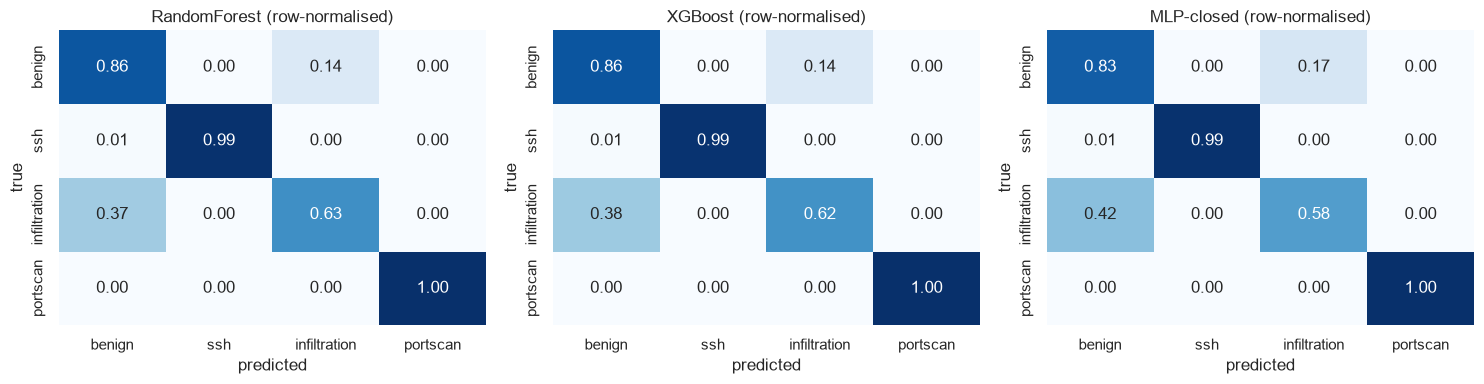

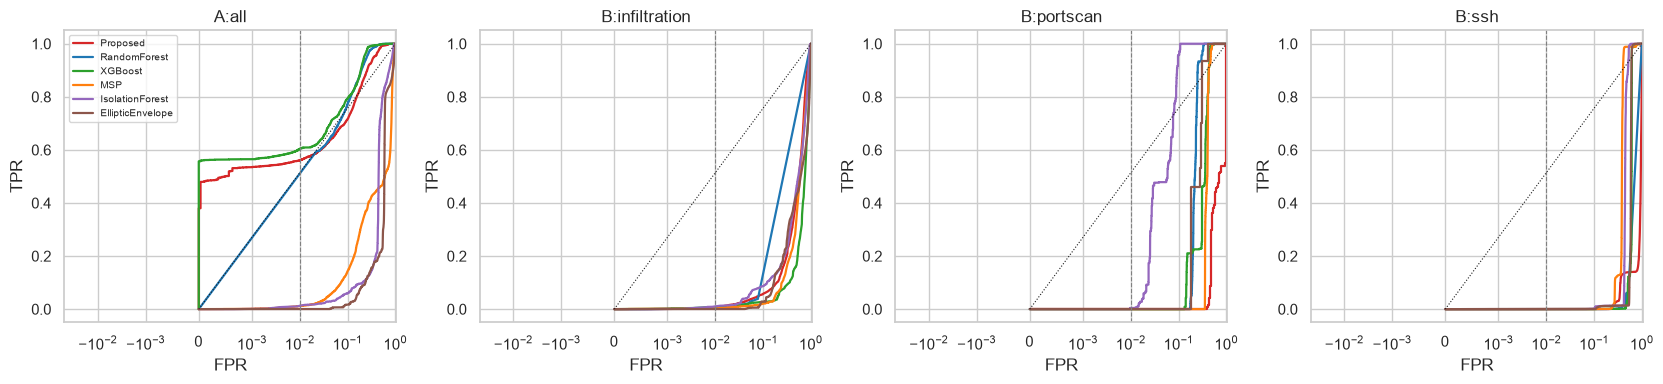

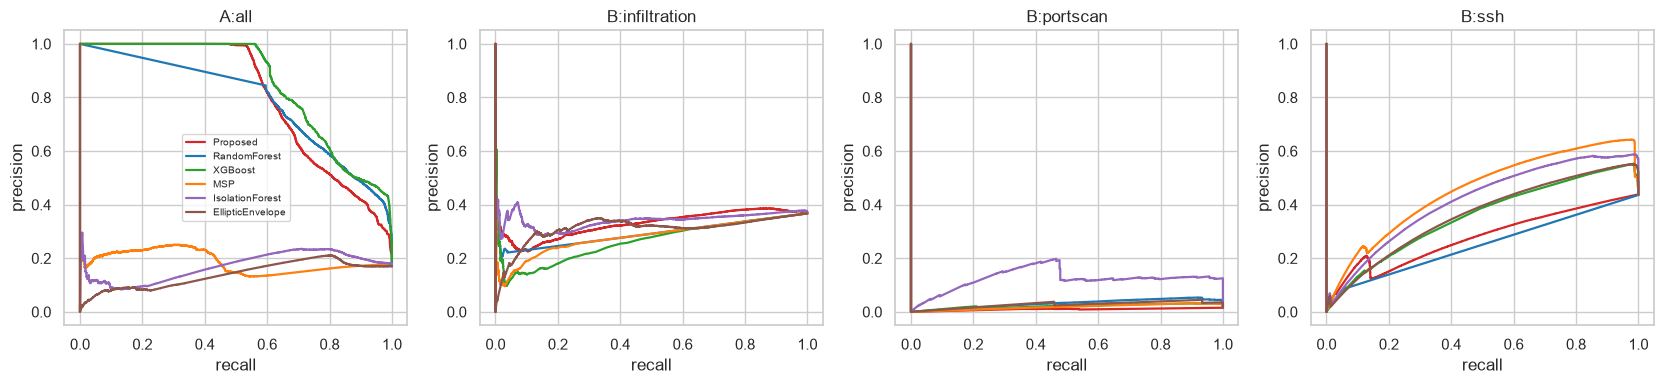

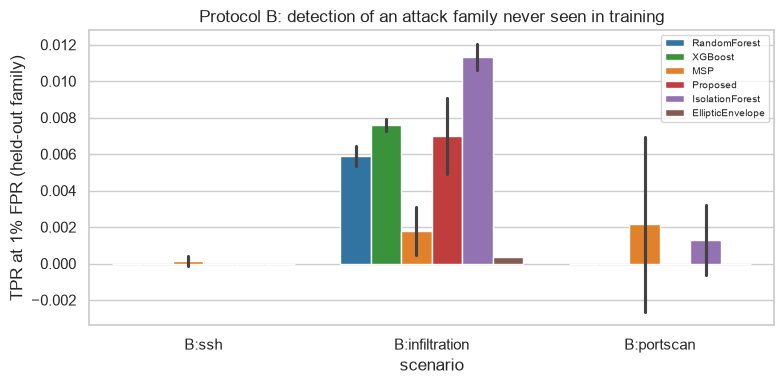

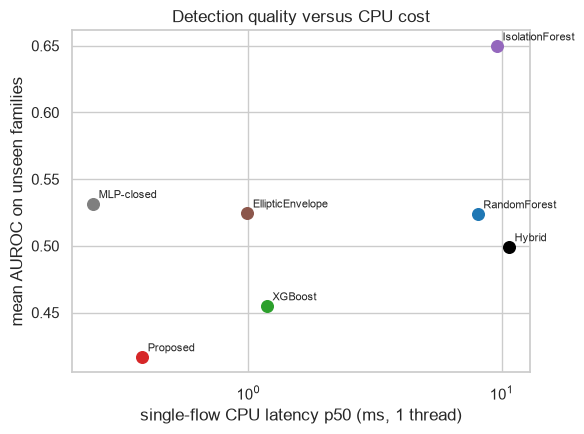

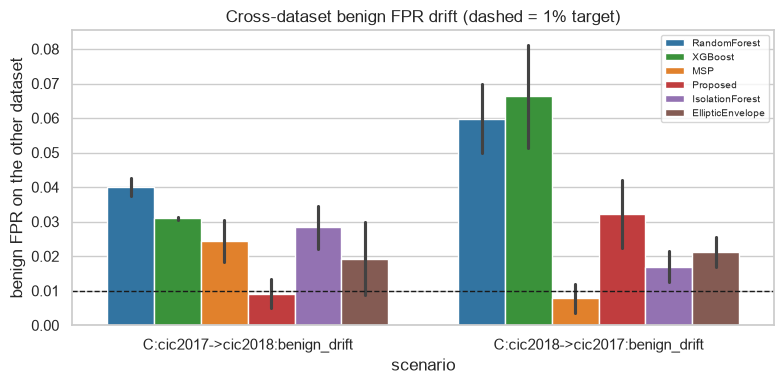

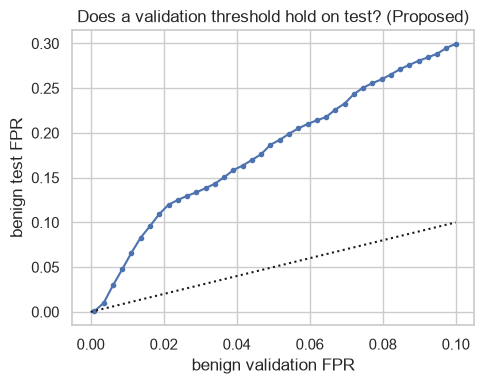

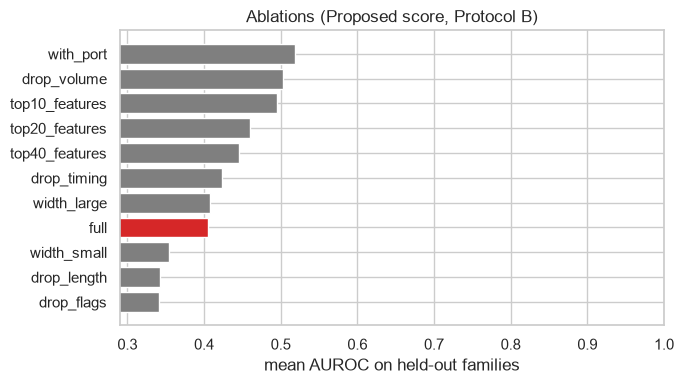

In [38]:
# Save and show a figure
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()

# Colour per method
PAL = {'Proposed': '#d62728', 'RandomForest': '#1f77b4', 'XGBoost': '#2ca02c', 'IsolationForest': '#9467bd', 'EllipticEnvelope': '#8c564b',
       'MSP': '#ff7f0e', 'MLP-closed': '#7f7f7f', 'Mahalanobis': '#bcbd22', 'Hybrid': '#000000', 'Benign-boundary': '#17becf', 'Proto-ratio': '#e377c2'}
SHOW = ['Proposed', 'RandomForest', 'XGBoost', 'MSP', 'IsolationForest', 'EllipticEnvelope']

# Fig 1: confusion matrices (Protocol A)
fam_all = ['benign'] + ATTACKS
cms = [(m, KEEP[('cm', m)]) for m in ('RandomForest', 'XGBoost', 'MLP-closed') if ('cm', m) in KEEP]
if cms:
    fig, ax = plt.subplots(1, len(cms), figsize=(5 * len(cms), 4))
    for a, (m, cm) in zip(np.atleast_1d(ax), cms):
        sns.heatmap(cm / np.maximum(cm.sum(1, keepdims=True), 1), annot=True, fmt='.2f', cmap='Blues', xticklabels=fam_all, yticklabels=fam_all, ax=a, cbar=False)
        a.set_title(f'{m} (row-normalised)')
        a.set_xlabel('predicted')
        a.set_ylabel('true')
    savefig('fig1_confusion_A.png')

# Fig 2/3: ROC and PR curves
for kind in ('roc', 'pr'):
    scens = [s for s in sorted({k[0] for k in SCORES}) if s.startswith(('A:all', 'B:'))]
    fig, axes = plt.subplots(1, len(scens), figsize=(4.2 * len(scens), 4), squeeze=False)
    for ax, sc in zip(axes[0], scens):
        for m in SHOW:
            if (sc, m) not in SCORES:
                continue
            d = SCORES[(sc, m)]
            if kind == 'roc':
                x, y_, _ = roc_curve(d['y'], d['s'])
                ax.plot(x, y_, color=PAL[m], label=m, lw=1.6)
            else:
                p, r, _ = precision_recall_curve(d['y'], d['s'])
                ax.plot(r, p, color=PAL[m], label=m, lw=1.6)
        if kind == 'roc':
            ax.plot([0, 1], [0, 1], 'k:', lw=0.8)
            ax.axvline(0.01, color='gray', ls='--', lw=0.8)
            ax.set_xlabel('FPR')
            ax.set_ylabel('TPR')
            ax.set_xscale('symlog', linthresh=1e-3)
        else:
            ax.set_xlabel('recall')
            ax.set_ylabel('precision')
        ax.set_title(sc)
    axes[0][0].legend(fontsize=7)
    savefig(f'fig2_{kind}_curves.png')

# Fig 4: unseen-family detection
if 'B' in RES_MAIN.protocol.values:
    d = RES_MAIN[(RES_MAIN.protocol == 'B') & RES_MAIN.method.isin(SHOW)]
    plt.figure(figsize=(8, 4))
    sns.barplot(data=d, x='scenario', y='tpr_at_1fpr', hue='method', palette=PAL, errorbar='sd')
    plt.ylabel('TPR at 1% FPR (held-out family)')
    plt.title('Protocol B: detection of an attack family never seen in training')
    plt.legend(fontsize=7)
    savefig('fig3_unseen_detection.png')

# Fig 5: quality vs CPU cost
q = RES_MAIN[(RES_MAIN.protocol == 'B')].groupby('method')['auroc'].mean() if 'B' in RES_MAIN.protocol.values else RES_MAIN[RES_MAIN.scenario == 'A:all'].groupby('method')['auroc'].mean()
cq = COST.join(q.rename('quality'), how='inner')
if len(cq):
    plt.figure(figsize=(6, 4.5))
    for m, r in cq.iterrows():
        plt.scatter(r.p50_ms, r.quality, s=70, color=PAL.get(m, 'k'))
        plt.annotate(m, (r.p50_ms, r.quality), fontsize=8, xytext=(4, 4), textcoords='offset points')
    plt.xscale('log')
    plt.xlabel('single-flow CPU latency p50 (ms, 1 thread)')
    plt.ylabel('mean AUROC on unseen families' if 'B' in RES_MAIN.protocol.values else 'AUROC (Protocol A)')
    plt.title('Detection quality versus CPU cost')
    savefig('fig4_quality_vs_cost.png')

# Fig 6: cross-dataset FPR drift
if len(RES_C):
    dr = RES_C[RES_C.scenario.str.endswith('benign_drift') & RES_C.method.isin(SHOW)]
    plt.figure(figsize=(8, 4))
    sns.barplot(data=dr, x='scenario', y='fpr', hue='method', palette=PAL, errorbar='sd')
    plt.axhline(FPR_TARGET, color='k', ls='--', lw=1)
    plt.ylabel('benign FPR on the other dataset')
    plt.title('Cross-dataset benign FPR drift (dashed = 1% target)')
    plt.legend(fontsize=7)
    savefig('fig5_cross_dataset_drift.png')

# Fig 7: does the validation threshold hold on test?
if 'A' in VAL_B:
    vb, tb = VAL_B['A']
    qs = np.linspace(0.90, 0.999, 40)
    th = np.quantile(vb, qs)
    fv = [(vb > t).mean() for t in th]
    ft = [(tb > t).mean() for t in th]
    plt.figure(figsize=(5, 4))
    plt.plot(fv, ft, 'o-', ms=3)
    plt.plot([0, 0.1], [0, 0.1], 'k:')
    plt.xlabel('benign validation FPR')
    plt.ylabel('benign test FPR')
    plt.title('Does a validation threshold hold on test? (Proposed)')
    savefig('fig6_threshold_stability.png')

# Fig 8: ablations (Protocol B)
if len(ABL_B):
    t = ABL_B['auroc']['mean'].sort_values()
    plt.figure(figsize=(7, 4))
    plt.barh(t.index, t.values, color=['#d62728' if i == 'full' else '#7f7f7f' for i in t.index])
    plt.xlabel('mean AUROC on held-out families')
    plt.title('Ablations (Proposed score, Protocol B)')
    plt.xlim(max(0, t.min() - 0.05), 1)
    savefig('fig7_ablation_B.png')

**Findings - figures**
* **Fig. 1 Confusion matrices:** 37-42% of infiltration predicted benign; SSH and PortScan near perfect.
* **Fig. 2 ROC and PR curves:** on A:all, XGBoost and Proposed lead at low FPR (TPR ~0.55-0.60 at 1%). On B panels all curves stay under the diagonal at low FPR (= G1 failure).
* **Fig. 3 Unseen detection:** TPR@1%FPR never above 1.2%.
* **Fig. 4 Quality vs cost:** Proposed is the 2nd cheapest (0.38 ms) but lowest on unseen AUROC (0.42). Isolation Forest is best on unseen (0.65, PortScan) at 9.6 ms. No method is both cheap and good on unseen families.
* **Fig. 5 Cross-dataset drift:** Proposed smallest for 2017 → 2018 (0.9%); for 2018 → 2017 (3.2%) about half of the trees (6.0-6.6%).
* **Fig. 6 Threshold stability:** 1% on validation → ~6% on test; 2% → ~11%.
* **Fig. 7 Ablations (B):** all variants 0.34-0.52.
* G3 figures: Section 6b. G5 figures: Sections 8 and 8b. Fig. 8 (random vs time split): Section 10b.

File names in `figures/` match these numbers (`fig1_…` to `fig8_…`).

In [39]:
# ============ Literature comparison (published numbers, not re-run) ============
LIT = pd.DataFrame([
 ['OHCE [1]', 'USTC-TFC2016, CICIDS2018-R (rebuilt)', 'open-set, random/rebuilt', 'Acc 94.38-96.97%, F1 94.02-96.16%', '0.74 ms (GPU)', 'rebuilt benchmark, GPU only'],
 ['DC-GL [2]', 'CICIDS2017, CICAndMal2017 (TLS only)', 'closed-set, random 70/30', 'Acc 97.29%, F1 97.15%', '503 s/epoch', 'random split leakage, no CPU latency'],
 ['ET-SSL [3]', 'CIC-Darknet2020, ISCX, UNSW-NB15', 'random 70/15/15', 'Acc 94.3-96.8%', '15-25 ms', 'zero-days injected into training distribution'],
 ['EVADE [5]', 'CIC-IoT-2023', 'benign-only, threshold on test', 'F1 0.982, AUROC 0.994', '1.8 ms PC / 2.74 ms RPi5', 'plain-text protocol flags, threshold tuned on test'],
 ['HERO [6]', 'BoT-IoT, Edge-IIoTset', 'held-out zero-day classes', 'Bal. acc 0.932-0.991', 'GPU only', 'unencrypted IoT data'],
 ['GCN-MHA [10]', 'ISCXVPN2016 etc.', 'closed-set random', 'Acc 98.79%, TPR@1%FPR 98.5%', '15.2 ms, 450k params', 'VPN apps treated as malicious'],
], columns=['paper', 'dataset', 'protocol', 'reported quality', 'reported cost', 'why direct comparison is unfair'])
print('PUBLISHED RESULTS (copied from the Phase 2 table; not re-run)')
save_table(LIT, 'literature_published', index=False)

# Our numbers for the same table
a_all = RES_MAIN[RES_MAIN.scenario == 'A:all']
ours = {}
for m in ('Proposed', 'RandomForest', 'XGBoost'):
    r = a_all[a_all.method == m]
    ours[m] = dict(A_auroc=r.auroc.mean(), A_tpr_at_1fpr=r.tpr_at_1fpr.mean(),
                   B_mean_auroc=RES_MAIN[(RES_MAIN.protocol == 'B') & (RES_MAIN.method == m)].auroc.mean(),
                   B_mean_unk_det=RES_MAIN[(RES_MAIN.protocol == 'B') & (RES_MAIN.method == m)].tpr.mean(),
                   cpu_p50_ms=COST.p50_ms.get(m, np.nan) if m in COST.index else np.nan,
                   params_or_nodes=COST.n_params_or_nodes.get(m, np.nan) if m in COST.index else np.nan)
OURS = pd.DataFrame(ours).T.round(4)
print('\nTHIS WORK (computed here, temporal split, threshold on validation, CPU one thread)')
save_table(OURS, 'ours_for_comparison')

PUBLISHED RESULTS (copied from the Phase 2 table; not re-run)


,paper,dataset,protocol,reported quality,reported cost,why direct comparison is unfair
0,OHCE [1],"USTC-TFC2016, CICIDS2018-R (rebuilt)","open-set, random/rebuilt","Acc 94.38-96.97%, F1 94.02-96.16%",0.74 ms (GPU),"rebuilt benchmark, GPU only"
1,DC-GL [2],"CICIDS2017, CICAndMal2017 (TLS only)","closed-set, random 70/30","Acc 97.29%, F1 97.15%",503 s/epoch,"random split leakage, no CPU latency"
2,ET-SSL [3],"CIC-Darknet2020, ISCX, UNSW-NB15",random 70/15/15,Acc 94.3-96.8%,15-25 ms,zero-days injected into training distribution
3,EVADE [5],CIC-IoT-2023,"benign-only, threshold on test","F1 0.982, AUROC 0.994",1.8 ms PC / 2.74 ms RPi5,"plain-text protocol flags, threshold tuned on ..."
4,HERO [6],"BoT-IoT, Edge-IIoTset",held-out zero-day classes,Bal. acc 0.932-0.991,GPU only,unencrypted IoT data
5,GCN-MHA [10],ISCXVPN2016 etc.,closed-set random,"Acc 98.79%, TPR@1%FPR 98.5%","15.2 ms, 450k params",VPN apps treated as malicious



THIS WORK (computed here, temporal split, threshold on validation, CPU one thread)


,A_auroc,A_tpr_at_1fpr,B_mean_auroc,B_mean_unk_det,cpu_p50_ms,params_or_nodes
Proposed,0.9222,0.5559,0.4168,0.0030,0.3810,7092.0
RandomForest,0.9395,0.2273,0.5240,0.0169,8.0543,467608.0
XGBoost,0.9500,0.6046,0.4550,0.0612,1.1838,19842.0


,A_auroc,A_tpr_at_1fpr,B_mean_auroc,B_mean_unk_det,cpu_p50_ms,params_or_nodes
Proposed,0.9222,0.5559,0.4168,0.0030,0.3810,7092.0
RandomForest,0.9395,0.2273,0.5240,0.0169,8.0543,467608.0
XGBoost,0.9500,0.6046,0.4550,0.0612,1.1838,19842.0


**Findings - comparison with published work**
* Papers report 94-99% accuracy (OHCE, DC-GL, ET-SSL, GCN-MHA) or AUROC 0.994 (EVADE). We get 0.92-0.95 AUROC on known attacks, and AUROC ≈ 0.42 on unseen families, TPR@1%FPR ≈ 0.
* **Not a fair comparison:**
  1. Most papers use **random** splits (near-copies in train and test); we use **time** splits after removing 470,510 duplicates.
  2. EVADE tunes its threshold on test data; we use validation only.
  3. Some report GPU or per-epoch cost; we report one CPU thread.
  4. ET-SSL's "zero-days" are in the training distribution; ours never are.
* **What we can say:** at a fair setup known attacks are still detectable (0.92-0.95), but open-set claims do not reproduce on encrypted-port CICIDS flows. Our detector (0.38 ms on one CPU thread) is about 2-65× faster than the reported costs.
* Packet-sequence and hash-centre baselines were not re-implemented (CSVs have no packets).
* **Section 10b** measures the effect directly: with a random split our Random Forest reaches 95.9% accuracy, close to the 97.3% of DC-GL.

## 10b. Random split vs our time split
**Why:** papers report 94-99% accuracy with **random** splits and duplicates kept. We re-run Protocol A with the *same* models, features and threshold rule under three settings:

| Setting | Data | Split |
|---|---|---|
| `temporal` (ours, Sec. 5) | cleaned (no duplicates / conflicts) | by time |
| `random_clean` | same cleaned data | random |
| `random_dups` (paper-like) | duplicates and conflicts **kept**, same caps | random |

Leakage of `random_dups` is measured directly (% of test flows also in training). Models: RF, XGBoost, MLP (gives MLP-closed, Proposed, Hybrid), seeds 0-2.

**Expectation:** random settings score higher and get closer to 1% FPR; random_dups scores highest.

In [40]:
# ============ 10b-0. Restore saved state (no need to re-run Sections 1-9) ============
_need = [n for n in ('Preproc', 'fit_detectors', 'run_scenarios', 'binary_metrics', 'OUT', 'SPLIT') if n not in globals()]
assert not _need, ('Run these cells first: Section 0 imports + configuration, Section 4 method code, '
                   f'Section 5 first code cell (run_scenarios). Missing: {_need}')

# Load the saved dataset, features and Section 5 results if they are not in memory
if 'M' not in globals():
    M = pd.read_parquet(OUT / 'master.parquet')
    print(f'loaded master.parquet: {len(M):,} flows')
if 'SHARED' not in globals():
    SHARED = json.load(open(OUT / 'schema.json'))['shared']
if 'FEATS' not in globals():
    FEATS = [f for f in SHARED if f in M.columns]
if 'SOURCES' not in globals():
    SOURCES = sorted(M.source.unique())
if 'ATTACKS' not in globals():
    _fc = M.groupby('family').size()
    ATTACKS = [f for f in ['ssh', 'infiltration', 'portscan'] if _fc.get(f, 0) >= MIN_FAMILY_FLOWS]
if 'RES_MAIN' not in globals():
    RES_MAIN = pd.read_csv(TAB_DIR / 'results_main_AB.csv')
    print(f'loaded results_main_AB.csv: {len(RES_MAIN):,} rows')

print(f'flows: {len(M):,} | features: {len(FEATS)} | sources: {SOURCES} | attack families: {ATTACKS}')
print(M.groupby(['source', 'family', 'split']).size().unstack(fill_value=0))

flows: 241,109 | features: 76 | sources: ['cic2017', 'cic2018'] | attack families: ['ssh', 'infiltration', 'portscan']
split                  test  train    val
source  family                           
cic2017 benign        15000  70000  15000
        portscan         69    327     70
        ssh             482   2254    483
cic2018 benign        14999  69999  15000
        infiltration   2613  12199   2614
        ssh            3000  14000   3000


In [41]:
# ============ 10b-1. Build random-split datasets and run Protocol A ============

# Settings
RAND_SEEDS   = SEEDS[:3]
RAND_METHODS = ('RF', 'XGB', 'MLP')  # MLP gives MLP-closed, Proposed and Hybrid
RAND_SCEN    = ('A',)  # add 'B' to also run leave-one-family-out under the random split (about 3x longer)
FORCE_RANDOM = False
RAND_FILE    = TAB_DIR / 'results_random_split.csv'
LEAK_FILE    = TAB_DIR / 'random_split_leakage.csv'

# Raw label -> family (same as Section 3)
RAW_LABEL_MAP = {'benign': 'benign', 'ssh-bruteforce': 'ssh', 'ssh-patator': 'ssh',
                 'infilteration': 'infiltration', 'infiltration': 'infiltration', 'portscan': 'portscan'}

# Random 70/15/15 split inside each (source, family)
def random_split(df, seed=0, split=SPLIT):
    # 70/15/15 random split inside each (source, family), the same proportions as the temporal split
    df = df.reset_index(drop=True).copy()
    rs = np.random.RandomState(seed)
    lab = np.empty(len(df), dtype=object)
    for _, idx in sorted(df.groupby(['source', 'family']).indices.items()):
        idx = rs.permutation(idx)
        n = len(idx)
        a, b = int(round(split[0] * n)), int(round((split[0] + split[1]) * n))
        lab[idx[:a]], lab[idx[a:b]], lab[idx[b:]] = 'train', 'val', 'test'
    df['split'] = lab
    return df

# Same file-stratified cap as Section 3
def _strat(d, n, seed=0):
    # same file-stratified cap as Section 3
    if len(d) <= n:
        return d
    frac = n / len(d)
    return pd.concat([g.sample(frac=frac, random_state=seed) for _, g in d.groupby('file')])

# Paper-like data: duplicates and label conflicts kept
def build_with_duplicates():
    # Paper-like data: label mapping and inf/NaN/negative-duration cleaning only. Duplicates and label conflicts are KEPT.
    keep_cols = list(dict.fromkeys(FEATS + ['source', 'file', 'label_raw', 'dstport']))
    parts = []
    for p in sorted(PQ_DIR.glob('*.parquet')):
        d = pd.read_parquet(p)
        d = d[[c for c in keep_cols if c in d.columns]]
        d['family'] = d['label_raw'].astype(str).str.strip().str.lower().map(RAW_LABEL_MAP)
        parts.append(d[d.family.isin(['benign'] + ATTACKS)])
    D = pd.concat(parts, ignore_index=True)
    del parts
    gc.collect()
    X = D[FEATS].replace([np.inf, -np.inf], np.nan)
    ok = X.notna().all(axis=1).values & (D['flow_duration'].values >= 0)
    D = D.loc[ok]
    del X
    gc.collect()
    pieces = []
    for s in SOURCES:  # same caps as Section 3 (benign ~100k incl. up to 20k on port 22, SSH 20k)
        b = D[(D.source == s) & (D.family == 'benign')]
        b22, bo = b[b.dstport == 22], b[b.dstport != 22]
        k22 = _strat(b22, BENIGN_PORT22_CAP)
        pieces += [k22, _strat(bo, max(BENIGN_CAP_PER_SOURCE - len(k22), 0)),
                   _strat(D[(D.source == s) & (D.family == 'ssh')], SSH_CAP_PER_SOURCE)]
    pieces.append(D[~D.family.isin(['benign', 'ssh'])])
    out = pd.concat(pieces, ignore_index=True)
    del D, pieces
    gc.collect()
    return out

# Share of test flows that also appear in training
def leak_stats(df, name):
    # share of test flows whose exact feature vector is also in the training split (and with a different family label)
    h = pd.util.hash_pandas_object(df[FEATS], index=False).values
    tr, te = (df.split == 'train').values, (df.split == 'test').values
    tr_h = pd.Series(df.family.values[tr], index=h[tr])
    in_tr = np.isin(h[te], tr_h.index.values)
    fam_tr = tr_h.groupby(level=0).agg(lambda v: set(v))
    te_fam = df.family.values[te]
    diff = np.array([hh in fam_tr.index and f not in fam_tr[hh] for hh, f in zip(h[te], te_fam)])
    r = dict(setting=name, n_flows=len(df), n_test=int(te.sum()),
             test_in_train_pct=round(100 * in_tr.mean(), 2), test_in_train_other_label_pct=round(100 * diff.mean(), 2))
    for fam in ['benign'] + ATTACKS:
        m = te_fam == fam
        if m.any():
            r[f'{fam}_test_in_train_pct'] = round(100 * in_tr[m].mean(), 2)
    return r

# Run Protocol A on another dataset (swaps the global M, then restores it)
def run_on(data, tag):
    # run_scenarios reads the global M, so swap it for the duration of the call and always restore it
    global M
    _M = M
    M = data
    try:
        return run_scenarios(tag, FEATS, RAND_SEEDS, RAND_METHODS, scen=RAND_SCEN)
    finally:
        M = _M

# Use saved results if present, else build and run
if RAND_FILE.exists() and LEAK_FILE.exists() and not FORCE_RANDOM:
    RES_RAND = pd.read_csv(RAND_FILE)
    LEAK = pd.read_csv(LEAK_FILE)
    print('loaded cached random-split results:', RAND_FILE)
else:
    t0 = time.time()
    M_RC = random_split(M, seed=0)
    print(f'random_clean: {len(M_RC):,} flows')
    M_RD = random_split(build_with_duplicates(), seed=0)
    print(f'random_dups:  {len(M_RD):,} flows (built in {time.time() - t0:.0f}s)')
    print(M_RD.groupby(['source', 'family']).size().unstack(fill_value=0))
    LEAK = pd.DataFrame([leak_stats(M, 'temporal'), leak_stats(M_RC, 'random_clean'), leak_stats(M_RD, 'random_dups')])
    LEAK.to_csv(LEAK_FILE, index=False)
    res = [run_on(M_RC, 'random_clean')]
    del M_RC
    gc.collect()
    res.append(run_on(M_RD, 'random_dups'))
    del M_RD
    gc.collect()
    RES_RAND = pd.concat(res, ignore_index=True)
    RES_RAND.to_csv(RAND_FILE, index=False)
    print(f'random-split runs finished in {(time.time() - t0) / 60:.1f} min')

print('\nLEAKAGE: share of test flows whose exact feature vector also occurs in the training split (%)')
display(LEAK.set_index('setting'))

loaded cached random-split results: D:\Projects\FAST-NUCES\Cnet\CNET-Project\Outputs\tables\results_random_split.csv

LEAKAGE: share of test flows whose exact feature vector also occurs in the training split (%)


,n_flows,n_test,test_in_train_pct,test_in_train_other_label_pct,benign_test_in_train_pct,ssh_test_in_train_pct,infiltration_test_in_train_pct,portscan_test_in_train_pct
setting,,,,,,,,
temporal,241109,36163,0.0,0.00,0.00,0.00,0.00,0.00
random_clean,241109,36167,0.0,0.00,0.00,0.00,0.00,0.00
random_dups,257305,38596,13.5,1.11,8.94,47.93,12.17,68.45


PROTOCOL A UNDER THREE EVALUATION SETTINGS (mean over seeds [0, 1, 2] ; threshold = 1% FPR on benign validation)


auroc  pr_auc  tpr_at_1fpr  realised_fpr      f1  \
setting      method                                                            
temporal     RandomForest  0.9390  0.7639       0.1922        0.1668  0.6462   
             XGBoost       0.9500  0.8490       0.6040        0.1555  0.6512   
             MLP-closed    0.9322  0.8035       0.5712        0.0802  0.6511   
             Proposed      0.9203  0.7968       0.5556        0.0516  0.6805   
             Hybrid        0.9379  0.7964       0.4621        0.1579  0.6453   
random_clean RandomForest  0.9891  0.9585       0.8143        0.0097  0.8727   
             XGBoost       0.9883  0.9554       0.8174        0.0102  0.8763   
             MLP-closed    0.9596  0.8680       0.6215        0.0109  0.7447   
             Proposed      0.9368  0.7877       0.4993        0.0098  0.6445   
             Hybrid        0.9824  0.9384       0.7293        0.0099  0.8204   
random_dups  RandomForest  0.9719  0.9201       0.6372        0.0103  0.7641   
             XGBoost       0.9712  0.9195       0.6482        0.0100  0.7704   
             MLP-closed    0.9364  0.8390       0.5245        0.0103  0.6731   
             Proposed      0.8830  0.6848       0.3195        0.0095  0.4735   
             Hybrid        0.9554  0.8850       0.5642        0.0100  0.7076   

                           accuracy  macro_f1  
setting      method                            
temporal     RandomForest    0.8523    0.8209  
             XGBoost         0.8530    0.8210  
             MLP-closed      0.8261    0.7882  
             Proposed           NaN       NaN  
             Hybrid             NaN       NaN  
random_clean RandomForest    0.9592    0.9267  
             XGBoost         0.9503    0.9152  
             MLP-closed      0.8648    0.8360  
             Proposed           NaN       NaN  
             Hybrid             NaN       NaN  
random_dups  RandomForest    0.9004    0.8943  
             XGBoost         0.8858    0.8875  
             MLP-closed      0.8246    0.8431  
             Proposed           NaN       NaN  
             Hybrid             NaN       NaN


INFLATION: random setting minus temporal (positive = the random split looks better; realised_fpr: negative = better)


auroc  pr_auc  tpr_at_1fpr  realised_fpr      f1  \
setting      method                                                            
random_clean RandomForest  0.0501  0.1946       0.6221       -0.1571  0.2265   
             XGBoost       0.0383  0.1064       0.2134       -0.1453  0.2251   
             MLP-closed    0.0274  0.0645       0.0503       -0.0693  0.0936   
             Proposed      0.0165 -0.0091      -0.0563       -0.0418 -0.0360   
             Hybrid        0.0445  0.1420       0.2672       -0.1480  0.1751   
random_dups  RandomForest  0.0329  0.1562       0.4450       -0.1565  0.1179   
             XGBoost       0.0212  0.0705       0.0442       -0.1455  0.1192   
             MLP-closed    0.0042  0.0355      -0.0467       -0.0699  0.0220   
             Proposed     -0.0373 -0.1120      -0.2361       -0.0421 -0.2070   
             Hybrid        0.0175  0.0886       0.1021       -0.1479  0.0623   

                           accuracy  macro_f1  
setting      method                            
random_clean RandomForest    0.1069    0.1058  
             XGBoost         0.0973    0.0942  
             MLP-closed      0.0387    0.0478  
             Proposed           NaN       NaN  
             Hybrid             NaN       NaN  
random_dups  RandomForest    0.0481    0.0734  
             XGBoost         0.0328    0.0665  
             MLP-closed     -0.0015    0.0549  
             Proposed           NaN       NaN  
             Hybrid             NaN       NaN


PER-FAMILY AUROC (A sub-tests) by setting


tag                          temporal  random_clean  random_dups
scenario       method                                           
A:infiltration Hybrid          0.7499        0.9211       0.8599
               MLP-closed      0.6760        0.8045       0.7534
               Proposed        0.6502        0.7480       0.6682
               RandomForest    0.7671        0.9490       0.8901
               XGBoost         0.7744        0.9450       0.8871
A:portscan     Hybrid          0.9999        0.9999       0.9994
               MLP-closed      0.9996        1.0000       1.0000
               Proposed        0.9992        0.9925       0.9770
               RandomForest    1.0000        1.0000       0.9999
               XGBoost         1.0000        1.0000       0.9999
A:ssh          Hybrid          0.9864        0.9998       0.9999
               MLP-closed      0.9961        0.9996       0.9988
               Proposed        0.9984        0.9970       0.9956
               RandomForest    0.9712        0.9998       0.9999
               XGBoost         0.9933        0.9995       0.9999

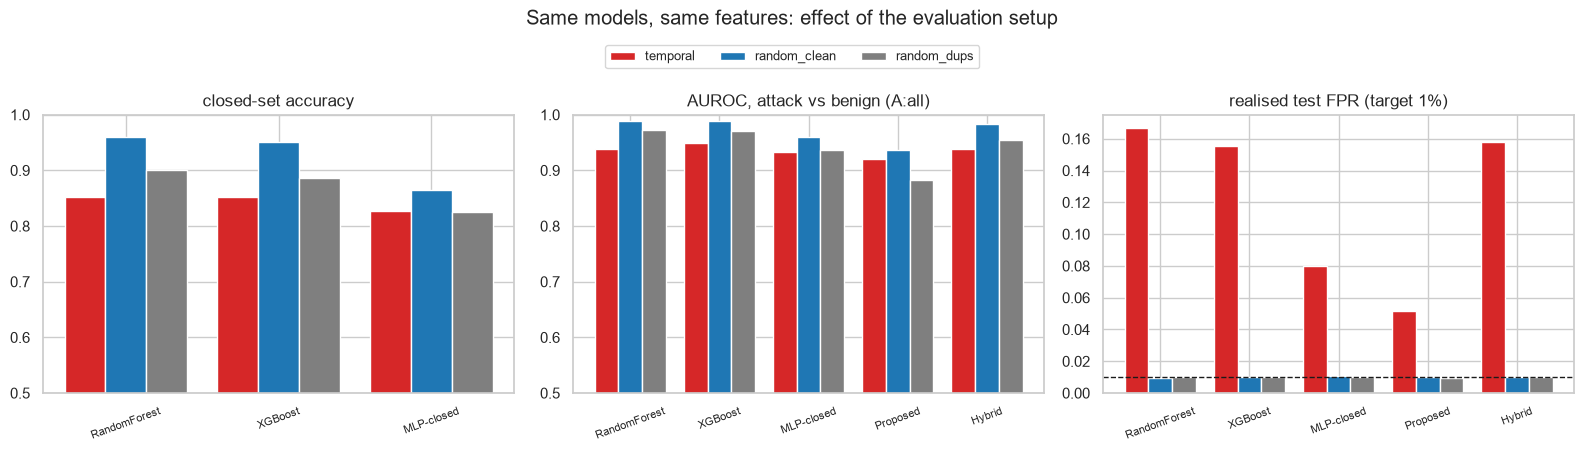


LITERATURE vs THIS WORK UNDER THE SAME KIND OF SPLIT (published numbers are not re-run; datasets differ)


,system,source,accuracy,macro_f1,auroc
0,"DC-GL [2] (CICIDS2017, random 70/30)",reported,0.9729,0.9715,NaN
1,"GCN-MHA [10] (ISCXVPN2016, random)",reported,0.9879,NaN,NaN
2,"EVADE [5] (CIC-IoT-2023, threshold on test)",reported,NaN,NaN,0.9940
3,"This work, XGBoost, temporal",computed here,0.8530,0.8210,0.9500
4,"This work, RandomForest, temporal",computed here,0.8523,0.8209,0.9390
5,"This work, MLP-closed, temporal",computed here,0.8261,0.7882,0.9322
6,"This work, XGBoost, random_clean",computed here,0.9503,0.9152,0.9883
7,"This work, RandomForest, random_clean",computed here,0.9592,0.9267,0.9891
8,"This work, MLP-closed, random_clean",computed here,0.8648,0.8360,0.9596
9,"This work, XGBoost, random_dups",computed here,0.8858,0.8875,0.9712



KEY NUMBERS
XGBoost       AUROC temporal/random_clean/random_dups = 0.950 / 0.988 / 0.971 | accuracy = 0.853 / 0.950 / 0.886 | realised FPR = 0.155 / 0.010 / 0.010
RandomForest  AUROC temporal/random_clean/random_dups = 0.939 / 0.989 / 0.972 | accuracy = 0.852 / 0.959 / 0.900 | realised FPR = 0.167 / 0.010 / 0.010
MLP-closed    AUROC temporal/random_clean/random_dups = 0.932 / 0.960 / 0.936 | accuracy = 0.826 / 0.865 / 0.825 | realised FPR = 0.080 / 0.011 / 0.010
Proposed      AUROC temporal/random_clean/random_dups = 0.920 / 0.937 / 0.883 | accuracy = nan / nan / nan | realised FPR = 0.052 / 0.010 / 0.009
test flows with an identical training vector (%): {'temporal': 0.0, 'random_clean': 0.0, 'random_dups': 13.5}


In [42]:
# ============ 10b-2. Temporal vs random split: tables, figure, literature ============

# Put temporal and random results side by side
SHOW_R = ['RandomForest', 'XGBoost', 'MLP-closed', 'Proposed', 'Hybrid']
SETTINGS = ['temporal', 'random_clean', 'random_dups']
TEMP = RES_MAIN[(RES_MAIN.tag == 'main') & RES_MAIN.seed.isin(RAND_SEEDS) & (RES_MAIN.protocol == 'A')].copy()
TEMP['tag'] = 'temporal'
ALLR = pd.concat([TEMP, RES_RAND[RES_RAND.protocol == 'A']], ignore_index=True)
ALLR = ALLR[ALLR.method.isin(SHOW_R)]

# Main comparison table
det = ALLR[ALLR.scenario == 'A:all'].groupby(['tag', 'method'])[['auroc', 'pr_auc', 'tpr_at_1fpr', 'fpr', 'f1']].mean()
clo = ALLR[ALLR.scenario == 'A:closed'].groupby(['tag', 'method'])[['accuracy', 'macro_f1']].mean()
CMP = det.join(clo, how='left').rename(columns={'fpr': 'realised_fpr'})
CMP = CMP.reindex(pd.MultiIndex.from_product([SETTINGS, SHOW_R], names=['setting', 'method'])).dropna(how='all').round(4)
print('PROTOCOL A UNDER THREE EVALUATION SETTINGS (mean over seeds', RAND_SEEDS, '; threshold = 1% FPR on benign validation)')
save_table(CMP, 'random_vs_temporal_A')

# How much better does a random split look?
print('\nINFLATION: random setting minus temporal (positive = the random split looks better; realised_fpr: negative = better)')
INFL = pd.concat({s: (CMP.loc[s] - CMP.loc['temporal']) for s in SETTINGS[1:] if s in CMP.index.get_level_values(0)}, names=['setting'])
save_table(INFL.round(4), 'random_split_inflation')

# Per-family AUROC
sub = ALLR[ALLR.scenario.isin(['A:ssh', 'A:infiltration', 'A:portscan'])].groupby(['scenario', 'method', 'tag'])['auroc'].mean().unstack('tag')
print('\nPER-FAMILY AUROC (A sub-tests) by setting')
save_table(sub.reindex(columns=SETTINGS).round(4), 'random_vs_temporal_families')

# ---- figure
COLS = {'temporal': '#d62728', 'random_clean': '#1f77b4', 'random_dups': '#7f7f7f'}
panels = [('accuracy', 'closed-set accuracy', ['RandomForest', 'XGBoost', 'MLP-closed']),
          ('auroc', 'AUROC, attack vs benign (A:all)', SHOW_R),
          ('realised_fpr', 'realised test FPR (target 1%)', SHOW_R)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (col, title, meths) in zip(axes, panels):
    w = 0.8 / len(SETTINGS)
    x = np.arange(len(meths))
    for i, s in enumerate(SETTINGS):
        v = [CMP.loc[(s, m), col] if (s, m) in CMP.index else np.nan for m in meths]
        ax.bar(x + (i - 1) * w, v, w, label=s, color=COLS[s])
    ax.set_xticks(x)
    ax.set_xticklabels(meths, rotation=20, fontsize=8)
    ax.set_title(title)
    if col == 'realised_fpr':
        ax.axhline(FPR_TARGET, color='k', ls='--', lw=1)
    else:
        ax.set_ylim(0.5, 1.0)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc='upper center', ncol=3, fontsize=9, bbox_to_anchor=(0.5, 1.0))
plt.suptitle('Same models, same features: effect of the evaluation setup', y=1.07)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig8_random_vs_temporal.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- literature comparison, now with a like-for-like (random split) row of our own
def _g(s, m, c):
    return CMP.loc[(s, m), c] if (s, m) in CMP.index and pd.notna(CMP.loc[(s, m), c]) else np.nan
LIT2 = pd.DataFrame([
    ['DC-GL [2] (CICIDS2017, random 70/30)', 'reported', 0.9729, 0.9715, np.nan],
    ['GCN-MHA [10] (ISCXVPN2016, random)', 'reported', 0.9879, np.nan, np.nan],
    ['EVADE [5] (CIC-IoT-2023, threshold on test)', 'reported', np.nan, np.nan, 0.994],
] + [[f'This work, {m}, {s}', 'computed here', _g(s, m, 'accuracy'), _g(s, m, 'macro_f1'), _g(s, m, 'auroc')]
     for s in SETTINGS for m in ['XGBoost', 'RandomForest', 'MLP-closed']],
    columns=['system', 'source', 'accuracy', 'macro_f1', 'auroc'])
print('\nLITERATURE vs THIS WORK UNDER THE SAME KIND OF SPLIT (published numbers are not re-run; datasets differ)')
save_table(LIT2.round(4), 'literature_vs_random_split', index=False)

# ---- key numbers (interpretation goes in the Findings cell below)
print('\nKEY NUMBERS')
for m in ['XGBoost', 'RandomForest', 'MLP-closed', 'Proposed']:
    a = [_g(s, m, 'auroc') for s in SETTINGS]
    acc = [_g(s, m, 'accuracy') for s in SETTINGS]
    f = [_g(s, m, 'realised_fpr') for s in SETTINGS]
    print(f'{m:13s} AUROC temporal/random_clean/random_dups = {a[0]:.3f} / {a[1]:.3f} / {a[2]:.3f} | '
          f'accuracy = {acc[0]:.3f} / {acc[1]:.3f} / {acc[2]:.3f} | realised FPR = {f[0]:.3f} / {f[1]:.3f} / {f[2]:.3f}')
print('test flows with an identical training vector (%):', LEAK.set_index('setting')['test_in_train_pct'].to_dict())

**Findings - random vs time split**
* **Leakage:** with duplicates kept (`random_dups`), **13.5%** of test flows also appear in training (PortScan 68.5%, SSH 47.9%, infiltration 12.2%, benign 8.9%); 1.1% appear with a different label. Both cleaned settings have 0%.
* **A random split makes every tree model look much better.** On the same cleaned data, Random Forest goes from AUROC 0.939 to **0.989** and accuracy 85.2% to **95.9%**; XGBoost from 0.950 to **0.988** and 85.3% to **95.0%**. TPR@1%FPR rises from 0.19 / 0.60 to about 0.81.
* **The false-alarm drift disappears:** realised FPR is 1.0% for every method with a random split, against 5-17% with the time split. The drift seen in Sections 5 and 9 is a time effect, not a weakness of one model.
* **Infiltration gains the most** (RF 0.767 → 0.949, XGBoost 0.774 → 0.945); SSH and PortScan are already near 1.0.
* **Proposed gains little** (AUROC 0.920 → 0.937) and drops with duplicates (0.883). Likely reason: its open-set score depends on a clean benign boundary, which duplicated and conflicting flows blur.
* **Expectation only partly confirmed:** `random_dups` scores *below* `random_clean` (RF accuracy 90.0% vs 95.9%). Keeping duplicates also keeps the label conflicts (infiltration flows identical to benign), which adds label noise.
* **Literature:** with a random split our Random Forest reaches 95.9% accuracy and 0.927 macro-F1, close to DC-GL's 97.3% / 0.972 on CICIDS2017. Most of the gap to published numbers comes from the evaluation setup, not the model.

In [43]:
# ============ Key numbers (computed) ============
print('KEY FINDINGS (computed)\n')

# Best method per held-out family
if 'B' in RES_MAIN.protocol.values:
    t = RES_MAIN[RES_MAIN.protocol == 'B'].groupby(['scenario', 'method'])['auroc'].mean().unstack()
    for sc in t.index:
        best = t.loc[sc].idxmax()
        print(f'{sc}: best AUROC = {best} ({t.loc[sc].max():.3f}); Proposed = {t.loc[sc].get("Proposed", np.nan):.3f}; RF = {t.loc[sc].get("RandomForest", np.nan):.3f}; IF = {t.loc[sc].get("IsolationForest", np.nan):.3f}')
    cs = RES_MAIN[(RES_MAIN.protocol == 'B') & (RES_MAIN.method == 'Proposed')].groupby('scenario')[['closed_macro_f1', 'unk_det', 'fpr']].mean().round(3)
    print('\nclosed-set macro-F1 vs unknown-flow detection vs benign FPR (Proposed):')
    display(cs)
print('\nclosed-set Protocol A macro-F1 (mean):', RES_MAIN[RES_MAIN.scenario == 'A:closed'].groupby('method')['macro_f1'].mean().round(3).to_dict())
if len(RES_C):
    print('benign FPR drift (mean, Proposed):', RES_C[RES_C.scenario.str.endswith('benign_drift') & (RES_C.method == 'Proposed')].groupby('scenario')['fpr'].mean().round(3).to_dict())
print('cost (p50 ms):', COST.p50_ms.round(3).to_dict())
print('SHAP:', {k: v for k, v in SHAPR.items() if k != 'top10_tree'})

KEY FINDINGS (computed)

B:infiltration: best AUROC = Benign-boundary (0.520); Proposed = 0.502; RF = 0.475; IF = 0.480
B:portscan: best AUROC = IsolationForest (0.944); Proposed = 0.470; RF = 0.773; IF = 0.944
B:ssh: best AUROC = MSP (0.643); Proposed = 0.278; RF = 0.324; IF = 0.526

closed-set macro-F1 vs unknown-flow detection vs benign FPR (Proposed):


,closed_macro_f1,unk_det,fpr
scenario,,,
B:infiltration,0.957,0.009,0.013
B:portscan,0.730,0.000,0.060
B:ssh,0.732,0.000,0.041



closed-set Protocol A macro-F1 (mean): {'MLP-closed': 0.788, 'RandomForest': 0.821, 'XGBoost': 0.821}
benign FPR drift (mean, Proposed): {'C:cic2017->cic2018:benign_drift': 0.009, 'C:cic2018->cic2017:benign_drift': 0.032}
cost (p50 ms): {'RandomForest': 8.054, 'XGBoost': 1.184, 'MLP-closed': 0.244, 'Proposed': 0.381, 'Hybrid': 10.699, 'IsolationForest': 9.589, 'EllipticEnvelope': 0.991}
SHAP: {'fidelity': 0.9982077908386484, 't_tree_ms': 0.10147572815962456, 't_kernel_ms': 34.821479999967174, 'jaccard_tree_vs_kernel': 0.1111111111111111, 'spearman_tree_vs_kernel': 0.17864655013486022, 'xsrc_jaccard_top10': 0.6666666666666666, 'xsrc_spearman': 0.9129884086896445, 'xsrc_families': ['ssh']}


**Key numbers** (agree with the tables above): best unseen AUROC 0.520 (infiltration, Benign-boundary), 0.944 (PortScan, Isolation Forest), 0.643 (SSH, MSP). Known-class macro-F1 0.73-0.96. Proposed FPR drift 0.9% / 3.2%. Proposed latency 0.38 ms.

## Changes from the Phase 2 plan
| # | Phase 2 plan | Phase 3 | Reason |
|---|---|---|---|
| 1 | First 10 packets, 1D-CNN/GRU | Flow statistics + MLP | CSVs have flow statistics, not packets; PCAPs too large; USTC-TFC2016 gave 0 TLS flows |
| 2 | 5 datasets | CICIDS-2017 and CSE-CIC-IDS2018 | Others have no usable attack labels (Darknet: app labels; USTC extraction failed) |
| 3 | TLS-filtered flows | Secure-port filter {22, 443, 465, 993, 995, 8443} | CSVs have no TLS fields (port = proxy) |
| 4 | 5-fold CV, 5 seeds | Time split 70/15/15, 5 seeds | Random CV leaks time |
| 5 | TLS handshake features | Not available | Same as 1 |
| 6 | Drift windows (G4, Protocol D) | **Removed** | Scope; G4 not claimed |
| 7 | Boruta/SHAP feature selection | RF importance top-k | Cheaper; fitted on training data |
| 8 | Drop negative window sizes | Kept (counted) | -1 = "no value" |
| 9 | 500k-row chunks | 250k | RAM |
| 10 | Hash-centre, CNN-GCN-LSTM baselines | Compared from papers only | Need packets / graphs |
| 11 | Edge latency | Laptop CPU, one thread | No Raspberry Pi |

### Changes made during Phase 3 (G3 and G5)
| # | Change | Reason |
|---|---|---|
| 12 | Recalibration on unlabeled benign target flows (C2) | FPR drift up to 3.2% vs 1% target |
| 13 | IG on the detector + deletion, stability and agreement tests | Surrogate TreeSHAP agreed poorly (Jaccard 0.11) |
| 14 | Verdicts from criteria written before each run | No moving the goalposts |
| 15 | Explicit 2017 file order | Friday / Thursday files were mixed, so the 2017 split was not chronological |
| 16 | `A:infiltration` uses 2018 benign only | Avoids mixing family with dataset |
| 17 | Leakage / confound report (3b) | Count conflicts and duplicates; show days per split |
| 18 | C3 replaces C2 as main G3 test (C2 still reported) | Four design bugs in C2 |
| 19 | Extended G5 tests (8c; 8b still reported) | Four measurement bugs in 8b |
| 20 | Remove label conflicts; keep cross-dataset duplicates once | 850 conflict vectors, 667 cross-split, 80 cross-dataset found |
| 21 | Quantile preprocessing (`QPreproc`) | Detector relied on shifting features |
| 22 | Hybrid detector | RF relied on less-shifted features |
| 23 | Daily recalibration | Most FPR error is time drift |
| 24 | Expected Gradients replaces IG | The benign-mean baseline is not a realistic flow |
| 25 | F3 check uses only the named baselines | v2 tested one extra baseline |
| 26 | C3 fits RF + MLP only; 2 secondary analyses removed | v2 C3 took ~9 h |

Original verdicts (G3 C2: 0/3, G5 8b: 7/9) stay in the report. C3 / 8c criteria were written after C2 / 8b results, before C3 / 8c ran.

### Limitations
1. **Port ≠ encryption.** Port 443 may carry non-TLS traffic; datasets have no TLS flag.
2. **Family and dataset are confounded.** PortScan only in 2017, Infiltration only in 2018.
3. **Flow statistics, not packets.** Not comparable with sequence-model papers.
4. **2017 has no timestamps.** Time order = corrected file order + row order. (2017 *GeneratedLabelledFlows* with real timestamps not used; needs a re-download and full re-run.)
5. **Small families** (PortScan) give wide confidence intervals.
6. **Few Wilcoxon pairs** → read wins and CIs next to p-values.
7. **Latency** on a laptop CPU, not an edge device.
8. **Surrogate SHAP** was unreliable (Jaccard 0.11); replaced by IG / EG on the detector. KernelSHAP only on 30-100 flows (34.8 ms each).
9. **G1 failed**, so G5 on unseen attacks rests on few alerts (103 in v1, 0 in v3).
10. **Reuse of the same data:** v2 / v3 were designed after seeing earlier results.
11. **Noisy infiltration labels:** 39% identical to benign; best AUROC 0.775.
12. **Thresholds drift over time:** 1% on validation → 5.5-16.8% on 2018 test days.
13. **v3 is slower:** quantile preprocessing raises latency 0.38 → 10.7 ms.

## Results analysis and discussion

**G1: unseen attacks - not achieved.**
At 1% FPR, Proposed catches 0.9% of unseen infiltration and 0% of unseen PortScan / SSH. The trees (0.6-2.1%) and benign-only models (0-1.1%) do no better. The open-set head keeps known-class F1 but does not add unseen detection, and no ablation changes this. **Reason:** in flow statistics on encrypted ports, an unseen family looks closer to benign than to any known attack (unseen SSH AUROC 0.28). Flow statistics alone are not enough.

**G2: CPU cost - achieved.**
One measurement rule for all methods. Proposed: 0.38 ms p50, 7,092 params, 0.03 MB; 21× faster than RF and 3.1× faster than XGBoost, at AUROC 0.922 vs 0.950. A 5× smaller MLP scores the same. Explaining an alert costs about as much as scoring it (IG p95 1.47 ms vs 1.58 ms in the same test). Limits: no edge device; v3 is slower (10.7 ms).

**G3: cross-dataset transfer - partly achieved (3/4).**
Unchanged, the 1% threshold becomes 0.9% / 3.2% on the other dataset. C2 failed (0/3) because it mixed in time drift. The corrected C3 shows that **1,000 unlabeled benign flows restore 1% FPR** (1.11% / 1.02%), even with 5% attack contamination. **Key finding:** almost all FPR error is **time drift inside one network** (up to 3.7 points), not dataset shift (≤ 0.11). Daily recalibration keeps FPR near 1%. SSH transfer still fails: the MLP relies on the most-shifted features (drop 0.77). The Hybrid fixes one direction (drop 0.014) through its RF part. SSH is the only shared family, so this rests on one family.

**G5: explanations - partly achieved (best 5/6).**
Surrogate SHAP was rejected (Jaccard 0.11). Gradient explanations on the detector are **faithful** (2.5-3.6× random), **complete** (~2% error), **stable** once copies are grouped (0.67-0.86), **agree** with KernelSHAP (0.46 vs 0.17), and **cheap** (IG p95 1.47 ms per alert). They also explain the G3 failure. Weak point: few unseen alerts to explain (103 in v1, 0 in v3), because G1 failed.

**Ablations.** Flags matter most (0.920 → 0.832 without them). The port is not a shortcut (+0.003). Feature selection only hurts. The combined score is not better than its best part.

**Does the evidence support the gap statement? Partly.**
* Low CPU cost with good accuracy on known attacks.
* Recalibration on a new network without attack labels.
* Faithful, cheap explanations of alerts.
* Unseen-family detection: neither our method nor any baseline achieves it at a fair time split and 1% FPR.

This negative result, plus the leakage findings (470,510 duplicates; 39% of infiltration identical to benign), is a contribution. Section 10b shows the size of the effect: the same Random Forest scores 85.2% accuracy with our time split and 95.9% with a random split, close to the 97.3% reported in the literature. Published accuracies on CICIDS-style data depend strongly on the split.

**Strengths:** time splits, leakage audit, validation-only thresholds, 5 seeds with CIs and tests, criteria fixed before each run, failed versions reported, full reproducibility package.

**Future work:** packet or TLS-handshake features for G1; more shared attack families for G3; real 2017 timestamps; a faster quantile transform; edge-device latency.

In [44]:
# ============ Reproducibility package ============

# Environment versions
env = dict(python=sys.version, platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__)
for mod in ('sklearn', 'xgboost', 'torch', 'shap', 'scipy'):
    try:
        env[mod] = __import__(mod).__version__
    except Exception:
        env[mod] = 'n/a'
env['threads'] = THREADS
env['seeds'] = SEEDS
env['abl_seeds'] = ABL_SEEDS
json.dump(env, open(OUT / 'environment.json', 'w'), indent=2, default=str)

# All results in one long table
all_res = pd.concat([RES_MAIN.assign(src='main'), RES_ABL.assign(src='ablation')] + ([RES_C.assign(src='C')] if len(RES_C) else []), ignore_index=True)
all_res.to_csv(TAB_DIR / 'ALL_RESULTS_long.csv', index=False)

# All tables in one markdown file
report = ['# Phase 3 result tables (auto-generated)\n', f'Environment: {json.dumps(env, default=str)}\n',
          '## Split sizes\n', md_table(SPLIT_TAB), '\n## Protocol A and B (mean over seeds)\n',
          md_table(RES_MAIN.groupby(['scenario', 'method'])[KEYC].mean().round(4)), '\n## Cost\n', md_table(COST.round(4)),
          '\n## Ablation, Protocol B\n', md_table(ABL_B), '\n## Bootstrap CIs\n', md_table(CI, index=False), '\n## Wilcoxon\n', md_table(WIL, index=False)]
(OUT / 'RESULTS_TABLES.md').write_text('\n'.join(report))

# Zip tables, figures and settings
zpath = OUT / 'phase3_package.zip'
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in list(TAB_DIR.glob('*.csv')) + list(FIG_DIR.glob('*.png')) + [OUT / 'config.json', OUT / 'schema.json', OUT / 'environment.json', OUT / 'RESULTS_TABLES.md', OUT / 'shap_summary.json']:
        if p.exists():
            z.write(p, p.relative_to(OUT))
print('package written:', zpath, f'({zpath.stat().st_size/1e6:.1f} MB)')
print('Also keep this notebook; together they reproduce every number. Parquet files are cached in', PQ_DIR)

C:\Users\DELL\AppData\Local\Temp\ipykernel_7728\2300042590.py:13: ResourceWarning: unclosed file <_io.TextIOWrapper name='D:\\Projects\\FAST-NUCES\\Cnet\\CNET-Project\\Outputs\\environment.json' mode='w' encoding='cp1252'>
  json.dump(env, open(OUT / 'environment.json', 'w'), indent=2, default=str)


package written: D:\Projects\FAST-NUCES\Cnet\CNET-Project\Outputs\phase3_package.zip (2.2 MB)
Also keep this notebook; together they reproduce every number. Parquet files are cached in D:\Projects\FAST-NUCES\Cnet\CNET-Project\Outputs\parquet
